In [ ]:
from __future__ import absolute_import, division, print_function, unicode_literals

import warnings

warnings.simplefilter("ignore")

# general purpose packages
import pandas as pd
import numpy as np
import os
import json
import time
import re
import csv
import subprocess
import sys

from dotenv import load_dotenv
from pathlib import Path

import scipy.stats as stats
import statsmodels.stats as smstats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import sklearn

from multiprocessing import Process, Manager, Pool
import multiprocessing
from functools import partial

from collections import Counter

import seaborn as sns

sns.set()

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

matplotlib.rcParams["backend"] = "Qt5Agg"
import matplotlib.ticker as ticker
from matplotlib.ticker import FuncFormatter

from IPython.display import display, Image

from adjustText import adjust_text
import builtins

%matplotlib inline

# for working with sam/bam files
import HTSeq

# for working with fasta files for example
from Bio import SeqIO

# for working with yaml files
import ruamel.yaml

import itertools

In [ ]:
def get_pvalue_star(pval, thr=0.05):
    if thr == 0.05:
        if pval < 0.001:
            return "***"
        elif pval < 0.01:
            return "**"
        elif pval < 0.05:
            return "*"
        else:
            return "ns"
    elif thr == 0.1:
        if pval < 0.001:
            return "***"
        elif pval < 0.01:
            return "**"
        elif pval < 0.1:
            return "*"
        else:
            return "ns"

In [ ]:
# 1. Load the environment variables
load_dotenv("CRISPR_projects.scicore.env")

# 2. Reconstruct the subdirs dictionary
subdirs = {
    "lab_group_dir": os.getenv("LAB_GROUP_DIR"),
    "main_project_dir": os.getenv("MAIN_PROJECT_DIR"),
    "wf_dir": os.getenv("WF_DIR"),
    "UCSCtracks_dir": os.getenv("UCSC_TRACKS_DIR"),
    "UCSCtracks_trackfiles_dir": os.getenv("UCSC_TRACKFILES_DIR"),
    "UCSCtracks_trackhubs_dir": os.getenv("UCSC_TRACKHUBS_DIR"),
    "human_annotation_dir": os.getenv("HUMAN_ANNOTATION_DIR"),
    "shared_project_dir": os.getenv("SHARED_PROJECT_DIR"),
    "temp_dir": os.getenv("TEMP_DIR"),
    "slurm_dir": os.getenv("SLURM_DIR"),
    "slurm_scripts_dir": os.getenv("SLURM_SCRIPTS_DIR"),
    "figures_dir": os.getenv("FIGURES_DIR"),
    "tables_dir": os.getenv("TABLES_DIR"),
    "fastq_dir": os.getenv("FASTQ_DIR"),
    "metadata_dir": os.getenv("METADATA_DIR"),
    "ext_data_dir": os.getenv("EXT_DATA_DIR"),
    "wf_runs_dir": os.getenv("WF_RUNS_DIR"),
    "HCC_nORFs_dir": os.getenv("HCC_NORFS_DIR"), # specific for HCC translation project, made by Dr. Meric Ataman
    "HCC_TCGA_EXPR_dir": os.getenv("HCC_TCGA_EXPR_DIR"), # specific for HCC translation project, made in sciCORE+
}

# 3. Reconstruct the file_paths dictionary
file_paths = {
    "human_genome_file": os.getenv("HUMAN_GENOME_FILE"),
    "human_chrom_sizes_file": os.getenv("HUMAN_CHROM_SIZES_FILE"),
    "human_annotation_file": os.getenv("HUMAN_ANNOTATION_FILE"),
    "human_basic_annotation_file": os.getenv("HUMAN_BASIC_ANNOTATION_FILE"),
    "human_RNAcentral_annotation_file": os.getenv("HUMAN_RNACENTRAL_ANNOTATION_FILE"),
    "human_enriched_annotation_file": os.getenv("HUMAN_ENRICHED_ANNOTATION_FILE"),
    "human_RefSeq_annotation_file": os.getenv("HUMAN_REFSEQ_ANNOTATION_FILE"),
    "human_RefSeq_chrNames": os.getenv("HUMAN_REFSEQ_CHRNAMES"),
    "human_PRErRNA_file": os.getenv("HUMAN_PRERRNA_FILE"),
    "human_polyAsite_atlas": os.getenv("HUMAN_POLYASITE_ATLAS"),
    "human_tandem_PAS": os.getenv("HUMAN_TANDEM_PAS"),
    "lincRNA_annotation_file": os.getenv("LINCRNA_ANNOTATION_FILE"), # specific for HCC translation project, used by Dr. Meric Ataman
    "lincRNA_ORFs": os.getenv("LINCRNA_ORFS"), # specific for HCC translation project, used by Dr. Meric Ataman
    "ORFs_main_annotation_file": os.getenv("ORFS_MAIN_ANNOTATION_FILE"), # specific for HCC translation project, used by Dr. Meric Ataman
}

# 4. Safely create all subdirectories
# Using os.makedirs is highly preferred over os.system('mkdir -p')
# because it avoids opening a subshell and handles permissions gracefully in pure Python.
for path in subdirs.values():
    if path:  # Safety check to ensure the variable was actually found in the .env
        os.makedirs(path, exist_ok=True)

print("Environment loaded and directories verified.")

# Analyzing evolutionary and population genetics features of nORFs vs CDSs related to liver

## Prepare bed-formatted file with all transcript coordinates of analyzed ORFs

In [ ]:
# Prepare combined .bed file with all transcriptomic coordinates of nORFs

In [ ]:
transcript_coords_nORF_files = {
    'uORF':{'RiboSeq_evidence':'uorfs_hcc_genome_coords.bed','no_evidence':'unsuccessful_uORF_coordinates.tsv'},
    'dORF':{'RiboSeq_evidence':'dorfs_hcc_genome_coords.bed','no_evidence':'unsuccessful_dORF_coordinates.tsv'},
    'RT':{'RiboSeq_evidence':'rts_hcc_genome_coords.bed','no_evidence':'unsuccessful_RT_coordinates.tsv'},
    'lincRNA':{'RiboSeq_evidence':None,'no_evidence':'unsuccessful_lncrna_coordinates.txt'},
}

a = []
for category in transcript_coords_nORF_files.keys():
    for file_type in transcript_coords_nORF_files[category].keys():
        if transcript_coords_nORF_files[category][file_type] is not None:
            file_path = os.path.join(subdirs['HCC_nORFs_dir'],transcript_coords_nORF_files[category][file_type])
            tmp_df = pd.read_csv(file_path, sep='\t', header=None) # expect a three-column tab-delimited file without header
            tmp_df.columns = ['transcript_id','start','end']
            tmp_df['transcript_id'] = tmp_df['transcript_id'].str.replace('_','.') # need to reformat to adhere to namings in .gtf file
            tmp_df['nORF_type'] = category
            tmp_df['subset'] = file_type
            a.append(tmp_df)
nORFs_df = pd.concat(a).reset_index(drop=True) # include so far only nORFs in protein-coding transcripts

# identified lincRNA ORFs were collected separately

lincRNA_ORFs_df = pd.read_csv(file_paths['lincRNA_ORFs'], sep='\t', header=None)
lincRNA_ORFs_df[0] = lincRNA_ORFs_df[0].str.replace('_','.') # need to reformat to adhere to namings in .gtf file

lincRNA_ORFs_df.columns = ['transcript_id','start','end']
lincRNA_ORFs_df['nORF_type'] = 'lincRNA'
lincRNA_ORFs_df['subset'] = 'RiboSeq_evidence'

nORFs_df = pd.concat([nORFs_df,lincRNA_ORFs_df]).reset_index(drop=True) # now we have complete set of nORFs

In [ ]:
nORFs_df['t']=1
nORFs_df.groupby(['nORF_type','subset']).agg({'t':sum}).reset_index().sort_values(['nORF_type','subset'])

In [ ]:
# search for 248 - 274 (start-end)
nORFs_df.loc[nORFs_df['transcript_id']=='ENST00000675298']

In [ ]:
# extract CDS transcriptomic coords from the annotation

# Define outdir where to write prepared files
outdir = os.path.join(subdirs['tables_dir'],'HCC_ORFs','annotations')
os.makedirs(outdir, exist_ok=True)

CDS_transcriptomic_coords_path = os.path.join(outdir, 'CDS_transcriptomic_coords.bed') # term .bed for consistency with nORFs

command = "cds_to_transcriptomic"+\
" -g "+file_paths['ORFs_main_annotation_file']+\
" -o "+CDS_transcriptomic_coords_path+\
" --include_stop_codon"
print(command)
# On the computational node in bash, activate `zavolab_pyutils` env and then execute the printed command

In [ ]:
CDSs_df = pd.read_csv(CDS_transcriptomic_coords_path, sep='\t', header=None)

In [ ]:

# Select the representative transcript per gene - take transcript_ids from the file prepared by Meric
CDS_sel_transcripts_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'transcript_id_gene_id_CDS.tsv'), index_col=None, header=None,delimiter="\t",)
CDSs_df = CDSs_df.loc[CDSs_df[0].isin(list(CDS_sel_transcripts_df[0].unique()))].reset_index(drop=True)

CDSs_df.columns = ['transcript_id','start','end']

In [ ]:
# Check: show nORF categories that have no matching CDS transcript (should only be lincRNAs)
CDSs_df['CDS_present'] = 1
tmp_df = pd.merge(nORFs_df, CDSs_df[['transcript_id', 'CDS_present']], how='left', on='transcript_id')
tmp_df['t'] = 1
display(tmp_df.loc[tmp_df['CDS_present'].isna()].groupby(['nORF_type', 'subset']).agg({'t': sum}).reset_index())

the displayed table only includes lincRNAs, which is expected. It means that for uORFs, dORFs, RTs, we have all respective CDSs

In [ ]:
CDSs_df['custom_transcript_id'] = CDSs_df['transcript_id']+'_CDS_1'+'_'+CDSs_df['start'].astype('str')+'_'+CDSs_df['end'].astype('str')
subset_dict = {'RiboSeq_evidence':1,'no_evidence':0} # for more efficient storage in text files
nORFs_df['custom_transcript_id'] = nORFs_df['transcript_id']+'_'+nORFs_df['nORF_type']+'_'+nORFs_df['subset'].map(subset_dict).astype('str')+'_'+nORFs_df['start'].astype('str')+'_'+nORFs_df['end'].astype('str')
display(CDSs_df.head())
display(nORFs_df.head())

In [ ]:
transcript_coords_df = pd.concat([
    nORFs_df[['transcript_id', 'start', 'end', 'custom_transcript_id']],
    CDSs_df[['transcript_id', 'start', 'end', 'custom_transcript_id']]
]).reset_index(drop=True)
print(len(transcript_coords_df))

In [ ]:
transcript_coords_bed_path = os.path.join(outdir,'transcript_coords.12_06_26.bed')
transcript_coords_df.to_csv(transcript_coords_bed_path,sep=str('\t'),header=False,index=None,quoting=csv.QUOTE_NONE)

In [ ]:
# for visualization of lincRNAs, reformat transcript ids
lincRNAtranscript_coords_df = transcript_coords_df.loc[transcript_coords_df['custom_transcript_id'].str.contains('lincRNA')]
lincRNAtranscript_coords_df['transcript_id'] = lincRNAtranscript_coords_df['transcript_id'].str.replace('.','_')

lincRNA_transcript_coords_bed_path = os.path.join(outdir,'lincRNA_transcript_coords.22_06_26.bed')
lincRNAtranscript_coords_df.to_csv(lincRNA_transcript_coords_bed_path,sep=str('\t'),header=False,index=None,quoting=csv.QUOTE_NONE)

## Make combined .gtf from NONCODE and Ensembl - with genomic coordinates

In [ ]:
# we need to make combined .gtf with both lincRNA and main annotated transcripts from Ensembl

# this is the file that Meric used as a source
gtf = pd.read_csv(file_paths['ORFs_main_annotation_file'],delimiter="\t",index_col=None,header=None,comment='#')
gtf[0] = ('chr'+gtf[0].astype('str')).str.replace('chrMT','chrM') # adhere to GENCODE chromosome names

In [ ]:
lincRNA_gtf = pd.read_csv(file_paths['lincRNA_annotation_file'],delimiter="\t",index_col=None,header=None,comment='#')
lincRNA_gtf = lincRNA_gtf.loc[lincRNA_gtf[0].str.startswith('chr')].reset_index(drop=True) # discard broken lines in this .gtf

In [ ]:
# check that this annotation now has all the transcript ids used in nORFs

lincRNA_gtf['transcript_id'] = lincRNA_gtf[8].str.extract(r'transcript_id "([^"]+)"', expand=False) 

lincRNA_gtf['gtf_present'] = 1
tmp_df = pd.merge(nORFs_df.loc[nORFs_df['nORF_type']=='lincRNA'],
        lincRNA_gtf[['transcript_id','gtf_present']].drop_duplicates(),
         how='left',on = ['transcript_id'])
print(f'{len(tmp_df.loc[tmp_df['gtf_present']!=1])} lincRNA from ORF set dont have respective annotation')

In [ ]:
lincRNA_gtf = lincRNA_gtf.drop(['transcript_id','gtf_present'],axis=1) # not needed further

In [ ]:
gtf_df_compiled = pd.concat([gtf,lincRNA_gtf]).reset_index(drop=True) # appended lincRNA and main annotation

In [ ]:
gtf_df_compiled = gtf_df_compiled.sort_values([0,3]).reset_index(drop=True) # make it directly IGV-compatible

In [ ]:
gtf_df_compiled.to_csv(os.path.join(outdir, 'compiled_genome_annotation.gtf'), sep=str('\t'),header=False,index=None,quoting=csv.QUOTE_NONE)

## Transform transcriptomic coordinates of ORFs to genomic coordinates

In [ ]:
nORFs_CDSs_gtf_path = os.path.join(outdir,'nORFs_CDSs.gtf') # this will be output

input_gtf_path = os.path.join(outdir, 'compiled_genome_annotation.gtf')

command = "transcript_to_genomic"+\
" -b "+transcript_coords_bed_path+\
" -g "+input_gtf_path+\
" -o "+nORFs_CDSs_gtf_path+\
" -t $SCRATCH"
print(command)
# On the computational node in bash, activate `zavolab_pyutils` env and then execute the printed command

In [ ]:
print(f'transcript_to_genomic should have converted {len(transcript_coords_df)} nORFs and CDSs to genomic coordinates')

In [ ]:
# load the prepared .gtf file with proper chromosome names (see above)
from zavolab_pyutils.general import (
    parse_gtf_attributes_into_pd_dataframes,
)

gtf_df, genes_df, exons_df = parse_gtf_attributes_into_pd_dataframes(nORFs_CDSs_gtf_path,
                                                                     gene_type_field = "gene_type",
                                                                     extract_exon_number = True, 
                                                                     extract_gene_name_in_exons = True,
                                                                     verbose=False,
                                                                    )

87 lincRNAs from input .bed file could not make genomic coordinates, because the **STRAND** information in the NONCODE .gtf file was lacking for them (column 6 was "." instead of "+" or "-")

In [ ]:
transcript_coords_df.loc[~transcript_coords_df['custom_transcript_id'].isin(list(exons_df['transcript_id'].unique()))]

In [ ]:
lincRNA_gtf.loc[lincRNA_gtf[8].str.contains('NONHSAT154152.1')]

In [ ]:
# check: exonic length of all transcripts should be strictly a multiple of three:
exons_df['len'] = exons_df[4]-exons_df[3]+1
gr = exons_df.groupby(['transcript_id']).agg({'len':sum}).reset_index()
gr['t'] = 1
gr['frame'] = gr['len']%3
gr.groupby(['frame']).agg({'t':sum}).reset_index()

In [ ]:
gr.loc[gr['frame']!=0].sample(10)

In [ ]:
exons_df.loc[exons_df['transcript_id']=='ENST00000390452_CDS_1_18_365']

inspection in IGV shows that these CDSs where total exonic length is not a multiple of three represent apparent annotation bug, with CDS truncated at 3'end, e.g. for TRDV1:

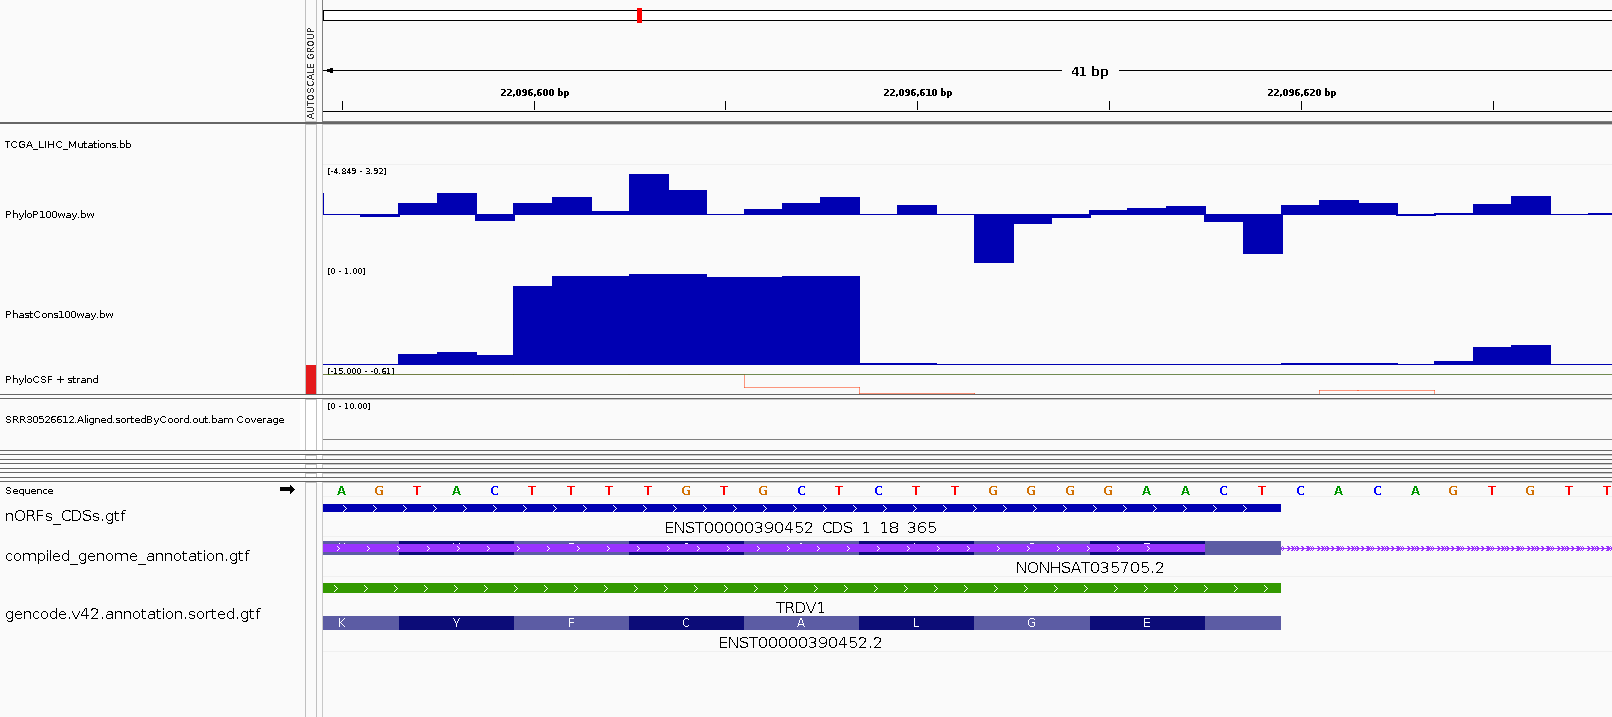

## Download public evolutationary conservation and mutation tracks from UCSC

In [ ]:
# 1. Prepare directories and define tracks
track_dir = subdirs["ext_data_dir"] + "conservation_and_mutations/"
os.makedirs(track_dir, exist_ok=True)

ucsc_base = "http://hgdownload.cse.ucsc.edu/goldenpath/hg38"
broad_base = "https://data.broadinstitute.org/compbio1/PhyloCSFtracks/hg38/latest"
ucsc_gbdb = "http://hgdownload.soe.ucsc.edu/gbdb/hg38"

# Dictionary format: { "TrackName": ("url", "extension") }
tracks_to_download = {
    "PhyloP100way": (f"{ucsc_base}/phyloP100way/hg38.phyloP100way.bw", "bw"),
    "PhastCons100way": (f"{ucsc_base}/phastCons100way/hg38.phastCons100way.bw", "bw"),
    "PhyloP30way": (f"{ucsc_base}/phyloP30way/hg38.phyloP30way.bw", "bw"),
    "PhastCons30way": (f"{ucsc_base}/phastCons30way/hg38.phastCons30way.bw", "bw"),
    
    # Population and Cancer Mutation Tracks (BigBed format)
    "gnomAD_Variants": (f"{ucsc_gbdb}/gnomAD/v3.1.1/genomes.bb", "bb"),
    "TCGA_LIHC_Mutations": (f"{ucsc_gbdb}/gdcCancer/LIHC.bb", "bb"),
    
    # PhyloCSF Power Track
    "PhyloCSF_Power": (f"{broad_base}/PhyloCSFpower.bw", "bw")
}

# Add PhyloCSF frame-specific tracks 
for strand, char in [('plus', '+'), ('minus', '-')]:
    for frame in [1, 2, 3]:
        url_char = "%2B" if char == "+" else "-"
        track_name = f"PhyloCSF{char}{frame}"
        tracks_to_download[track_name] = (f"{broad_base}/PhyloCSF{url_char}{frame}.bw", "bw")

# Generate and print download commands
command = f"mkdir -p {track_dir} && cd {track_dir}\n"
for track_name, (url, ext) in tracks_to_download.items():
    command += f"wget -c -O {track_name}.{ext} {url} \n"

print(command)
# Execute this in bash

## Specify association jobs accounting for track specifics

In [ ]:
# subtract annotated protein-coding CDSs

In [ ]:
organism = "human"

chrom_sizes = pd.read_csv(file_paths[organism + "_chrom_sizes_file"], sep='\t', header=None, names=['chrom', 'size'])
chrom_sizes_dict = dict(zip(chrom_sizes['chrom'], chrom_sizes['size']))

# --- 1. First, calculate the accurate frames just like before ---
cds_df = exons_df.copy()
cds_df['chrom'] = cds_df[0]
cds_df['start_0'] = cds_df[3].astype(int) - 1 
cds_df['end_1'] = cds_df[4].astype(int)
cds_df['strand'] = cds_df[6]

cds_df['length'] = cds_df['end_1'] - cds_df['start_0']
cds_df['sort_key'] = np.where(cds_df['strand'] == '+', cds_df['start_0'], -cds_df['start_0'])
cds_df = cds_df.sort_values(by=['gene_id', 'sort_key'])
cds_df['cum_len'] = cds_df.groupby('gene_id')['length'].cumsum() - cds_df['length']

def get_corrected_phylocsf_track(row):
    chrom = row['chrom']
    strand = row['strand']
    start_0 = row['start_0']
    end_1 = row['end_1']
    cum_len = int(row['cum_len'])
    offset = (3 - (cum_len % 3)) % 3
    
    if strand == '+':
        codon_start_0 = start_0 + offset
        frame = (codon_start_0 % 3) + 1
        return f"PhyloCSF+{frame}"
    elif strand == '-':
        if chrom in chrom_sizes_dict:
            codon_start_1 = end_1 - offset
            frame = ((chrom_sizes_dict[chrom] - codon_start_1) % 3) + 1
            return f"PhyloCSF-{frame}"
    return None

cds_df['phylocsf_track'] = cds_df.apply(get_corrected_phylocsf_track, axis=1)
cds_df.drop(columns=['length', 'sort_key', 'cum_len'], inplace=True)

# -------------------------------------------------------------------------------
bed_jobs_dir = subdirs["temp_dir"] + "conservation_bed_jobs/"
os.makedirs(bed_jobs_dir, exist_ok=True)

In [ ]:
# --- 2. Build the Reference Subtraction BED (OTHER Annotated CDSs) ---
# Parse the main GTF file to get all annotated CDSs
ref_gtf_df, ref_genes_df, ref_exons_df = parse_gtf_attributes_into_pd_dataframes(
    file_paths['ORFs_main_annotation_file'], extract_exon_number=False
)
ref_gtf_df[0] = ('chr'+ref_gtf_df[0].astype('str')).str.replace('chrMT','chrM') # adhere to GENCODE chromosome names

In [ ]:
all_ref_cds = ref_gtf_df[ref_gtf_df[2] == 'CDS'].copy()
all_ref_cds['chrom'] = all_ref_cds[0]
all_ref_cds['start_0'] = all_ref_cds[3].astype(int) - 1
all_ref_cds['end_1'] = all_ref_cds[4].astype(int)
all_ref_cds = all_ref_cds.sort_values(by=['chrom', 'start_0']).reset_index(drop=True)

cds_bed_path = f"{bed_jobs_dir}/annotated_cds.bed"
# Export only coordinates for subtraction
all_ref_cds[['chrom', 'start_0', 'end_1']].to_csv(
    cds_bed_path, sep='\t', header=False, index=False
)

# --- 3. Save raw Target BEDs ---
standard_tracks = [
    "PhyloP100way", "PhastCons100way", "PhyloP30way", "PhastCons30way", 
    "PhyloCSF_Power", "TCGA_LIHC_Mutations"
]

all_tracks_to_process = standard_tracks + ["PhyloCSF_Combined"]

for track in standard_tracks:
    tmp_df = cds_df[['chrom', 'start_0', 'end_1', 'gene_id']].copy()
    tmp_df['track_name'] = track
    tmp_df = tmp_df.sort_values(by=['chrom', 'start_0']).reset_index(drop=True)
    # only select nORF exonic segments - from them, all annotated CDS elements will be subtracted
    tmp_df.loc[~tmp_df['gene_id'].str.contains('_CDS_')].to_csv(f"{bed_jobs_dir}/{track}_raw.bed", sep='\t', header=False, index=False)
    # coding CDS elements should not be subtracted - otherwise they will be nullified
    tmp_df.loc[tmp_df['gene_id'].str.contains('_CDS_')].to_csv(f"{bed_jobs_dir}/{track}_CDS.bed", sep='\t', header=False, index=False)
    
tmp_csf = cds_df.dropna(subset=['phylocsf_track']).sort_values(by=['chrom', 'start_0']).reset_index(drop=True).copy()
tmp_csf = tmp_csf[['chrom', 'start_0', 'end_1', 'gene_id', 'phylocsf_track']]

tmp_csf.loc[~tmp_csf['gene_id'].str.contains('_CDS_')].to_csv(
    f"{bed_jobs_dir}/PhyloCSF_Combined_raw.bed", sep='\t', header=False, index=False
)
tmp_csf.loc[tmp_csf['gene_id'].str.contains('_CDS_')].to_csv(
    f"{bed_jobs_dir}/PhyloCSF_Combined_CDS.bed", sep='\t', header=False, index=False
)


# --- 4. Perform the Bedtools Subtraction ---
for track in all_tracks_to_process:
    raw_bed = f"{bed_jobs_dir}/{track}_raw.bed"
    cds_bed = f"{bed_jobs_dir}/{track}_CDS.bed"
    clean_bed = f"{bed_jobs_dir}/{track}.bed"
    
    # bedtools subtract -a <targets> -b <mask list>
    # This automatically retains columns 4 (gene_id) and 5 (track_name)
    cmd = f"bedtools subtract -a {raw_bed} -b {cds_bed_path} | cat - {cds_bed} > {clean_bed}"
    
    # Execute the command in the shell
    subprocess.run(cmd, shell=True, check=True)

print(f"Generated, filtered, and saved clean BED files for SLURM jobs in {bed_jobs_dir}")

## Prepare .sbatch scripts to calculate various metrics for ORFs

In [ ]:
score_script = os.path.join(os.getcwd(),"analysis_scripts","compute_track_metrics.py")

sbatch_scripts = []
out_tables_dir = os.path.join(subdirs["tables_dir"],"HCC_ORFs","evol_and_genetics_track_scores")
os.makedirs(out_tables_dir, exist_ok=True)

# Add the Unified PhyloCSF track
all_tracks = standard_tracks + ["PhyloCSF_Combined"]

for track in all_tracks:
    sbatch_file_path = subdirs["slurm_scripts_dir"] + f"score_{track}.sbatch"
    
    with open(sbatch_file_path, "w") as f:
        command = f"""#!/bin/bash
#SBATCH --job-name=score_{track}
#SBATCH --time=05:59:00
#SBATCH --qos=6hours
#SBATCH --mem=8G
#SBATCH --cpus-per-task=1
#SBATCH --output={subdirs["slurm_dir"]}/score_{track}.%j.out
#SBATCH --error={subdirs["slurm_dir"]}/score_{track}.%j.err

source activate zavolab_pyutils

python {score_script} \\
    {bed_jobs_dir}/{track}.bed \\
    {track_dir} \\
    {out_tables_dir}/{track}_scores.tsv \\
    {track}
"""
        f.write(command)
    sbatch_scripts.append(sbatch_file_path)

print(";\n".join(["sbatch " + elem for elem in sbatch_scripts]))

In [ ]:
print(out_tables_dir) # here will be the outputs

## Import and parse the quantifications

In [ ]:
# Aggregate the SLURM output TSVs
all_scores_dfs = []
for track in all_tracks:
    res_path = f"{out_tables_dir}/{track}_scores.tsv"
    if os.path.exists(res_path):
        df = pd.read_csv(res_path, sep='\t')
        all_scores_dfs.append(df)

if all_scores_dfs:
    integration_df = all_scores_dfs[0]
    for df in all_scores_dfs[1:]:
        integration_df = pd.merge(integration_df, df, on="Geneid", how="outer")

    # Rename 'Geneid' to match the column name in genes_df 
    integration_df = integration_df.rename(columns={'Geneid': 'gene_id'})

    # Final Merge into the genes_df parsed from your basic annotation GTF
    final_genes_df = pd.merge(genes_df, integration_df, on="gene_id", how="left")
    
    print("Integration of Conservation & Mutation metrics successful!")
    display(final_genes_df.head(3))
else:
    print("No score tables found. Ensure SLURM jobs have completed successfully.")

In [ ]:
print(f'we assigned PhyloP for {len(final_genes_df.loc[~final_genes_df['PhyloP100way_Median'].isna()])}, and PhyloCSF for {len(final_genes_df.loc[~final_genes_df['PhyloCSF_Median'].isna()])} elements')
print(f'we have started with {len(transcript_coords_df)} ORFs and CDSs')

In [ ]:
final_genes_df['ORF_type'] = final_genes_df.apply(lambda x:x['gene_id'].split('_')[1],1)
subset_extract_dict = {1:'with_evidence',0:'no_evidence'}
final_genes_df['subset'] = final_genes_df.apply(lambda x:subset_extract_dict[int(x['gene_id'].split('_')[2])],1)
final_genes_df['ORF_category'] = final_genes_df['ORF_type']+';'+final_genes_df['subset']

## Make plots displaying evolutionary conservation patterns of ORFs

### Overall patterns

In [ ]:
final_genes_df['t']=1
final_genes_df.groupby(['ORF_category']).agg({'t':sum,'TCGA_LIHC_Mutations_Density_per_kb':np.mean}).reset_index()

In [ ]:
out_file = os.path.join(subdirs['tables_dir'],'HCC_ORFs','final_supplementary_tables','nORFs_CDSs_evol_scores_TCGAmutCounts.tsv')

final_genes_df[['gene_id','gene_name','ORF_category','PhyloP100way_Mean',
                            'PhyloP100way_Median',
                           'PhastCons100way_Mean',
                         'PhastCons100way_Median',
                               'PhyloP30way_Mean',
                             'PhyloP30way_Median',
                            'PhastCons30way_Mean',
                          'PhastCons30way_Median',
                            'PhyloCSF_Power_Mean',
                          'PhyloCSF_Power_Median',
                      'TCGA_LIHC_Mutations_Count',
             'TCGA_LIHC_Mutations_Density_per_kb']].to_csv(out_file, sep='\t', index=False)
print(f"Table saved to: {out_file}")

In [ ]:
from scipy.stats import ks_2samp

hue = 'ORF_category'

fig_file_name = 'evol_scores.nORFs_and_CDSs.eCDF.pdf'
hue_order = ['CDS;with_evidence','uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
palette = ['green','orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']

# uncomment the following code to visualize ONLY nORFs
# fig_file_name = 'evol_scores.nORFs_only.pdf'
# hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
# palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']

# KS-test target pairs and their reporting color
ks_pairs = [
    ('uORF;with_evidence', 'uORF;no_evidence', 'orangered'),
    ('dORF;with_evidence', 'dORF;no_evidence', 'royalblue'),
    ('lincRNA;with_evidence', 'lincRNA;no_evidence', 'deeppink'),
    ('RT;with_evidence', 'RT;no_evidence', 'darkviolet')
]

# --- Text Layout Configuration per Feature ---
# Adjust x, start_y, alignments, and step direction (+ for upward, - for downward)
text_layout_config = {
    'PhyloP100way_Median':      {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhastCons100way_Median':   {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06},  # Bottom-right
    'PhyloP30way_Median':       {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhastCons30way_Median':    {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06},  # Bottom-right
    'PhyloCSF_Median': {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhyloCSF_Power_Median': {'x': 0.05, 'start_y': 0.95, 'ha': 'left',  'va': 'top', 'step': -0.06}, # Top-left
    'TCGA_LIHC_Mutations_Density_per_kb': {'x': 0.05, 'start_y': 0.95, 'ha': 'left',  'va': 'top', 'step': -0.06}, # Top-left
}

features = ['PhyloP100way_Median','PhastCons100way_Median','PhyloP30way_Median','PhastCons30way_Median','PhyloCSF_Median','TCGA_LIHC_Mutations_Density_per_kb']
feature_labels = ['PhyloP Median\n100 vertebrates','PhastCons Median\n100 vertebrates','PhyloP Median\n30 primates','PhastCons Median\n30 primates','PhyloCSF Median\n58-mammals','TCGA LIHC Mutations\nDensity per kb']
xlims = [(-1,5),None,(-0.5,1.5),None,None,(-1,10)]

sns.set(font_scale=1, style="white")
fig, axes = plt.subplots(1, len(features), sharey=True, sharex=False, figsize=(2.8*len(features),3.2))

for k, feature in enumerate(features):
    data = final_genes_df.loc[(~final_genes_df[feature].isna())].copy()
    print(f'{len(data)} ORFs for '+feature)
    
    ax = sns.ecdfplot(ax = axes[k],
                      data = data, x = feature, 
                      hue = hue, hue_order = hue_order, palette = palette,
                      alpha=1,
                     )
    
    ax.set(title = '', xlabel = feature_labels[k], ylabel = ('eCDF' if k==0 else ''))
    if xlims[k] is not None:
        ax.set(xlim = xlims[k])
    ax.tick_params(bottom=True, left=(True if k==0 else False))
    
    # --- Dynamic KS-test Annotation ---
    cfg = text_layout_config.get(feature, {'x': 0.95, 'start_y': 0.05, 'ha': 'right', 'va': 'bottom', 'step': 0.06})
    y_pos = cfg['start_y']
    
    for cat_with, cat_no, color in ks_pairs:
        dist_with = data.loc[data[hue] == cat_with, feature]
        dist_no = data.loc[data[hue] == cat_no, feature]
        
        if len(dist_with) > 0 and len(dist_no) > 0:
            stat, p_val = ks_2samp(dist_with, dist_no)
            
            if p_val < 0.001:
                p_text = f"p = {p_val:.2e}"
            else:
                p_text = f"p = {p_val:.3f}"
                
            label = cat_with.split(';')[0]
            text_str = f"{label}: {p_text}"
            
            ax.text(
                cfg['x'], y_pos, text_str, 
                color=color, 
                transform=ax.transAxes, 
                ha=cfg['ha'], 
                va=cfg['va'], 
                fontsize=8,
                weight='semibold'
            )
            # Adjust the vertical position for the next category line
            y_pos += cfg['step']
    # ----------------------------------

    if k < len(features)-1:
        ax.legend_.remove()
    else:
        sns.move_legend(
                    ax, 
                    loc="upper left", 
                    bbox_to_anchor=(1.05, 1), 
                    borderaxespad=0.0, 
                    title='ORF category'
                )

savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.5)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
from scipy.stats import ks_2samp

hue = 'ORF_category'

fig_file_name = 'evol_scores.nORFs_and_CDSs.histogram.pdf'
hue_order = ['CDS;with_evidence','uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
palette = ['green','orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']

# uncomment the following code to visualize ONLY nORFs
# fig_file_name = 'evol_scores.nORFs_only.pdf'
# hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
# palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']

# KS-test target pairs and their reporting color
ks_pairs = [
    ('uORF;with_evidence', 'uORF;no_evidence', 'orangered'),
    ('dORF;with_evidence', 'dORF;no_evidence', 'royalblue'),
    ('lincRNA;with_evidence', 'lincRNA;no_evidence', 'deeppink'),
    ('RT;with_evidence', 'RT;no_evidence', 'darkviolet')
]

# --- Text Layout Configuration per Feature ---
# Adjust x, start_y, alignments, and step direction (+ for upward, - for downward)
text_layout_config = {
    'PhyloP100way_Median':      {'x': 0.95, 'start_y': 0.95, 'ha': 'right',  'va': 'top', 'step': -0.06}, 
    'PhastCons100way_Median':   {'x': 0.5, 'start_y': 0.95, 'ha': 'center',  'va': 'top', 'step': -0.06},
    'PhyloP30way_Median':       {'x': 0.5, 'start_y': 0.95, 'ha': 'center',  'va': 'top', 'step': -0.06},
    'PhastCons30way_Median':    {'x': 0.5, 'start_y': 0.95, 'ha': 'center',  'va': 'top', 'step': -0.06},
    'PhyloCSF_Median': {'x': 0.5, 'start_y': 0.95, 'ha': 'center',  'va': 'top', 'step': -0.06}, 
    'PhyloCSF_Power_Median': {'x': 0.05, 'start_y': 0.95, 'ha': 'left',  'va': 'top', 'step': -0.06}, # Top-left
}

features = ['PhyloP100way_Median','PhastCons100way_Median','PhyloP30way_Median','PhastCons30way_Median','PhyloCSF_Median','TCGA_LIHC_Mutations_Density_per_kb']
feature_labels = ['PhyloP Median\n100 vertebrates','PhastCons Median\n100 vertebrates','PhyloP Median\n30 primates','PhastCons Median\n30 primates','PhyloCSF Median\n58-mammals','TCGA LIHC Mutations\nDensity per kb']

xlims = [(-1,5),None,(-0.5,1.5),None,None,(-1,10)]

sns.set(font_scale=1, style="white")
fig, axes = plt.subplots(1, len(features), sharey=False, sharex=False, figsize=(2.8*len(features),3.2))

for k, feature in enumerate(features):
    data = final_genes_df.loc[(~final_genes_df[feature].isna())].copy()
    print(f'{len(data)} ORFs for '+feature)

    min_val,max_val = data[feature].min(),data[feature].max()
    bin_step = (max_val-min_val)/100
    ax = sns.histplot(ax = axes[k],
                      data = data, x = feature, 
                      hue = hue, hue_order = hue_order, palette = palette,
                      common_norm = False,common_bins=True,element="step",stat="density",
                      bins = np.arange(min_val,max_val+0.01,bin_step),fill=True,
                      alpha=0.05,
                     )
    
    ax.set(title = '', xlabel = feature_labels[k], ylabel = ('density' if k==0 else ''))
    if xlims[k] is not None:
        ax.set(xlim = xlims[k])
    ax.tick_params(bottom=True, left=True)
    
    # --- Dynamic KS-test Annotation ---
    cfg = text_layout_config.get(feature, {'x': 0.95, 'start_y': 0.05, 'ha': 'right', 'va': 'bottom', 'step': 0.06})
    y_pos = cfg['start_y']
    
    for cat_with, cat_no, color in ks_pairs:
        dist_with = data.loc[data[hue] == cat_with, feature]
        dist_no = data.loc[data[hue] == cat_no, feature]
        
        if len(dist_with) > 0 and len(dist_no) > 0:
            stat, p_val = ks_2samp(dist_with, dist_no)
            
            if p_val < 0.001:
                p_text = f"p = {p_val:.2e}"
            else:
                p_text = f"p = {p_val:.3f}"
                
            label = cat_with.split(';')[0]
            text_str = f"{label}: {p_text}"
            
            ax.text(
                cfg['x'], y_pos, text_str, 
                color=color, 
                transform=ax.transAxes, 
                ha=cfg['ha'], 
                va=cfg['va'], 
                fontsize=8,
                weight='semibold'
            )
            # Adjust the vertical position for the next category line
            y_pos += cfg['step']
    # ----------------------------------

    if k < len(features)-1:
        ax.legend_.remove()
    else:
        sns.move_legend(
                    ax, 
                    loc="upper left", 
                    bbox_to_anchor=(1.05, 1), 
                    borderaxespad=0.0, 
                    title='ORF category'
                )

savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.5)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
final_genes_df.loc[(final_genes_df['ORF_category']=='CDS;with_evidence')&(final_genes_df['PhyloCSF_Median']< -8)].head()['gene_name']

In [ ]:
cds_df.loc[cds_df['gene_name'] == 'ENSG00000270099']

some CDSs have wrongly-annotated start codons, which results in low PhyloCSF scores, e.g. here:

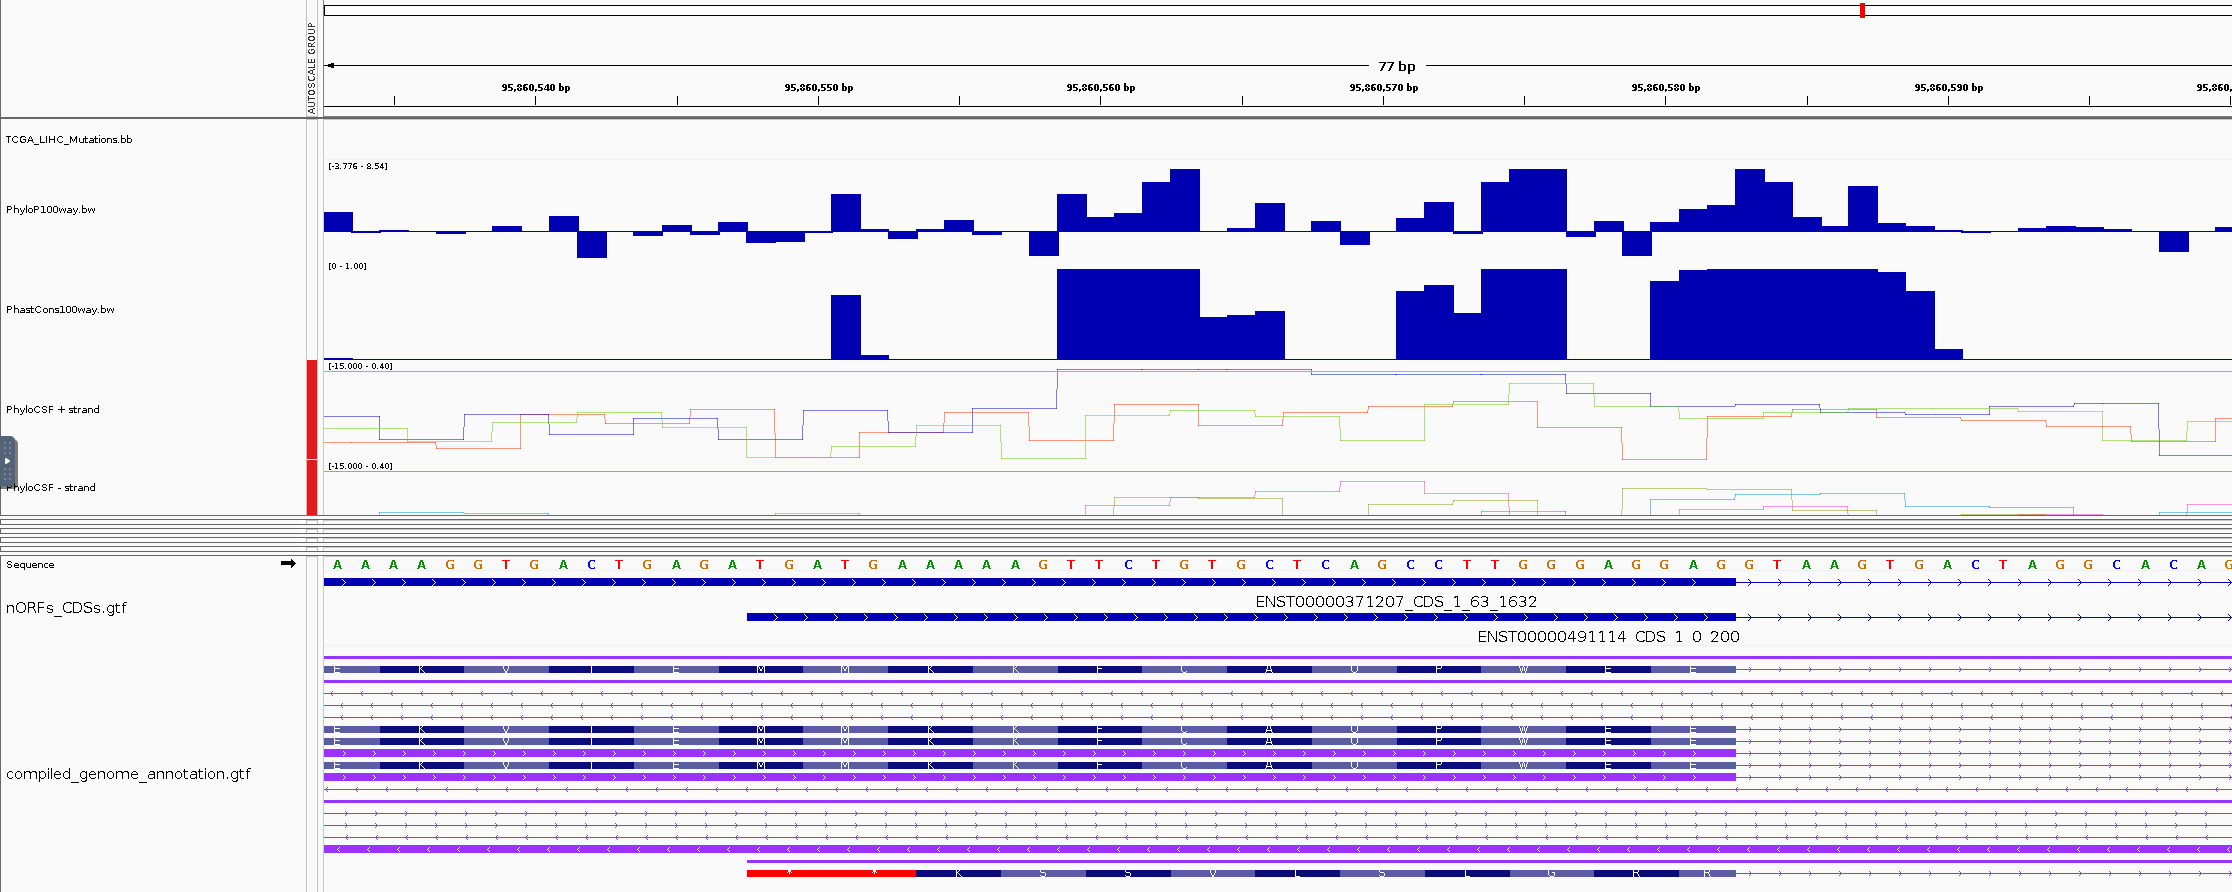

now bin all ORFs into groups by their exonic lengths

### Check most conserved targets 

In [ ]:
sel_targets_df = final_genes_df.loc[(final_genes_df['PhyloCSF_Median']>0.5)&(final_genes_df['ORF_type']!='CDS')].copy()
sel_targets_df['t'] = 1
display(sel_targets_df.groupby(['ORF_category']).agg({'t':sum}).reset_index())

In [ ]:
# define feature_id to allow for joining from the TPM data frames or Deseq outputs
sel_targets_df['Feature_ID'] = sel_targets_df.apply(lambda x:'_'.join(list(pd.Series(x['gene_id'].split('_'))[[0,3,4]])),1)

#### uORFs

In [ ]:
# append results of log2FC of uORF/CDS ratio

tmp1_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_uorf_NonViral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)
tmp2_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_uorf_Viral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)

uORF_targets_df = sel_targets_df.loc[sel_targets_df['ORF_category']=='uORF;with_evidence'][
        [0,3,4,6,8,'Feature_ID','gene_name','PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median','TCGA_LIHC_Mutations_Count']].sort_values('PhyloCSF_Median',ascending=False)

rename_dict = {'log2FoldChange':'log2FoldChange_NONviral','pvalue':'pvalue_NONviral','padj':'padj_NONviral'}
uORF_targets_df = pd.merge(uORF_targets_df,
                           tmp1_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')
rename_dict = {'log2FoldChange':'log2FoldChange_viral','pvalue':'pvalue_viral','padj':'padj_viral'}
uORF_targets_df = pd.merge(uORF_targets_df,
                           tmp2_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')

In [ ]:
uORF_targets_df.head(20)

#### dORFs

In [ ]:
tmp1_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_dorf_NonViral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)
tmp2_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_dorf_Viral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)

dORF_targets_df = sel_targets_df.loc[sel_targets_df['ORF_category']=='dORF;with_evidence'][
        [0,3,4,6,8,'Feature_ID','gene_name','PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median','TCGA_LIHC_Mutations_Count']].sort_values('PhyloCSF_Median',ascending=False)

rename_dict = {'log2FoldChange':'log2FoldChange_NONviral','pvalue':'pvalue_NONviral','padj':'padj_NONviral'}
dORF_targets_df = pd.merge(dORF_targets_df,
                           tmp1_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')
rename_dict = {'log2FoldChange':'log2FoldChange_viral','pvalue':'pvalue_viral','padj':'padj_viral'}
dORF_targets_df = pd.merge(dORF_targets_df,
                           tmp2_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')

In [ ]:
', '.join(list(dORF_targets_df['gene_name'].unique()))

In [ ]:
dORF_targets_df

#### RTs

In [ ]:
tmp1_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_rt_NonViral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)
tmp2_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_rt_Viral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)

RT_targets_df = sel_targets_df.loc[sel_targets_df['ORF_category']=='RT;with_evidence'][
        [0,3,4,6,8,'Feature_ID','gene_name','PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median','TCGA_LIHC_Mutations_Count']].sort_values('PhyloCSF_Median',ascending=False)

rename_dict = {'log2FoldChange':'log2FoldChange_NONviral','pvalue':'pvalue_NONviral','padj':'padj_NONviral'}
RT_targets_df = pd.merge(RT_targets_df,
                           tmp1_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')
rename_dict = {'log2FoldChange':'log2FoldChange_viral','pvalue':'pvalue_viral','padj':'padj_viral'}
RT_targets_df = pd.merge(RT_targets_df,
                           tmp2_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')

In [ ]:
', '.join(list(RT_targets_df['gene_name'].unique()))

In [ ]:
len(RT_targets_df.loc[RT_targets_df['gene_name'].str.len()<10])

In [ ]:
RT_targets_df

#### lincRNAs

In [ ]:
lincRNA_targets_df = final_genes_df.loc[final_genes_df['ORF_category']=='lincRNA;with_evidence'][
        [0,3,4,6,8,'gene_name','PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median','TCGA_LIHC_Mutations_Count']].sort_values('PhyloCSF_Median',ascending=False)
lincRNA_targets_df['tr_form'] = lincRNA_targets_df.apply(lambda x:x[8].split('gene_id "')[1].split('";')[0].split('_lincRNA')[0].replace('.','_'),1)
# lincRNA_targets_df.loc[lincRNA_targets_df['']]

In [ ]:
lincRNA_targets_df.head()

In [ ]:
lincRNA_targets_df.loc[(lincRNA_targets_df[0]=='chr20')&(lincRNA_targets_df[3]>49274065)&(lincRNA_targets_df[4]<49292880)]

In [ ]:
chr11:65,497,177-65,508,384

In [ ]:
lincRNA_targets_df.loc[(lincRNA_targets_df[0]=='chr11')&(lincRNA_targets_df[3]>65497177)&(lincRNA_targets_df[4]<65508384)]

In [ ]:
lincRNA_targets_df.loc[(lincRNA_targets_df[0]=='chr11')&(lincRNA_targets_df[3]>65497177)&(lincRNA_targets_df[4]<65508384)]

### Dependency on ORF length

In [ ]:
# also need to calculate the total exonic length for gene id to normalize
exons_df['len'] = exons_df[4]-exons_df[3]+1
if 'len' in final_genes_df.columns:
    final_genes_df = final_genes_df.drop(['len'],axis = 1)
final_genes_df = pd.merge(final_genes_df,
         exons_df.groupby('gene_id').agg({'len':sum}).reset_index(),
         how='left',on='gene_id')

In [ ]:
# --- Stratifying Length Confounder (Value-based Binning) ---
bin_edges = [0, 50, 100, 300, np.inf]
final_genes_df['len_bin'] = pd.cut(final_genes_df['len'], bins=bin_edges)

unique_bins = sorted(final_genes_df['len_bin'].dropna().unique())
bin_labels = {
    b: f"{max(0, int(b.left))}-{int(b.right) if b.right != np.inf else 'max'}" 
    for b in unique_bins
}

# --- Core Setup Configuration ---
fig_file_name = 'evol_scores.nORFs_only.stratified_by_ORF_length.uORFs_dORFs.pdf'

hue = 'ORF_category'
# hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence','lincRNA;with_evidence','lincRNA;no_evidence']
# palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple','deeppink','pink']
hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence']
palette = ['orangered','orange','royalblue','lightblue']



ks_pairs = [
    ('uORF;with_evidence', 'uORF;no_evidence', 'orangered'),
    ('dORF;with_evidence', 'dORF;no_evidence', 'royalblue'),
    ('lincRNA;with_evidence', 'lincRNA;no_evidence', 'deeppink'),
    ('RT;with_evidence', 'RT;no_evidence', 'darkviolet')
]

text_layout_config = {
    'PhyloP100way_Median':      {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhastCons100way_Median':   {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06},  # Bottom-right
    'PhyloP30way_Median':       {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhastCons30way_Median':    {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06},  # Bottom-right
    'PhyloCSF_Median': {'x': 0.95, 'start_y': 0.05, 'ha': 'right',  'va': 'bottom', 'step': 0.06}, # Bottom-right
    'PhyloCSF_Power_Median': {'x': 0.05, 'start_y': 0.95, 'ha': 'left',  'va': 'top', 'step': -0.06}, # Top-left
}

features = ['PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median']
feature_labels = ['PhyloP Median\n100 vertebrates','PhyloP Median\n30 primates','PhyloCSF Median\n58-mammals','PhyloCSF POWER Median\n58-mammals']
xlims = [(-0.2,2), (-0.2,1.2), (-8,-5), None]

# =========================================================================
# NEW: Global Proportions Normalization (Across Bins per Category)
# =========================================================================
# 1. Get raw counts grid (Rows: Category, Columns: Length Bins)
counts_matrix = final_genes_df.groupby([hue, 'len_bin'], observed=False).size().unstack(fill_value=0)

# 2. Divide each row by its total sum (Normalizes across length bins for every category)
normalized_matrix = counts_matrix.div(counts_matrix.sum(axis=1), axis=0)

# 3. Flatten back into a long-form DataFrame for Seaborn mapping
global_prop_df = normalized_matrix.stack().reset_index(name='proportion')


# --- Initialize 2D Subplot Grid ---
num_rows = len(unique_bins)
num_cols = len(features) + 1  
sns.set(font_scale=1, style="white")

fig, axes = plt.subplots(
    nrows=num_rows, 
    ncols=num_cols, 
    sharey=False,       
    sharex=False,       
    figsize=(3.2 * num_cols, 2.2 * num_rows)
)

# --- Grid Traversal Loop ---
for r, bin_val in enumerate(unique_bins):
    row_data = final_genes_df.loc[final_genes_df['len_bin'] == bin_val]
    row_range_str = bin_labels[bin_val]
    
    # =========================================================================
    # COLUMN 0: Relative Proportion Barplots (Corrected Normalization)
    # =========================================================================
    ax_count = axes[r, 0]
    
    # Filter precalculated global proportions for just this length tier row
    prop_df = global_prop_df[global_prop_df['len_bin'] == bin_val]
    
    sns.barplot(
        ax=ax_count, data=prop_df, x=hue, y='proportion', order=hue_order, palette=palette
    )
    
    ax_count.set_ylim(0, 1.0)
    ax_count.set_ylabel(f"Proportion\n(Len: {row_range_str} bp)", fontsize=9)
    ax_count.set_xlabel("" if r == num_rows - 1 else "")
    ax_count.set_xticklabels([]) 
    ax_count.tick_params(bottom=False, left=True)
    
    # =========================================================================
    # COLUMNS 1 to N: Evolutionary Metric eCDF Subplots
    # =========================================================================
    for c_feat, feature in enumerate(features):
        c = c_feat + 1  
        ax = axes[r, c]
        data = row_data.loc[~row_data[feature].isna()].copy()
        
        sns.ecdfplot(
            ax=ax, data=data, x=feature, 
            hue=hue, hue_order=hue_order, palette=palette, alpha=1
        )
        
        ax.set_ylim(-0.02, 1.02)

        ax.set_ylabel("eCDF" if c == 1 else "")
        ax.set_xlabel(feature_labels[c_feat] if r == num_rows - 1 else "")
        
        if xlims[c_feat] is not None:
            ax.set(xlim=xlims[c_feat])
            
        ax.tick_params(bottom=True, left=True)
        
        # --- Context-Specific KS-test Calculations ---
        cfg = text_layout_config.get(feature, {'x': 0.95, 'start_y': 0.05, 'ha': 'right', 'va': 'bottom', 'step': 0.06})
        y_pos = cfg['start_y']
        
        for cat_with, cat_no, color in ks_pairs:
            dist_with = data.loc[data[hue] == cat_with, feature]
            dist_no = data.loc[data[hue] == cat_no, feature]
            
            if len(dist_with) > 5 and len(dist_no) > 5:
                stat, p_val = ks_2samp(dist_with, dist_no)
                p_text = f"p = {p_val:.2e}" if p_val < 0.001 else f"p = {p_val:.3f}"
                label = cat_with.split(';')[0]
                
                ax.text(
                    cfg['x'], y_pos, f"{label}: {p_text}", 
                    color=color, transform=ax.transAxes, 
                    ha=cfg['ha'], va=cfg['va'], 
                    fontsize=7.5, weight='semibold'
                )
                y_pos += cfg['step']
                
        # --- Legend Sanitization ---
        if r == 0 and c == num_cols - 1:
            sns.move_legend(
                ax, loc="upper left", bbox_to_anchor=(1.05, 1), 
                borderaxespad=0.0, title='ORF category'
            )
        else:
            if ax.legend_ is not None:
                ax.legend_.remove()

# --- File Serialization ---
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
Path(savefig_path).parent.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.6)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

### Juxtaposing conservation of nORF and main CDS

In [ ]:
final_genes_df['host_transcript_id'] = final_genes_df.apply(lambda x:x['gene_id'].split('_')[0],1)

features = ['PhyloP100way_Median','PhyloP30way_Median','PhyloCSF_Median','PhyloCSF_Power_Median']
feature_labels = ['PhyloP Median\n100 vertebrates','PhyloP Median\n30 primates','PhyloCSF Median\n58-mammals','PhyloCSF POWER Median\n58-mammals']

tmp1_df = final_genes_df.loc[final_genes_df['ORF_type'].isin(['uORF', 'dORF','RT'])][['host_transcript_id','gene_id','ORF_type','ORF_category','gene_name']+features]
rename_dict = {}
for elem in features:
    rename_dict[elem] = elem+';nORF'
tmp1_df = tmp1_df.rename(columns=rename_dict)

tmp2_df = final_genes_df.loc[final_genes_df['ORF_type'].isin(['CDS'])][['host_transcript_id']+features]
rename_dict = {}
for elem in features:
    rename_dict[elem] = elem+';CDS'
tmp2_df = tmp2_df.rename(columns=rename_dict)
juxtaposed_df = pd.merge(tmp1_df,tmp2_df,how='left',on='host_transcript_id')

# add transciptomic coordinates to see the dependency on the distance and other factors
nORFs_df['nORF_len'] = nORFs_df['end']-nORFs_df['start']
CDSs_df['CDS_len'] = CDSs_df['end']-CDSs_df['start']

rename_coords_dict = {'start':'start_tx_nORF','end':'end_tx_nORF','custom_transcript_id':'gene_id'}
juxtaposed_df = pd.merge(juxtaposed_df,nORFs_df[['custom_transcript_id','start','end','nORF_len']].rename(columns=rename_coords_dict),how='left',on='gene_id')
rename_coords_dict = {'start':'start_tx_CDS','end':'end_tx_CDS','transcript_id':'host_transcript_id'}
juxtaposed_df = pd.merge(juxtaposed_df,CDSs_df[['transcript_id','start','end','CDS_len']].rename(columns=rename_coords_dict),how='left',on='host_transcript_id')

print(f'check that no artefact is introduced during joining: after: {len(juxtaposed_df)} , before: {len(final_genes_df.loc[final_genes_df['ORF_type'].isin(['uORF', 'dORF'])])}')

juxtaposed_df['distance_to_main_CDS'] = np.nan
orf_base_type = juxtaposed_df['ORF_type']

# Mask 1: Assign uORFs
uorf_mask = (orf_base_type == 'uORF')
juxtaposed_df.loc[uorf_mask, 'distance_to_main_CDS'] = (
    juxtaposed_df.loc[uorf_mask, 'end_tx_nORF'] - juxtaposed_df.loc[uorf_mask, 'start_tx_CDS']
)

# Mask 2: Assign dORFs and RTs
dorf_rt_mask = orf_base_type.isin(['dORF', 'RT'])
juxtaposed_df.loc[dorf_rt_mask, 'distance_to_main_CDS'] = (
    juxtaposed_df.loc[dorf_rt_mask, 'start_tx_nORF'] - juxtaposed_df.loc[dorf_rt_mask, 'end_tx_CDS']
)

display(juxtaposed_df.head())

In [ ]:
hue = 'ORF_category'
hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence']
palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple']
xlims = [(-1000,200),(-1000,200),(-10,2500),(-10,2500),(-10,2500),(-10,2500)]
ylims = [(0,800),(0,800),(0,800),(0,800),(0,800),(0,800)]

x_feature,y_feature = 'distance_to_main_CDS','nORF_len'

sns.set(font_scale=1)
sns.set_style("white")
bw_adjust = 1.75

for k,hue_val in enumerate(hue_order):
    data = juxtaposed_df.loc[juxtaposed_df[hue]==hue_val].copy()
    g = sns.jointplot(data = data,
                      height = 3,
                              x=x_feature,y=y_feature,s=10,
                              color = palette[k],
                              alpha=0.3)
    ax = g.ax_joint
    ax = sns.kdeplot(
            data=data,
            x=x_feature,
            y=y_feature,
            fill=False,
        levels=[0.1, 0.25, 0.5],
        cut = 0,
        bw_adjust=bw_adjust,
        color='blue',label='50%, 75%, and 90% 2D contours')
    ax.tick_params(bottom=True,left=True)
    ax.set(xlabel = x_feature+'\n'+hue_val)
    if xlims[k] is not None:
        ax.set(xlim = xlims[k])
    if ylims[k] is not None:
        ax.set(ylim = ylims[k])
    savefig_path = savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs','nORF_rel_location', hue_val+'.png')
    # Create parent directories if they do not exist
    dir_path = Path(savefig_path).parent
    dir_path.mkdir(parents=True, exist_ok=True)
    
    g.savefig(savefig_path, bbox_inches='tight', dpi=600)

**append expression information**

In [ ]:
HCC_RiboSeq_samples_metadata_df = pd.read_csv(os.path.join(subdirs['ext_data_dir'],'HCC_paper_metadata','Suppl_Table_1_forResubmission.xlsx - Ribo-seq Samples.tsv'), index_col=None, header=0,delimiter="\t")

HCC_RiboSeq_samples_metadata_df['Liver disease background'].unique()
etiology_classification_dict = {
    'HCV':'viral',
    'HBV':'viral',
    'NASH':'non-viral',
    'ASH':'non-viral',
    'ASH/NASH':'non-viral'
}
HCC_RiboSeq_samples_metadata_df['etiology'] = HCC_RiboSeq_samples_metadata_df['Liver disease background'].map(etiology_classification_dict)
HCC_RiboSeq_samples_metadata_df['sample_id'] = HCC_RiboSeq_samples_metadata_df['Biobank ID'].str.replace('-','_')
HCC_RiboSeq_samples_metadata_df['sample_type'] = HCC_RiboSeq_samples_metadata_df.apply(lambda x:'NT' if '_NT' in x['sample_id'] else 'T',1)

In [ ]:
subdirs['HCC_nORFs_dir']

In [ ]:
CDS_uORF_dORF_TPM_values_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'CDS_uORF_RT_dORF_TPM_values.tsv'), index_col=None, header=0,delimiter="\t",)
NT_cols_viral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='NT')]['sample_id'])
NT_cols_NONviral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='non-viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='NT')]['sample_id'])

cols = list(CDS_uORF_dORF_TPM_values_df.columns)
NT_cols_viral = [elem for elem in NT_cols_viral if elem in cols]
NT_cols_NONviral = [elem for elem in NT_cols_NONviral if elem in cols]

print('the following non-viral samples were used: '+', '.join(NT_cols_NONviral))
print('the following viral samples were used: '+', '.join(NT_cols_viral))

In [ ]:
# compare TPM in NT samples for viral and non-viral

ORF_types = list(CDS_uORF_dORF_TPM_values_df['Element'].unique())
for ORF_type in ORF_types:
    is_cur_ORF_type = CDS_uORF_dORF_TPM_values_df['Element'] == ORF_type
    
    data = CDS_uORF_dORF_TPM_values_df.loc[is_cur_ORF_type].copy()
    print(f'looking at {len(data)} {ORF_type}s')
    # recalculate TPM to look only at CDSs
    data[NT_cols_viral+NT_cols_NONviral] = data[NT_cols_viral+NT_cols_NONviral].div(data[NT_cols_viral+NT_cols_NONviral].sum(),axis=1)*10**6
    
    expr_feature_viral, expr_feature_NONviral = 'NT_mean_viral_TPM','NT_mean_NONviral_TPM'
    data[expr_feature_viral] = data[NT_cols_viral].mean(axis=1) # at low sample size, mean is more stable than median
    data[expr_feature_NONviral] = data[NT_cols_NONviral].mean(axis=1)
    top_border = np.quantile(data[[expr_feature_viral,expr_feature_NONviral]].mean(axis=1),q=0.99)
    
    data = data.loc[(data[[expr_feature_viral,expr_feature_NONviral]].min(axis=1)>0)&(
        data[[expr_feature_viral,expr_feature_NONviral]].mean(axis=1)<=top_border
    )] # look at a quantifiable subset
    
    # additionally scale to maintain the property of summing up to the same value
    data[expr_feature_viral] = data[expr_feature_viral]/data[expr_feature_viral].sum()*10**6
    data[expr_feature_NONviral] = data[expr_feature_NONviral]/data[expr_feature_NONviral].sum()*10**6

    print(data[[expr_feature_viral,expr_feature_NONviral]].sum())
    print(data[[expr_feature_viral,expr_feature_NONviral]].mean())
    print(data[[expr_feature_viral,expr_feature_NONviral]].median())
    data[[expr_feature_viral,expr_feature_NONviral]] = np.log2(data[[expr_feature_viral,expr_feature_NONviral]])
    
    print(f'left with {len(data)} {ORF_type}s after requiring quantifiable expression')
    
    x_feature,y_feature = expr_feature_viral,expr_feature_NONviral
    x_label,y_label = 'viral'+'\nmean TO in NT samples,\n'+str(len(data))+' '+ORF_type+'s','non-viral'

    min_value,max_value = min(data[[x_feature,y_feature]].mean(axis=1)),max(data[[x_feature,y_feature]].mean(axis=1))
    g = sns.jointplot(data = data,
                      height = 5,
                              x=x_feature,y=y_feature,s=10,
                              color = 'grey',
                              alpha=0.3,
                     marginal_kws=dict(bins=np.arange(min_value,max_value,(max_value-min_value)/50)),
    )
    ax = g.ax_joint
    ### add diagonal
    R2 = sklearn.metrics.r2_score(y_true=data[y_feature],y_pred=data[x_feature])
    ax = sns.lineplot(data = pd.DataFrame([[ax.get_xlim()[0],ax.get_xlim()[0]],[ax.get_xlim()[1],ax.get_xlim()[1]]],columns=[x_feature,y_feature]),
                      x=x_feature,y=y_feature,color='orange',label='diag'+'\n$R^2='+str(np.round(R2,2))+'$')
    
    ### add contours
    ax = sns.kdeplot(
                    data=data,
                    x=x_feature,
                    y=y_feature,
                    fill=False,
                levels=[0.1, 0.25, 0.5],
                bw_adjust=bw_adjust,
                color='blue',label='50%, 75%, and 90% 2D contours',
                cut = 0,
    )
    top_border_lim = np.quantile(data[[x_feature,y_feature]].mean(axis=1),q=0.95)
    ax.set(xlabel = x_label, ylabel = y_label, 
           # xlim = (0,top_border_lim),ylim = (0,top_border_lim)
          )
    ax.tick_params(bottom=True,left=True)
    
    savefig_path = savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', ORF_type+'s_expression_in_NT.RiboSeq.NONviral_vs_viral.log2_scale.png')
    # Create parent directories if they do not exist
    dir_path = Path(savefig_path).parent
    dir_path.mkdir(parents=True, exist_ok=True)
    
    g.savefig(savefig_path, bbox_inches='tight', dpi=600)

In [ ]:
# now, append TPM values to conservation scores
data = CDS_uORF_dORF_TPM_values_df.copy()
print(f'looking at {len(data)} elements')
# recalculate TPM (to double-check)
data[NT_cols_viral+NT_cols_NONviral] = data[NT_cols_viral+NT_cols_NONviral].div(data[NT_cols_viral+NT_cols_NONviral].sum(),axis=1)*10**6

expr_feature_viral, expr_feature_NONviral = 'NT_mean_viral_TPM','NT_mean_NONviral_TPM'
data[expr_feature_viral] = data[NT_cols_viral].mean(axis=1) # at low sample size, mean is more stable than median
data[expr_feature_NONviral] = data[NT_cols_NONviral].mean(axis=1)
top_border = np.quantile(data[[expr_feature_viral,expr_feature_NONviral]].mean(axis=1),q=0.99)

data = data.loc[(data[[expr_feature_viral,expr_feature_NONviral]].min(axis=1)>0)&(
    data[[expr_feature_viral,expr_feature_NONviral]].mean(axis=1)<=top_border
)] # look at a quantifiable subset, exclude too highly expressed and too lowly expressed elements

# additionally re-scale to maintain the property of summing up to the same value
data[expr_feature_viral] = data[expr_feature_viral]/data[expr_feature_viral].sum()*10**6
data[expr_feature_NONviral] = data[expr_feature_NONviral]/data[expr_feature_NONviral].sum()*10**6

In [ ]:
rename_dict = {'feature_id':'host_transcript_id',expr_feature_viral:expr_feature_viral+';CDS',expr_feature_NONviral:expr_feature_NONviral+';CDS'}
juxtaposed_df = pd.merge(juxtaposed_df,
    data.loc[data['Element']=='CDS'][['feature_id',expr_feature_viral, expr_feature_NONviral]].rename(columns=rename_dict),
         how='left',on='host_transcript_id')

In [ ]:
# define feature_id to allow for joining from the TPM data frame
juxtaposed_df['feature_id'] = juxtaposed_df.apply(lambda x:'_'.join(list(pd.Series(x['gene_id'].split('_'))[[0,3,4]])),1)

In [ ]:
rename_dict = {expr_feature_viral:expr_feature_viral+';nORF',expr_feature_NONviral:expr_feature_NONviral+';nORF'}
juxtaposed_df = pd.merge(juxtaposed_df,
    data.loc[data['Element']!='CDS'][['feature_id',expr_feature_viral, expr_feature_NONviral]].rename(columns=rename_dict),
         how='left',on='feature_id')

**Note**: for "no_evidence" category, there are no entries for TPM values

In [ ]:
juxtaposed_df.loc[juxtaposed_df['NT_mean_viral_TPM;nORF'].isna()].head()

In [ ]:
len(juxtaposed_df.loc[~juxtaposed_df['NT_mean_viral_TPM;nORF'].isna()])

calculate TPM ratios - those should primarily reflect the intensity of nORF usage

In [ ]:
juxtaposed_df['viral;ratio_log2'] = np.log2(juxtaposed_df[expr_feature_viral+';nORF']/juxtaposed_df[expr_feature_viral+';CDS'])
juxtaposed_df['NONviral;ratio_log2'] = np.log2(juxtaposed_df[expr_feature_NONviral+';nORF']/juxtaposed_df[expr_feature_NONviral+';CDS'])

In [ ]:
juxtaposed_df.loc[~juxtaposed_df['NT_mean_viral_TPM;nORF'].isna()].head()

In [ ]:
features

In [ ]:
# Now see the dependencies of Evolutionary conservation metrics
juxtaposed_df_copy = juxtaposed_df.copy()

hue = 'ORF_category'
hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence']
palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple']

x_features = ['nORF_len','CDS_len','distance_to_main_CDS','NT_mean_NONviral_TPM;CDS','NT_mean_NONviral_TPM;nORF','NONviral;ratio_log2']
x_features = x_features+[elem+';CDS' for elem in features] # add conservation features at CDS for control

sns.set(font_scale=1)
sns.set_style("white")
bw_adjust = 1.75

results_list = []
for x_feature in x_features: # presumable explanatory variables or confounders
    for k1,y_feature in enumerate(features): # those are evolutionary metrics
        y_feature = y_feature+';nORF' # look at nORF
        for k,hue_val in enumerate(hue_order):
            hue_filter = juxtaposed_df_copy[hue] == hue_val
            y_feature_filter = (~juxtaposed_df_copy[y_feature].isna())
            x_feature_filter = (~juxtaposed_df_copy[x_feature].isna())
            
            data = juxtaposed_df_copy.loc[hue_filter & y_feature_filter & x_feature_filter].copy()
            if len(data)>0:
                g = sns.jointplot(data = data,
                                  height = 5,
                                          x=x_feature,y=y_feature,s=10,
                                          color = palette[k],
                                          alpha=0.3,
                                 marginal_kws=dict(bins=20),
                )            
                ax = g.ax_joint            
                ### add contours
                ax = sns.kdeplot(
                                data=data,
                                x=x_feature,
                                y=y_feature,
                                fill=False,
                            levels=[0.1, 0.25, 0.5],
                            bw_adjust=bw_adjust,
                            color='blue',label='50%, 75%, and 90% 2D contours',
                            cut = 0,
                )
                ax.set(xlabel = x_feature+'\n'+hue_val,ylabel = feature_labels[k1]+'\nat nORF', )
                ax.set(
                       xlim = (np.quantile(data[x_feature],q=0.01),np.quantile(data[x_feature],q=0.99)),
                       ylim = (np.quantile(data[y_feature],q=0.01),np.quantile(data[y_feature],q=0.99)),
                )
    
                ax.tick_params(bottom=True,left=True)
                spearman_r = np.round(stats.spearmanr(data[x_feature],data[y_feature])[0],2)
                ax.text(x=ax.get_xlim()[1],y=ax.get_ylim()[1],s=r'$Spearman~corr$ = '+str(spearman_r),ha='right',va='top',size=10,color='red')
    
                pearson_r = np.round(stats.pearsonr(data[x_feature],data[y_feature])[0],2)
                results_list.append([hue_val,y_feature,x_feature,spearman_r,pearson_r])
                savefig_path = savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', 'metric_juxtaposition',hue_val+'_'+y_feature+'_vs_'+x_feature+'.png')
                # Create parent directories if they do not exist
                dir_path = Path(savefig_path).parent
                dir_path.mkdir(parents=True, exist_ok=True)
                
                g.savefig(savefig_path, bbox_inches='tight', dpi=600)

In [ ]:
results_df = pd.DataFrame(results_list,columns = [hue,'y_feature','x_feature','spearman_r','pearson_r'])

In [ ]:
features,feature_labels

In [ ]:
results_df

In [ ]:
sns.set(font_scale=1)
sns.set_style("white")
bw_adjust = 1.75

hue = 'ORF_category'
hue_order = ['uORF;with_evidence','uORF;no_evidence','dORF;with_evidence','dORF;no_evidence','RT;with_evidence','RT;no_evidence']
palette = ['orangered','orange','royalblue','lightblue','darkviolet','mediumpurple']

data = results_df.copy()
x_feature, y_feature = 'spearman_r','x_feature'
x_label,y_label = 'Spearman corr',''

fig, axes = plt.subplots(
    nrows=1, 
    ncols=len(features), 
    sharey=True,       
    sharex=True,       
    figsize=(2.8*len(features), 3.8)
)

# every subplot corresponds to specific y_feature - evolutionary conservation
for k,feature in enumerate(features):
    data = results_df.loc[results_df['y_feature']==feature+';nORF'].copy() # for y-features we only looked at nORF part
    ax = sns.swarmplot(ax=axes[k],data = data,
                              x=x_feature,y=y_feature,s=6,dodge=True,
                           hue = hue, hue_order = hue_order, palette = palette,
                              alpha=0.6,
    )
    ax.tick_params(bottom=True,left=(True if k==0 else False))
    ax.set(xlabel = x_label, ylabel = y_label, title = feature+'\n at nORF')
    ax.vlines(x=0,ymin=ax.get_ylim()[0],ymax=ax.get_ylim()[1],linestyle='--',color='black',lw=1.5)
    if k<len(features)-1:
        ax.legend_.remove()
    else:
        sns.move_legend(
            ax, loc="upper left", bbox_to_anchor=(1.05, 1), 
            borderaxespad=0.0, title='ORF category'
        )
savefig_path = savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs','metric_juxtaposition_analysis.'+x_feature+'.pdf')
# Create parent directories if they do not exist
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.savefig(savefig_path, bbox_inches='tight', dpi=600)

# Analyzing association between nORF/CDS usage and CDS translation repression

In [ ]:
nORFs_df['nORF_len'] = nORFs_df['end']-nORFs_df['start']
CDSs_df['CDS_len'] = CDSs_df['end']-CDSs_df['start']

In [ ]:
genes_df['Feature_ID'] = genes_df.apply(lambda x:'_'.join(list(pd.Series(x['gene_id'].split('_'))[[0,3,4]])),1) # to be able to pd.merge

In [ ]:
genes_df['host_transcript_id'] = genes_df.apply(lambda x:x['gene_id'].split('_')[0],1)

In [ ]:
# for easier rerunning, save all the necessary data tables
(Path(os.path.join(subdirs['temp_dir'], 'for_WLS_models_nORF_CDS_ratio'))).mkdir(parents=True, exist_ok=True) # create subdir, just in case
genes_df.to_csv(os.path.join(subdirs['temp_dir'], 'for_WLS_models_nORF_CDS_ratio','genes_df.tsv'), sep=str('\t'),header=True,index=None,quoting=csv.QUOTE_NONE)
nORFs_df.to_csv(os.path.join(subdirs['temp_dir'], 'for_WLS_models_nORF_CDS_ratio','nORFs_df.tsv'), sep=str('\t'),header=True,index=None,quoting=csv.QUOTE_NONE)
CDSs_df.to_csv(os.path.join(subdirs['temp_dir'], 'for_WLS_models_nORF_CDS_ratio','CDSs_df.tsv'), sep=str('\t'),header=True,index=None,quoting=csv.QUOTE_NONE)
juxtaposed_df_copy.to_csv(os.path.join(subdirs['temp_dir'], 'for_WLS_models_nORF_CDS_ratio','juxtaposed_df_copy.tsv'), sep=str('\t'),header=True,index=None,quoting=csv.QUOTE_NONE)

In [ ]:
Master_MultiOmics_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Master_MultiOmics_Supplementary_Table.tsv'), index_col=None, header=0,delimiter="\t",)

In [ ]:
# Set visual style
sns.set_theme(style="whitegrid")

# # Define absolute translation shifts (from OPP assay)
# opp_shifts = {'NonViral': 1, 'Viral': 2.5}
# global_shift_log2 = np.log2(opp_shifts[etiology_group])

# INITIALIZE TRACKER BEFORE THE LOOP
summary_results = []
decomposition_df_list = []
wls_results_list = []
step6_results_list = []
n_permutations = 2000  # Number of shuffles for the null distribution

etiology_groups = ['NonViral', 'Viral']
nORF_types = ['uORF', 'dORF', 'RT']

quantification_list = [] # to save regressed-out values for later

# -> Remove the [:1] slice so it loops through all 6 conditions
for nORF_type in nORF_types:
    for etiology_group in etiology_groups:
        
        file_path = os.path.join(subdirs['HCC_nORFs_dir'], 'Annotated_'+nORF_type.lower()+'_'+etiology_group+'_CDS_ratio.tsv')
        nORF_ratio_df = pd.read_csv(file_path, sep='\t', header=0)
        nORF_ratio_df = nORF_ratio_df.rename(columns={'log2FoldChange': 'log2FoldChange_nORF_CDS_ratio', 'lfcSE': 'lfcSE_nORF_CDS_ratio'})
        
        # Merge identifiers
        nORF_ratio_df = pd.merge(genes_df[['gene_id', 'gene_name', 'host_transcript_id', 'Feature_ID']], nORF_ratio_df, how='right', on=['Feature_ID'])
        nORF_ratio_df = nORF_ratio_df.dropna(subset=['log2FoldChange_nORF_CDS_ratio', 'lfcSE_nORF_CDS_ratio']).reset_index(drop=True)
        
        tmp_df = Master_MultiOmics_df[['Gene',
                                       etiology_group+'_RNA_log2FC', etiology_group+'_RNA_pvalue',
                                       etiology_group+'_RPF_log2FC', etiology_group+'_RPF_pvalue'
                                       ]].rename(columns={'Gene': 'gene_name',
                                                          etiology_group+'_RPF_log2FC': 'log2FoldChange_CDS', etiology_group+'_RPF_pvalue': 'pval_CDS',
                                                          etiology_group+'_RNA_log2FC': 'log2FoldChange_RNA', etiology_group+'_RNA_pvalue': 'pval_RNA'}).copy()
        
        
        
        # Reverse-engineer lfcSE values
        for metric in ['RNA', 'CDS']:
            tmp_df['W_stat_'+metric] = np.abs(stats.norm.ppf(tmp_df['pval_'+metric] / 2))
            tmp_df['lfcSE_'+metric] = np.abs(tmp_df['log2FoldChange_'+metric]) / tmp_df['W_stat_'+metric]
            tmp_df['lfcSE_'+metric].replace([np.inf, -np.inf], np.nan, inplace=True)
            
        tmp_df = tmp_df.dropna().reset_index(drop=True)
        df = pd.merge(nORF_ratio_df, tmp_df, how='inner', on=['gene_name']) 

        # # append CDS TO in NT samples (possible confounder) - this didn't change, but changed the visualization and dropped out many observations
        # df = pd.merge(df,juxtaposed_df_copy[['gene_id','NT_mean_viral_TPM;CDS','NT_mean_NONviral_TPM;CDS','NT_mean_viral_TPM;nORF','NT_mean_NONviral_TPM;nORF']],how='inner',on='gene_id')
        # df = df.dropna().reset_index(drop=True)
        
        # Confounding factors
        rename_coords_dict = {'start': 'start_tx_nORF', 'end': 'end_tx_nORF', 'custom_transcript_id': 'gene_id'}
        df = pd.merge(df, nORFs_df[['custom_transcript_id', 'start', 'end', 'nORF_len']].rename(columns=rename_coords_dict), how='left', on='gene_id')
        rename_coords_dict = {'start': 'start_tx_CDS', 'end': 'end_tx_CDS', 'transcript_id': 'host_transcript_id'}
        df = pd.merge(df, CDSs_df[['transcript_id', 'start', 'end', 'CDS_len']].rename(columns=rename_coords_dict), how='left', on='host_transcript_id')
        
        if nORF_type == 'uORF':
            df['distance_to_main_CDS'] = df['end_tx_nORF'] - df['start_tx_CDS']
        else:
            df['distance_to_main_CDS'] = df['start_tx_nORF'] - df['end_tx_CDS']
            
        # =====================================================================
        # STEP 1: Rename Variables to Target Nomenclature (U, C, M)
        # =====================================================================
        df['Quant_1'] = df['log2FoldChange_nORF_CDS_ratio']
        df['Quant_2'] = df['log2FoldChange_CDS']
        df['Quant_3'] = df['log2FoldChange_RNA']
        df['SE_1'] = df['lfcSE_nORF_CDS_ratio']
        df['SE_2'] = df['lfcSE_CDS']
        df['SE_3'] = df['lfcSE_RNA']

        # U: uORF Ribo-seq change (Reconstructed)
        df['U_obs'] = df['Quant_1'] + df['Quant_2']
        df['U_se'] = np.sqrt(df['SE_1']**2 + df['SE_2']**2)

        # C: CDS Ribo-seq change
        df['C_obs'] = df['Quant_2']
        df['C_se'] = df['SE_2']

        # M: mRNA RNA-seq change
        df['M_obs'] = df['Quant_3']
        df['M_se'] = df['SE_3']
        
        U_obs, C_obs, M_obs = df['U_obs'].values, df['C_obs'].values, df['M_obs'].values
        
        # Calculate Ratios and TE for downstream steps
        Ratio_obs = df['Quant_1'].values  # U_obs - C_obs
        TE_obs = C_obs - M_obs
        print(f"\n==============================================================================")
        print(f" STATISTICAL DECOMPOSITION: {etiology_group} | {nORF_type} (n = {len(df)})")
        print(f"==============================================================================")
        # =====================================================================
        # STEP 2: Show Cov(U, C) is small relative to Var(U) and Var(C)
        # =====================================================================
        var_U = np.var(U_obs, ddof=1)
        var_C = np.var(C_obs, ddof=1)
        cov_UC = np.cov(U_obs, C_obs)[0, 1]
        
        print(f"\n--- STEP 2: Variance vs Covariance ---")
        print(f"Var(U): {var_U:.4f}")
        print(f"Var(C): {var_C:.4f}")
        print(f"Cov(U, C): {cov_UC:.4f}")
        print(f"Ratio of Cov(U,C) to Var(U): {cov_UC/var_U:.2f}")
        
        # =====================================================================
        # STEP 3: Empirical vs Permuted Correlation (Driven by Cov(U, TE))
        # =====================================================================
        
        # Calculate the core covariance driver
        cov_U_TE = np.cov(U_obs, TE_obs)[0, 1]
        
        # 1. Calculate Observed Pearson Correlation
        obs_corr, _ = stats.pearsonr(Ratio_obs, TE_obs)
        
        # 2. Generate Permuted Null Distribution
        shuffled_corrs = np.zeros(n_permutations)
        U_shuffled = U_obs.copy()
        
        for i in range(n_permutations):
            np.random.shuffle(U_shuffled)
            # Reconstruct the ratio with the shuffled U and the locked C
            ratio_shuffled = U_shuffled - C_obs
            shuffled_corrs[i] = stats.pearsonr(ratio_shuffled, TE_obs)[0]
            
        # 3. Calculate statistics of the null distribution
        mean_shuff = np.mean(shuffled_corrs)
        median_shuff = np.median(shuffled_corrs)
        
        # 4. Calculate the Test Statistics (Delta r)
        diff_mean = obs_corr - mean_shuff
        diff_median = obs_corr - median_shuff
        
        print(f"\n--- STEP 3: Permutation Testing ---")
        print(f"Cov(U, TE_CDS):              {cov_U_TE:.4f}")
        print(f"Observed Correlation (r):    {obs_corr:.4f}")
        print(f"Mean Null Correlation (r):   {mean_shuff:.4f}")
        print(f"Difference (Obs - Mean Null):{diff_mean:.4f}")
        
        # Store for the final cross-condition scatterplot
        summary_results.append({
            'Condition': f"{etiology_group} | {nORF_type}",
            'Etiology': etiology_group,
            'Type': nORF_type,
            'cov_U_TE': cov_U_TE,
            'obs_corr': obs_corr,
            'diff_mean': diff_mean,
            'diff_median': diff_median
        })

        # =====================================================================
        # STEP 4: Evaluating the Components of the Test Statistic Formula
        # =====================================================================
        
        # 1. Extract covariances and variances
        p = np.cov(U_obs, C_obs)[0, 1]     # Cov(U, C)
        q = np.cov(U_obs, M_obs)[0, 1]     # Cov(U, M)
        s = np.cov(C_obs, M_obs)[0, 1]     # Cov(C, M)
        gamma = np.var(C_obs, ddof=1)      # Var(C)
        v = np.var(U_obs, ddof=1)          # Var(U)
        mu = np.var(M_obs, ddof=1)         # Var(M)
        
        # 2. Calculate Denominators
        D_real_squared = (v + gamma - 2*p) * (gamma + mu - 2*s)
        D_shuff_squared = (v + gamma) * (gamma + mu - 2*s)
        
        D_real = np.sqrt(max(D_real_squared, 1e-10))
        D_shuffle = np.sqrt(max(D_shuff_squared, 1e-10))
        
        # 3. Calculate the k factor
        k = D_shuffle / D_real
        
        # 4. Store the components in the tracking list
        decomposition_df_list.append({
            'Etiology': etiology_group,
            'Type': nORF_type,
            'Cov(U,C)': p,
            'Cov(U,M)': q,
            'k-1': k - 1,
            'Cov(C,M)': s,
            'Var(C)': gamma,
            'D_real': D_real,
            'D_shuffle': D_shuffle,
            'k': k
        })
        
        print(f"\n--- STEP 4: Mathematical Components of Delta r ---")
        print(f"Cov(U, C):       {p:.4f}")
        print(f"Cov(U, M):       {q:.4f}")
        print(f"Cov(C, M):       {s:.4f}")
        print(f"Var(C):          {gamma:.4f}")
        print(f"D_real:          {D_real:.4f}")
        print(f"k factor:        {k:.4f} (k-1 = {k-1:.4f})")

        # =====================================================================
        # STEP 5: The Unbiased Null Hypothesis (WLS Linear Model)
        # =====================================================================
        # 1. Orthogonalize U on M (U_indep)
        X_M_U = sm.add_constant(df['M_obs'])
        wls_U_on_M = sm.WLS(df['U_obs'], X_M_U, weights=1.0/(df['U_se']**2+df['M_se']**2)).fit()
        df['U_indep'] = wls_U_on_M.resid
        
        # 2. Orthogonalize C on M (C_indep)
        X_M_C = sm.add_constant(df['M_obs'])
        wls_C_on_M = sm.WLS(df['C_obs'], X_M_C, weights=1.0/(df['C_se']**2+df['M_se']**2)).fit()
        df['C_indep'] = wls_C_on_M.resid
        
        # Standardize confounders
        # etiology_label_dict = {'NonViral':'NONviral', 'Viral':'viral'}
        # features = ['nORF_len', 'CDS_len', 'distance_to_main_CDS','NT_mean_'+etiology_label_dict[etiology_group]+'_TPM;CDS']
        features = ['nORF_len', 'CDS_len', 'distance_to_main_CDS']
        scaler = StandardScaler()
        df[['nORF_len_z', 'CDS_len_z', 'dist_z']] = scaler.fit_transform(df[features])
        
        # 3. Final Main Model: C_indep vs U_indep + Confounders
        Y_main = df['C_indep']
        X_main = sm.add_constant(df[['U_indep', 'nORF_len_z', 'CDS_len_z', 'dist_z']])
        
        # The variance of C_indep is dominated by C_se
        wls_main_model = sm.WLS(Y_main, X_main, weights=1.0/(df['C_se']**2+df['U_se']**2+2*(df['M_se']**2))).fit()
        
        print(f"\n--- STEP 5: Unbiased WLS Linear Model ---")
        print(wls_main_model.summary())

        # =====================================================================
        # COLLECT WLS MODEL METRICS
        # =====================================================================
        wls_results_list.append({
            'Etiology': etiology_group,
            'Type': nORF_type,
            'U_on_M_R2_adj': wls_U_on_M.rsquared_adj,
            'U_on_M_slope': wls_U_on_M.params['M_obs'],
            'U_on_M_pval': wls_U_on_M.pvalues['M_obs'],
            'C_on_M_R2_adj': wls_C_on_M.rsquared_adj,
            'C_on_M_slope': wls_C_on_M.params['M_obs'],
            'C_on_M_pval': wls_C_on_M.pvalues['M_obs'],
            'Final_WLS_R2_adj': wls_main_model.rsquared_adj,
            'Final_WLS_slope': wls_main_model.params['U_indep'],
            'Final_WLS_pval': wls_main_model.pvalues['U_indep']
        })

        # save U_indep and C_indep
        df['etiology_group'] = etiology_group
        quantification_list.append(df[['gene_id','U_indep','C_indep','etiology_group']])
        
        # =====================================================================
        # STEP 6: Empirical WLS (Ratio_indep vs C_indep) and Mechanistic Breakdown
        # =====================================================================
        # 1. Calculate the RNA-independent ratio
        df['Ratio_indep'] = df['U_indep'] - df['C_indep']
        
        # 2. Run the empirical WLS model
        weights_final = 1.0 / (df['C_se']**2 + df['U_se']**2 + 2*(df['M_se']**2))
        X_ratio_indep = sm.add_constant(df['Ratio_indep'])
        wls_step6_model = sm.WLS(df['C_indep'], X_ratio_indep, weights=weights_final).fit()
        
        # 3. Extract components for mechanistic breakdown
        beta_U = wls_main_model.params['U_indep']
        beta_0 = wls_main_model.params['const']
        epsilon = wls_main_model.resid
        
        # Calculate standard variances and covariances
        var_U_indep = np.var(df['U_indep'], ddof=1)
        var_epsilon = np.var(epsilon, ddof=1)
        
        # Double check that U_indep and epsilon are uncorrelated
        cov_U_indep_epsilon = np.cov(df['U_indep'], epsilon)[0, 1]
        
        # Calculate the mechanistic terms of the covariance numerator
        positive_biology_term = beta_U * (1.0 - beta_U) * var_U_indep
        spurious_penalty_term = -var_epsilon
        
        # Theoretical and Empirical Slopes
        theoretical_slope = beta_U / (1.0 - beta_U)
        empirical_slope = wls_step6_model.params['Ratio_indep']
        
        step6_results_list.append({
            'Etiology': etiology_group,
            'Type': nORF_type,
            'Var(U_indep)': var_U_indep,
            'Var(epsilon)': var_epsilon,
            'Cov(U_indep, epsilon)': cov_U_indep_epsilon,  # <-- Added here
            'Pos_Bio_Numerator': positive_biology_term,
            'Spurious_Penalty': spurious_penalty_term,
            'Theoretical_Slope': theoretical_slope,
            'Empirical_Slope': empirical_slope
        })
        
        # =====================================================================
        # PLOTTING THE 5-STEP PIPELINE
        # =====================================================================
        fig, axes = plt.subplots(3, 2, figsize=(12, 12))
        fig.suptitle(f'Statistical Decomposition: {etiology_group} | {nORF_type}', fontsize=16, y=1.02)
        
        # -------------------------------------------------------------------------
        # Plot 1 (Step 2): Scatterplot of U vs C with 2D Contours
        # -------------------------------------------------------------------------
        ax1 = axes[0, 0]
        
        # 1. Base scatterplot
        x_feature,y_feature = 'U_obs','C_obs'
        sns.scatterplot(data = df, x=x_feature, y=y_feature, alpha=0.2, s=15, color='gray', ax=ax1)
        
        # 2. Add 2D KDE Contours
        sns.kdeplot(
            data = df,
            x=x_feature,
            y=y_feature,
            fill=False,
            levels=[0.1, 0.25, 0.5],
            cut=0,
            color='blue',
            ax=ax1,
            label='50%, 75%, and 90% contours'
        )
        # 3. Add diagonal
        xlims,ylims = ax1.get_xlim(),ax1.get_ylim()
        min_val,max_val = min(xlims[0],ylims[0]),max(xlims[1],ylims[1])
        sns.lineplot(ax = ax1, data = pd.DataFrame([[min_val,min_val],[max_val,max_val]],columns=[x_feature,y_feature]),
                                      x=x_feature,y=y_feature,color='orange',label='diag')
        # 3. Formatting and labels
        ax1.set_title(f'Step 2: U vs C (Cov = {cov_UC:.3f})')
        ax1.set_xlabel('U_obs (Change in '+nORF_type+' Ribo-seq)')
        ax1.set_ylabel('C_obs (Change in CDS Ribo-seq)')
        ax1.axhline(0, color='black', linestyle='--', linewidth=1)
        ax1.axvline(0, color='black', linestyle='--', linewidth=1)
        ax1.tick_params(bottom=True,left=True)
        ax1.legend(loc='lower right', frameon=True)
        
        # -------------------------------------------------------------------------
        # Plot 2 (Step 3): Histogram of Null Distribution vs Observed Correlation
        # -------------------------------------------------------------------------
        ax2 = axes[0, 1]
        sns.histplot(shuffled_corrs, bins=50, color='lightgray', edgecolor='darkgray', stat='density', kde=True, ax=ax2)
        
        # Add vertical lines for Observed and Mean
        ax2.axvline(obs_corr, color='red', linestyle='-', linewidth=2, label=f'Observed r = {obs_corr:.3f}')
        ax2.axvline(mean_shuff, color='blue', linestyle='--', linewidth=2, label=f'Null Mean = {mean_shuff:.3f}')
        
        ax2.set_title('Step 3: Empirical vs Null Correlation Distribution')
        ax2.set_xlabel('Pearson r (Ratio vs TE_CDS)')
        ax2.set_ylabel('Density')
        ax2.tick_params(bottom=True,left=True)
        ax2.legend(bbox_to_anchor=(1.05, 1),loc=2,borderaxespad=0.0,title='')
        
        # Add text box linking Cov(U, TE) to the Delta
        textstr2 = (f'Cov(U, TE) = {cov_U_TE:.4f}\n'
                    f'Δ Mean = {diff_mean:.4f}\n'
                    f'Δ Median = {diff_median:.4f}')
        ax2.text(0.05, 0.95, textstr2, transform=ax2.transAxes, fontsize=11, verticalalignment='top', 
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='red'))


        # -------------------------------------------------------------------------
        # Plot 3 (Step 3b): Empirical Ratio vs CDS TE (Visualizing obs_corr)
        # -------------------------------------------------------------------------
        ax3b = axes[1, 0]
        sns.scatterplot(x=Ratio_obs, y=TE_obs, alpha=0.2, s=15, color='purple', ax=ax3b)
        sns.kdeplot(x=Ratio_obs, y=TE_obs, fill=False, levels=[0.1, 0.25, 0.5], cut=0, color='blue', ax=ax3b, label='50%, 75%, 90% contours')
        sns.regplot(x=Ratio_obs, y=TE_obs, scatter=False, color='red', ax=ax3b)
        ax3b.set_title(f'Step 3b: Empirical Ratio vs CDS TE (r = {obs_corr:.3f})')
        ax3b.set_xlabel('Ratio_obs ('+nORF_type+'/CDS Ratio Change)')
        ax3b.set_ylabel('TE_obs\n(CDS Translation Efficiency Change)')
        ax3b.axhline(0, color='black', linestyle='--', linewidth=1)
        ax3b.axvline(0, color='black', linestyle='--', linewidth=1)
        ax3b.tick_params(bottom=True,left=True)
        ax3b.legend(loc='lower left', frameon=True)
        
        # Plot 3 (Step 4): RNA vs CDS Ribo-seq (Visualizing the beta slope)
        ax3 = axes[1, 1]
        sns.scatterplot(x=M_obs, y=C_obs, alpha=0.3, s=15, color='teal', ax=ax3)
        sns.regplot(x=M_obs, y=C_obs, scatter=False, color='black', ax=ax3)
        
        # Draw the theoretical beta=1 line
        min_M, max_M = np.min(M_obs), np.max(M_obs)
        ax3.plot([min_M, max_M], [min_M, max_M], color='red', linestyle='--', linewidth=2, label='Slope = 1.0 (Theoretical)')
        
        ax3.set_xlabel('M_obs (Change in RNA)')
        ax3.set_ylabel('C_obs (Change in CDS Ribo-seq)')
        ax3.tick_params(bottom=True,left=True)
        ax3.legend()
        
        # -------------------------------------------------------------------------
        # Plot 4 (Step 5): The Unbiased WLS Result
        # -------------------------------------------------------------------------
        ax4 = axes[2, 0]
        
        # 1. Extract the exact slope and intercept from the WLS model
        beta_U = wls_main_model.params['U_indep']
        intercept_U = wls_main_model.params['const']
        
        # 2. Add the WLS weights to the dataframe for plotting
        df['WLS_Weight'] = 1.0 / (df['C_se']**2 + df['U_se']**2 + 2 * (df['M_se']**2))
        
        # 3. Base scatterplot (Points scaled by their respective WLS weight)
        sns.scatterplot(
            data=df,
            x='U_indep', 
            y='C_indep', 
            size='WLS_Weight', 
            sizes=(5, 150),      # Control the minimum and maximum point sizes
            alpha=0.3, 
            color='darkorange', 
            ax=ax4,
            legend=False         # Suppress the size legend to avoid visual clutter
        )
        sns.kdeplot(data = df, x='U_indep', y='C_indep', fill=False, levels=[0.1, 0.25, 0.5], cut=0, color='blue', ax=ax4, label='50%, 75%, 90% contours')
        
        # 4. Draw the exact multidimensional WLS regression line (partial effect)
        x_vals = np.array([df['U_indep'].min(), df['U_indep'].max()])
        y_vals_wls = intercept_U + beta_U * x_vals
        ax4.plot(x_vals, y_vals_wls, color='black', linewidth=2, label=f'WLS Fit (Slope = {beta_U:.3f})')
        
        # 5. Add the 1:1 diagonal for comparison
        xlims_4, ylims_4 = ax4.get_xlim(), ax4.get_ylim()
        min_val_4, max_val_4 = min(xlims_4[0], ylims_4[0]), max(xlims_4[1], ylims_4[1])
        ax4.plot([min_val_4, max_val_4], [min_val_4, max_val_4], color='orange', linestyle='--', linewidth=2, label='diag')
        
        # 6. Formatting and labels
        ax4.set_title(f'Step 5: Unbiased Coupling (WLS \u03B2_U = {beta_U:.3f})')
        ax4.set_xlabel(f'U_indep ({nORF_type} Ribo-seq independent of RNA)')
        ax4.set_ylabel('C_indep (CDS Ribo-seq independent of RNA)')
        ax4.tick_params(bottom=True, left=True)
        ax4.axhline(0, color='gray', linestyle='--', linewidth=1)
        ax4.axvline(0, color='gray', linestyle='--', linewidth=1)
        ax4.legend(loc='lower right', frameon=True)
        
        # -------------------------------------------------------------------------
        # Plot 6 (Step 6): Theoretical vs Empirical Lines
        # -------------------------------------------------------------------------
        ax6 = axes[2, 1]
        
        # Base scatterplot
        df['WLS_Weight_Ratio'] = weights_final
        sns.scatterplot(
            data=df,
            x='Ratio_indep', 
            y='C_indep', 
            size='WLS_Weight_Ratio', 
            sizes=(5, 150),
            alpha=0.3, 
            color='purple', 
            ax=ax6,
            legend=False
        )
        sns.kdeplot(data=df, x='Ratio_indep', y='C_indep', fill=False, levels=[0.1, 0.25, 0.5], cut=0, color='blue', ax=ax6)
        
        x_vals_ratio = np.array([df['Ratio_indep'].min(), df['Ratio_indep'].max()])
        
        # Line 1: Theoretical (The true biological relationship without epsilon noise)
        theoretical_intercept = beta_0 / (1.0 - beta_U)
        y_vals_theoretical = theoretical_intercept + theoretical_slope * x_vals_ratio
        ax6.plot(x_vals_ratio, y_vals_theoretical, color='black', linestyle='--', linewidth=2, label=f'Theoretical (\u03B2={theoretical_slope:.3f})')
        
        # Line 2: Empirical (The corrupted relationship caused by -Var(epsilon))
        empirical_intercept = wls_step6_model.params['const']
        y_vals_empirical = empirical_intercept + empirical_slope * x_vals_ratio
        ax6.plot(x_vals_ratio, y_vals_empirical, color='red', linestyle='-', linewidth=2, label=f'Empirical (\u03B2={empirical_slope:.3f})')
        
        # Formatting
        ax6.set_title(f'Step 6: Endogeneity Bias Breakdown')
        ax6.set_xlabel('Ratio_indep (RNA-independent uORF/CDS Ratio)')
        ax6.set_ylabel('C_indep (RNA-independent CDS TO)')
        ax6.tick_params(bottom=True, left=True)
        ax6.axhline(0, color='gray', linestyle='--', linewidth=1)
        ax6.axvline(0, color='gray', linestyle='--', linewidth=1)
        ax6.legend(loc='lower left', frameon=True)
        
        plt.tight_layout()
        plt.show()        

In [ ]:
quantification_df = pd.concat(quantification_list).reset_index(drop=True)

In [ ]:
# =====================================================================
# COMPILE FINAL DATAFRAMES
# =====================================================================

# Compile the Step 4 Math Decomposition into a DataFrame
decomposition_df = pd.DataFrame(decomposition_df_list)

In [ ]:
decomposition_df['coupling between nORF with TE changes'] = (decomposition_df['Cov(U,C)'] - decomposition_df['Cov(U,M)'])/decomposition_df['D_real']
decomposition_df['Denominator Bias'] = decomposition_df['k-1']*(decomposition_df['Cov(C,M)'] - decomposition_df['Var(C)'])/(decomposition_df['k']*decomposition_df['D_real'])
display(decomposition_df)

In [ ]:
# Compile the WLS Metrics into a DataFrame
wls_df = pd.DataFrame(wls_results_list)
display(wls_df)

In [ ]:
print(wls_df.to_string(index=False))

In [ ]:
# Set visual style
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    nrows=1, 
    ncols=1, 
    sharey=True,       
    sharex=True,       
    figsize=(6.2, 4.2)
)
wls_df['Final_WLS_R2_adj'] = np.round(wls_df['Final_WLS_R2_adj'], 2)

# Added 'style' and 'markers' parameters
ax = sns.scatterplot(
    data=wls_df, 
    x='C_on_M_slope', 
    y='Final_WLS_slope',
    size='Final_WLS_R2_adj',
    sizes=(50, 150),
    hue='Type',
    style='Etiology',                           # Maps marker shapes to Etiology
    markers={'NonViral': 'o', 'Viral': 'X'}     # 'o' = circle, 'X' = cross
)

ax.set(xlabel = '$\\beta_M^C$\ncoupling between CDS TO changes\nand RNA changes',ylabel = '$\\beta_U$ final WLS,\ncoupling between nORF and CDS,\nindependent from RNA')

# Note: Seaborn merges Hue, Size, and Style into a single legend automatically.
# Removed the overarching title since the legend now contains multiple categories.
sns.move_legend(
    ax, loc="upper left", bbox_to_anchor=(1.05, 1), 
    borderaxespad=0.0
)
ax.tick_params(bottom=True,left=True)
plt.tight_layout() # Ensures the external legend isn't cut off when saving/showing
plt.show()

In [ ]:
# Print Step 6 Troubleshooting Table
step6_df = pd.DataFrame(step6_results_list)
display(step6_df)
print(step6_df.to_string(index=False))

In [ ]:
# =====================================================================
# GLOBAL SUMMARY PLOT (Run after the main nested loops finish)
# =====================================================================

# Convert tracked results into a DataFrame
summary_df = pd.DataFrame(summary_results)

# Initialize the plot
plt.figure(figsize=(10, 5))

# Create a scatterplot mapping markers to nORF type and colors to Etiology
sns.scatterplot(
    data=summary_df, 
    x='cov_U_TE', 
    y='diff_mean', 
    hue='Etiology', 
    style='Type', 
    s=100,          # Marker size
    alpha=0.9,
    palette=['#4C72B0', '#C44E52'] # Distinct colors for Viral/NonViral
)

# Fit a linear regression line across all points to prove the mathematical dependency
sns.regplot(
    data=summary_df, 
    x='cov_U_TE', 
    y='diff_mean', 
    scatter=False, 
    color='gray', 
    line_kws={'linestyle': '--', 'linewidth': 1.5}
)

# Label points with their specific condition for easy reading
for i, row in summary_df.iterrows():
    plt.text(row['cov_U_TE'] + 0.002, row['diff_mean'] - 0.005, 
             f"{row['Type']}\n({row['Etiology']})", 
             fontsize=9, color='black')

# Formatting
plt.title('Global Meta-Analysis: Test Statistic ($\Delta r$) follows Cov(U, TE)', fontsize=14, pad=15)
plt.xlabel('[Covariance(U, TE_CDS)]', fontsize=12)
plt.ylabel('Test Statistic \n[$\Delta$ Pearson r (Observed - Null Mean)]', fontsize=12)

# Draw origin axes
plt.axhline(0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
plt.axvline(0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)

plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

plt.show()

In [ ]:
# Define parameters for the control
etiology_groups = ['NonViral', 'Viral']
sample_sizes = {'uORF_mimic (N=6500)': 6500, 'dORF_mimic (N=380)': 380, 'RT_mimic (N=300)': 300}
n_iterations = 1000  # Number of random draws to estimate the variance of the slope

control_results = []

for etiology_group in etiology_groups:
    print(f"Processing Control for {etiology_group}...")
    
    # 1. Extract and prep data from Master_MultiOmics_df
    tmp_df = Master_MultiOmics_df[['Gene',
                                   etiology_group+'_RNA_log2FC', etiology_group+'_RNA_pvalue',
                                   etiology_group+'_RPF_log2FC', etiology_group+'_RPF_pvalue'
                                  ]].rename(columns={
                                      'Gene': 'gene_name',
                                      etiology_group+'_RPF_log2FC': 'C_obs',
                                      etiology_group+'_RPF_pvalue': 'pval_CDS',
                                      etiology_group+'_RNA_log2FC': 'M_obs',
                                      etiology_group+'_RNA_pvalue': 'pval_RNA'
                                  }).copy()
    
    # 2. Reverse-engineer standard errors exactly as in the main script
    for metric, obs_col, pval_col in [('CDS', 'C_obs', 'pval_CDS'), ('RNA', 'M_obs', 'pval_RNA')]:
        tmp_df['W_stat_'+metric] = np.abs(stats.norm.ppf(tmp_df[pval_col] / 2))
        tmp_df[metric+'_se'] = np.abs(tmp_df[obs_col]) / tmp_df['W_stat_'+metric]
        tmp_df[metric+'_se'].replace([np.inf, -np.inf], np.nan, inplace=True)
        
    tmp_df = tmp_df.dropna().reset_index(drop=True)
    total_genes = len(tmp_df)
    
    # 3. Helper function to run the specific 1b WLS model
    def run_wls(data):
        X = sm.add_constant(data['M_obs'])
        Y = data['C_obs']
        # Exact weights used in your updated 1b model
        weights = 1.0 / (data['CDS_se']**2 + data['RNA_se']**2)
        model = sm.WLS(Y, X, weights=weights).fit()
        return model.params['M_obs'], model.rsquared_adj
    
    # 4. Run on FULL background dataset
    full_slope, full_r2 = run_wls(tmp_df)
    control_results.append({
        'Etiology': etiology_group,
        'Subset': 'Full Transcriptome',
        'N': total_genes,
        'Expected_Slope': full_slope,
        'Slope_2p5perc_q': full_slope,
        'Slope_97p5perc_q': full_slope,
        'R2_adj': full_r2,
        'R2_adj_2p5perc_q': full_r2,
        'R2_adj_97p5perc_q': full_r2,
    })
    
    # 5. Run on Random Subsets (100 iterations each)
    for size_name, n_genes in sample_sizes.items():
        if n_genes > total_genes:
            continue
            
        slopes = []
        r2s = []
        for _ in range(n_iterations):
            sample_df = tmp_df.sample(n=n_genes)
            s, r2 = run_wls(sample_df)
            slopes.append(s)
            r2s.append(r2)
            
        control_results.append({
            'Etiology': etiology_group,
            'Subset': size_name,
            'N': n_genes,
            'Expected_Slope': np.mean(slopes),
            'Slope_2p5perc_q': np.quantile(slopes,q=0.025),
            'Slope_97p5perc_q': np.quantile(slopes,q=0.975),
            'R2_adj': np.mean(r2s),
            'R2_adj_2p5perc_q': np.quantile(r2s,q=0.025),
            'R2_adj_97p5perc_q': np.quantile(r2s,q=0.975),
        })

# 6. Compile results
control_df = pd.DataFrame(control_results)

In [ ]:
display(control_df)
print(control_df.to_string(index=False))

# Prioritize nORF targets

In [ ]:
final_genes_df['Feature_ID'] = final_genes_df.apply(lambda x:'_'.join(list(pd.Series(x['gene_id'].split('_'))[[0,3,4]])),1)

In [ ]:
tmp1_df = quantification_df.loc[quantification_df['etiology_group']=='NonViral']
rename_dict = {'U_indep':'U_indep_NONviral','C_indep':'C_indep_NONviral'}
tmp1_df = tmp1_df.rename(columns=rename_dict).drop(['etiology_group'],axis=1)

tmp2_df = quantification_df.loc[quantification_df['etiology_group']=='Viral']
rename_dict = {'U_indep':'U_indep_viral','C_indep':'C_indep_viral'}
tmp2_df = tmp2_df.rename(columns=rename_dict).drop(['etiology_group'],axis=1)

In [ ]:
juxtaposed_df_copy = juxtaposed_df.copy()
juxtaposed_df_copy = pd.merge(final_genes_df[['gene_id','Feature_ID',0,3,4,6,8,'TCGA_LIHC_Mutations_Count']],juxtaposed_df_copy,how='right',on='gene_id')
juxtaposed_df_copy = pd.merge(juxtaposed_df_copy,tmp1_df,how='left',on='gene_id')
juxtaposed_df_copy = pd.merge(juxtaposed_df_copy,tmp2_df,how='left',on='gene_id')

In [ ]:
# save so that we could further easier upload the table, without the need to run the whole notebook
(Path(os.path.join(subdirs['temp_dir'], 'target_prioritization'))).mkdir(parents=True, exist_ok=True) # create subdir, just in case
juxtaposed_df_copy.to_csv(os.path.join(subdirs['temp_dir'], 'target_prioritization','juxtaposed_df_copy.tsv'), sep=str('\t'),header=True,index=None,quoting=csv.QUOTE_NONE)

**we can start with the following code**. We've saved the necessary data frames in the previous cells.

In [ ]:
juxtaposed_df_copy = pd.read_csv(os.path.join(subdirs['temp_dir'], 'target_prioritization','juxtaposed_df_copy.tsv'), index_col=None, header=0,delimiter="\t",)
Master_MultiOmics_Supplementary_Table_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Master_MultiOmics_Supplementary_Table.tsv'), index_col=None, header=0,delimiter="\t")

In [ ]:
CDS_uORF_dORF_TPM_values_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'CDS_uORF_RT_dORF_TPM_values.tsv'), index_col=None, header=0,delimiter="\t",)

In [ ]:
TCGA_RNA_TPM_df = pd.read_csv(os.path.join(subdirs['HCC_TCGA_EXPR_dir'],'nORF_CDS_expression_matrix.TPM_fragment_counts.July2026.tsv'), index_col=None, header=0,delimiter="\t",)

In [ ]:
TCGA_sample_metadata_df = pd.read_csv(os.path.join(subdirs['tables_dir'],'HCC_ORFs','metadata','Suppl_Table_1_forResubmission.xlsx - TCGA Samples.tsv'), index_col=None, header=0,delimiter="\t",)

In [ ]:
# for selection of expressed targets (not necessarily cancer-specifc), look at the juxtaposition of nORF TPM and ratio to CDS
data = juxtaposed_df_copy.copy()

x_feature, y_feature = 'NT_mean_NONviral_TPM;nORF','NONviral;ratio_log2'
x_label,y_label = '',''


sns.set(font_scale=1)
sns.set_style("white")
bw_adjust = 1.75

fig, axes = plt.subplots(
    nrows=1, 
    ncols=1, 
    sharey=True, 
    sharex=True,       
    figsize=(3.8, 3.8)
)

ax = sns.scatterplot(data = data, x=x_feature,y=y_feature,s=6,alpha=0.3)
ax.set(xlim = (-1,250))

#### uORFs

In [ ]:
# append results of log2FC of uORF/CDS ratio

tmp1_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_uorf_NonViral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)
tmp2_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'Annotated_uorf_Viral_CDS_ratio.tsv'), index_col=None, header=0,delimiter="\t",)

uORF_targets_df = juxtaposed_df_copy.loc[juxtaposed_df_copy['ORF_type']=='uORF'][['gene_id','Feature_ID','0','3','4','6','gene_name','host_transcript_id','TCGA_LIHC_Mutations_Count',
                                                                                                     'NT_mean_NONviral_TPM;nORF','NT_mean_NONviral_TPM;CDS','NONviral;ratio_log2','PhyloP100way_Median;nORF','PhyloCSF_Median;nORF','PhyloCSF_Power_Median;CDS',
                                                                                                     'nORF_len','CDS_len','distance_to_main_CDS','U_indep_NONviral','C_indep_NONviral','U_indep_viral','C_indep_viral']]
rename_dict = {'log2FoldChange':'log2FoldChange_NONviral','pvalue':'pvalue_NONviral','padj':'padj_NONviral'}
uORF_targets_df = pd.merge(uORF_targets_df,
                           tmp1_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')
rename_dict = {'log2FoldChange':'log2FoldChange_viral','pvalue':'pvalue_viral','padj':'padj_viral'}
uORF_targets_df = pd.merge(uORF_targets_df,
                           tmp2_df[['Feature_ID','log2FoldChange','pvalue','padj']].rename(columns = rename_dict),
                          how='left',on='Feature_ID')

Prioritization using pvalue_NONviral from delta TE-like test for uORF/CDS ratio change - **discarded**

In [ ]:
sel_nORFs =  (uORF_targets_df['pvalue_NONviral'] < 0.05) & (uORF_targets_df['NT_mean_NONviral_TPM;nORF'] > 30) & (uORF_targets_df['NT_mean_NONviral_TPM;nORF'] > 30) & (uORF_targets_df['PhyloP100way_Median;nORF'] > 1) # PhyloP=1 corresponds to ~25% quantile of true CDSs
selection = uORF_targets_df.loc[sel_nORFs].sort_values('NT_mean_NONviral_TPM;nORF',ascending=False)
print(len(selection))
print(', '.join(list(selection['gene_name'].unique())))
# display(selection.loc[selection['gene_name'].isin(['MAT2A'])])
display(selection)

sns.set(font_scale=1)
sns.set_style("white")
bw_adjust = 1.75

fig, axes = plt.subplots(
    nrows=1, 
    ncols=1, 
    sharey=True,       
    sharex=True,       
    figsize=(3.8, 3.8)
)
x_feature,y_feature = 'U_indep_NONviral','C_indep_NONviral'
ax = sns.scatterplot(data = selection, x=x_feature,y=y_feature,s=10,alpha=1)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.axvline(0, color='gray', linestyle='--', linewidth=1)

```fasta
>uORF1
ATGGCGTATTAG
>uORF2
ATGGCGCTTCTCACGGCATTCAGCAGCAGCGTTGCTGTAACCGACAAAGACACCTTCGAATTAAGCACATTCCTCGATTCCAGCAAAGCACCGCAACATGACCGAAATGAGCTTCCTGAGCAGCGAGGTGTTGGTGGGGGACTTGATGTCCCCCTTCGACCAGTCGGGTTTGGGGGCTG
ATGTAG
```

In [ ]:
# get per-sample metrics
HCC_RiboSeq_samples_metadata_df = pd.read_csv(os.path.join(subdirs['ext_data_dir'],'HCC_paper_metadata','Suppl_Table_1_forResubmission_Ribo_seq_Samples.tsv'), index_col=None, header=0,delimiter="\t")

HCC_RiboSeq_samples_metadata_df['Liver disease background'].unique()
etiology_classification_dict = {
    'HCV':'viral',
    'HBV':'viral',
    'NASH':'non-viral',
    'ASH':'non-viral',
    'ASH/NASH':'non-viral'
}
HCC_RiboSeq_samples_metadata_df['etiology'] = HCC_RiboSeq_samples_metadata_df['Liver disease background'].map(etiology_classification_dict)
HCC_RiboSeq_samples_metadata_df['sample_id'] = HCC_RiboSeq_samples_metadata_df['Biobank ID'].str.replace('-','_')
HCC_RiboSeq_samples_metadata_df['sample_type'] = HCC_RiboSeq_samples_metadata_df.apply(lambda x:'NT' if '_NT' in x['sample_id'] else 'T',1)

CDS_uORF_dORF_TPM_values_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'CDS_uORF_RT_dORF_TPM_values.tsv'), index_col=None, header=0,delimiter="\t",)
cols = list(CDS_uORF_dORF_TPM_values_df.columns)

NT_cols_viral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='NT')]['sample_id'])
NT_cols_NONviral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='non-viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='NT')]['sample_id'])

NT_cols_viral = [elem for elem in NT_cols_viral if elem in cols]
NT_cols_NONviral = [elem for elem in NT_cols_NONviral if elem in cols]+['P275_NT_35mins_normal'] # append manually with non-conformed sample names

T_cols_viral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='T')]['sample_id'])
T_cols_NONviral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='non-viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='T')]['sample_id'])

T_cols_viral = [elem for elem in T_cols_viral if elem in cols]
T_cols_NONviral = [elem for elem in T_cols_NONviral if elem in cols]+['AG043_02'] # append manually with non-conformed sample names

print('the following non-viral NT samples were used: '+', '.join(NT_cols_NONviral))
print('the following viral NT samples were used: '+', '.join(NT_cols_viral))

print('the following non-viral T samples were used: '+', '.join(T_cols_NONviral))
print('the following viral T samples were used: '+', '.join(T_cols_viral))

In [ ]:
# calculate uORF/CDS ratio in samples for ATF4
sel_samples = ['P167_HCC','P167_NT','P275_HCC','P275_NT_35mins_normal','AG043_02','P296_NT','P379_HCC','P379_NT','P380_HCC','P380_NT']
# sel_samples = NT_cols_NONviral+NT_cols_viral+T_cols_NONviral+T_cols_viral
tmp1 = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id']=='ENST00000404241_676_856'].iloc[0]
tmp2 = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id']=='ENST00000404241'].iloc[0]
df = pd.concat([tmp1,tmp2],axis=1)
df.columns = ['nORF','CDS']
df = df.loc[sel_samples]
df['ratio'] = df['nORF']/df['CDS']
df['log2_ratio'] = np.round(np.log2(df['ratio'].astype('float')),2)
df['log2_TO'] = np.round(np.log2(df['CDS'].astype('float')),1)
df

Run quantification of uORFs in parallel in SLURM jobs

In [ ]:
import os

total_chunks = 100
screen_script = os.path.join(os.getcwd(), "analysis_scripts", "screen_uorfs_eiv.py")
input_data = os.path.join(subdirs['HCC_nORFs_dir'],'CDS_uORF_RT_dORF_TPM_values.tsv')
meta_data = os.path.join(subdirs["ext_data_dir"], "HCC_paper_metadata", "Suppl_Table_1_forResubmission_Ribo_seq_Samples.tsv") 

out_tables_dir = os.path.join(subdirs["tables_dir"], "HCC_ORFs", "bayesian_eiv_screen")
os.makedirs(out_tables_dir, exist_ok=True)

sbatch_file_path = os.path.join(subdirs["slurm_scripts_dir"], "eiv_screen_array.sbatch")

with open(sbatch_file_path, "w") as f:
    # Note: Slurm array is 0-indexed (0 to 99) to match Python's 0-indexed list logic
    command = f"""#!/bin/bash
#SBATCH --job-name=eiv_screen_array
#SBATCH --time=05:59:00
#SBATCH --qos=6hours
#SBATCH --mem=16G
#SBATCH --cpus-per-task=4
#SBATCH --output={subdirs["slurm_dir"]}/eiv_screen_%A_%a.out
#SBATCH --error={subdirs["slurm_dir"]}/eiv_screen_%A_%a.err
#SBATCH --array=0-{total_chunks - 1}

source activate zavolab_pyutils

# Map the Slurm Array Task ID directly to the chunk_id
CHUNK_ID=$SLURM_ARRAY_TASK_ID

echo "Processing chunk $CHUNK_ID out of {total_chunks}"

python {screen_script} \\
    --input {input_data} \\
    --meta {meta_data} \\
    --output {out_tables_dir}/chunk_${{CHUNK_ID}}_results.tsv \\
    --chunk_id ${{CHUNK_ID}} \\
    --total_chunks {total_chunks} \\
    --cores $SLURM_CPUS_PER_TASK
"""
    f.write(command)

print(f"sbatch {sbatch_file_path}")

In [ ]:
# when all jobs are ready, load the results

In [ ]:
import pandas as pd
import glob

results_files = glob.glob(os.path.join(out_tables_dir, "chunk_*_results.tsv"))
merged_df = pd.concat((pd.read_csv(f, sep='\t') for f in results_files), ignore_index=True)
merged_df.to_csv(os.path.join(out_tables_dir, "final_bayesian_uorf_screen.tsv"), sep='\t', index=False)

In [ ]:
# attach information about periodicity across samples
uORF_master_pvalue_matrix_df = pd.read_csv(os.path.join(subdirs["tables_dir"], "HCC_ORFs", "quantifications",'uORF_master_pvalue_matrix.tsv'), index_col=None, header=0,delimiter="\t")
cols = list(uORF_master_pvalue_matrix_df.columns)
# uORF_master_pvalue_matrix_df[cols[1:]] = uORF_master_pvalue_matrix_df[cols[1:]].fillna(0.5)
uORF_master_pvalue_matrix_df['pval_geom_mean'] = uORF_master_pvalue_matrix_df[cols[1:]].prod(axis=1)**(1/uORF_master_pvalue_matrix_df[cols[1:]].count(axis=1))
uORF_master_pvalue_matrix_df['number_non_NA'] = uORF_master_pvalue_matrix_df[cols[1:]].count(axis=1)
uORF_master_pvalue_matrix_df['pval_min'] = uORF_master_pvalue_matrix_df[cols[1:]].min(axis=1)
uORF_master_pvalue_matrix_df['pval_max'] = uORF_master_pvalue_matrix_df[cols[1:]].max(axis=1)
uORF_master_pvalue_matrix_df['pval_q75'] = uORF_master_pvalue_matrix_df[cols[1:]].quantile(axis=1,q=0.75,numeric_only=True)
uORF_master_pvalue_matrix_df['pval_q25'] = uORF_master_pvalue_matrix_df[cols[1:]].quantile(axis=1,q=0.25,numeric_only=True)
uORF_master_pvalue_matrix_df['uorf_id'] = uORF_master_pvalue_matrix_df['ORF_ID'].str.replace('_uORF', '', regex=False)

In [ ]:
cds_genes_df = genes_df.loc[genes_df['gene_id'].str.contains('_CDS_')]
cds_genes_df['cds_id'] = cds_genes_df.apply(lambda x:x['gene_id'].split('_CDS')[0],1)
res_df = pd.merge(cds_genes_df[['cds_id','gene_name']],merged_df,how='right',on='cds_id')
res_df = pd.merge(res_df,uORF_master_pvalue_matrix_df[['pval_geom_mean','pval_min', 'pval_max', 'pval_q75', 'pval_q25', 'number_non_NA', 'uorf_id']],how='left',on='uorf_id')
res_df = pd.merge(res_df,juxtaposed_df_copy[['Feature_ID','nORF_len','CDS_len', 'distance_to_main_CDS','PhyloCSF_Median;nORF','PhyloP100way_Median;nORF','PhyloP30way_Median;nORF','TCGA_LIHC_Mutations_Count']],how='left',left_on='uorf_id',right_on = 'Feature_ID')
res_df = res_df.rename(columns = {'PhyloCSF_Median;nORF':'PhyloCSF','PhyloP100way_Median;nORF':'PhyloP100way','PhyloP30way_Median;nORF':'PhyloP30way'}) # for easier visulization

In [ ]:
res_df['nORF_TCGA_LIHC_Mutations_density_per_kb'] = res_df['TCGA_LIHC_Mutations_Count']/res_df['nORF_len']*1000

In [ ]:
len(res_df)

In [ ]:
sns.jointplot(data = res_df, y ='pval_geom_mean', x='number_non_NA',alpha=0.3)

In [ ]:
# apply a cutoff to see only uORFs with sufficient number of samples with RPF support
res_df = res_df.loc[res_df['number_non_NA']>5].reset_index(drop=True)

In [ ]:
len(res_df)

In [ ]:
# calculate all uORF/CDS ratios - to add to supplement

import os
import numpy as np
import pandas as pd

# --- 1. Filter and Prepare the Global TPM Matrix ---
# Define the subset of sample columns
sel_samples = NT_cols_NONviral + NT_cols_viral + T_cols_NONviral + T_cols_viral

# Extract TPMs, set the feature_id as index, and cast to float
tpm_df = CDS_uORF_dORF_TPM_values_df.set_index('feature_id')[sel_samples].astype(float)

# Log2 transform the entire matrix at once, rounding to 2 decimals to match previous code
log2_tpm_df = np.round(np.log2(tpm_df), 2)

# Sanitize zeros (-inf) to NaNs
log2_tpm_df.replace([np.inf, -np.inf], np.nan, inplace=True)

# --- 2. Generate the uORF-to-CDS Mapping ---
# Leverage res_df to safely isolate uORFs (ignoring dORFs) and get their CDS pairs
uorf_mapping = res_df[['uorf_id', 'cds_id', 'gene_name']].drop_duplicates()

# Ensure we only calculate ratios for features that actually exist in the TPM table
valid_uorfs = uorf_mapping[
    uorf_mapping['uorf_id'].isin(log2_tpm_df.index) & 
    uorf_mapping['cds_id'].isin(log2_tpm_df.index)
].copy()

# --- 3. Extract Aligned Matrices & Calculate Ratios ---
# Extract uORF and CDS matrices, forcing the index of BOTH to be the 'uorf_id'
uorf_matrix = log2_tpm_df.loc[valid_uorfs['uorf_id']].set_index(valid_uorfs['uorf_id'])
cds_matrix = log2_tpm_df.loc[valid_uorfs['cds_id']].set_index(valid_uorfs['uorf_id'])

# Vectorized subtraction: log2(uORF TO) - log2(CDS TO)
log2_ratio_matrix = uorf_matrix - cds_matrix

# --- 4. Format and Save the Final Table ---
# Bring the 'uorf_id' out of the index and back into a column
log2_ratio_matrix = log2_ratio_matrix.reset_index()

# Merge the metadata (gene_name, cds_id) back onto the ratio matrix for readability
log2_ratio_matrix = pd.merge(
    valid_uorfs[['uorf_id', 'cds_id', 'gene_name']], 
    log2_ratio_matrix, 
    on='uorf_id', 
    how='right'
)

# Display a preview of the generated table
print("uORF/CDS log2 Ratio Matrix generated successfully:")
print(log2_ratio_matrix.head())
print(f"\nTotal uORFs processed: {log2_ratio_matrix.shape[0]}")

# (Optional) Save to a TSV file in your quantifications directory
out_file = os.path.join(subdirs['tables_dir'],'HCC_ORFs','final_supplementary_tables','uORF_CDS_log2_ratios_All_Samples.tsv')
log2_ratio_matrix.to_csv(out_file, sep='\t', index=False)
print(f"Table saved to: {out_file}")

In [ ]:
len(log2_ratio_matrix)

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from pathlib import Path
from adjustText import adjust_text

# --- 0. Parameters & Data Prep ---
EVR_CUTOFF = 0.85  
PVAL_FEATURE = 'pval_geom_mean'
PLOT_Y = f'neg_log10_{PVAL_FEATURE}'

# Shift coordinate system: map [0, 180) to [-45, 135)
res_df['PC1_Angle_Centered'] = np.where(
    res_df['PC1_Angle'] > 135.0, 
    res_df['PC1_Angle'] - 180.0, 
    res_df['PC1_Angle']
)

target_uorf = 'ENST00000404241_676_856'
res_df['is_target'] = res_df['uorf_id'] == target_uorf

# -log10 transform the periodicity p-value (handling NaNs and 0s)
res_df[PLOT_Y] = -np.log10(np.maximum(res_df[PVAL_FEATURE].fillna(1.0).astype(float), 1e-300))

# Significance mask for annotation purposes
res_df['is_significant_periodicity'] = res_df[PVAL_FEATURE] < 0.05
y_label = r"$-\log_{10}$ (Geometric Mean of Periodicity P-values)"

target_data = res_df[res_df['is_target']]
non_target_df = res_df[~res_df['is_target']]

# Extract clean data for KDE to avoid NaN interpolation artifacts
valid_coords = res_df.dropna(subset=['PC1_Angle_Centered', 'PC1_EVR', PLOT_Y])

def get_top_annotations(df, x_col, y_col, top_n=5):
    top_candidates = df.sort_values(y_col, ascending=False).head(top_n)
    return pd.concat([top_candidates, target_data]).drop_duplicates(subset=['uorf_id'])

# ==========================================
# PLOT 1: Centered Angle vs Periodicity P-val
# ==========================================
sns.set(font_scale=1, style="ticks")
g1 = sns.JointGrid(data=res_df, x='PC1_Angle_Centered', y=PLOT_Y, height=7, ratio=4, space=0.05)

# Reference lines
g1.ax_joint.axvline(45.0, color='grey', linestyle='--', linewidth=1.5, zorder=1)
g1.ax_joint.axvline(0.0, color='grey', linestyle='-.', linewidth=1.5, zorder=1)
g1.ax_joint.axhline(-np.log10(0.05), color='grey', linestyle=':', linewidth=1.5, zorder=1) 

# Scatter
g1.ax_joint.scatter(
    x=non_target_df['PC1_Angle_Centered'], y=non_target_df[PLOT_Y],
    c='darkgrey', s=20, alpha=0.4, edgecolors='none', zorder=2
)

# 2D KDE Contours (90% and 75% Mass)
sns.kdeplot(
    data=valid_coords, x='PC1_Angle_Centered', y=PLOT_Y,
    ax=g1.ax_joint,
    levels=[0.10, 0.25], 
    color="black",
    linewidths=1.2,
    alpha=0.6,
    zorder=4
)

if not target_data.empty:
    g1.ax_joint.scatter(
        x=target_data['PC1_Angle_Centered'], y=target_data[PLOT_Y],
        c='red', s=200, marker='*', edgecolors='black', linewidths=1.0, zorder=5
    )

# Marginals
sns.histplot(data=res_df, x='PC1_Angle_Centered', ax=g1.ax_marg_x, color='darkgrey', bins=100, element='step', fill=False, linewidth=1.5)
sns.histplot(data=res_df, y=PLOT_Y, ax=g1.ax_marg_y, color='darkgrey', bins=100, element='step', fill=False, linewidth=1.5)

# Annotations
to_annotate_g1 = get_top_annotations(valid_coords, 'PC1_Angle_Centered', PLOT_Y, 0)
texts_g1 = []
for _, row in to_annotate_g1.iterrows():
    label = str(row['gene_name']) if pd.notna(row['gene_name']) else str(row['uorf_id'])
    texts_g1.append(g1.ax_joint.text(row['PC1_Angle_Centered'], row[PLOT_Y], label, fontsize=9, weight='semibold', zorder=6))

adjust_text(texts_g1, x=valid_coords['PC1_Angle_Centered'].values, y=valid_coords[PLOT_Y].values, ax=g1.ax_joint, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))

# Formatting
g1.ax_joint.set_xlim(-45, 135)
g1.ax_joint.set_xticks(np.arange(-45, 136, 45))
g1.ax_joint.set_xticklabels([f"{x}°" for x in np.arange(-45, 136, 45)])
g1.ax_joint.set_ylim(bottom=-0.1, top=2.5)

g1.ax_joint.set_xlabel("Centered PC1 Angle (uORF TO vs CDS TO)")
g1.ax_joint.set_ylabel(y_label)

legend_handles_g1 = [
    mlines.Line2D([], [], color='grey', linestyle='--', linewidth=1.5, label='Angle = 45°'),
    mlines.Line2D([], [], color='grey', linestyle='-.', linewidth=1.5, label='Angle = 0°'),
    mlines.Line2D([], [], color='grey', linestyle=':', linewidth=1.5, label='geom. mean p-val = 0.05'),
    mlines.Line2D([], [], color='black', linewidth=1.2, alpha=0.6, label='75% & 90% Density Contours')
]
if not target_data.empty:
    legend_handles_g1.append(mlines.Line2D([], [], color='red', marker='*', linestyle='None', markersize=12, markeredgecolor='black', label='ATF4'))

g1.figure.legend(handles=legend_handles_g1, loc='lower left', bbox_to_anchor=(0.12, 0.1), frameon=True, facecolor='white')
g1.figure.suptitle("PCA Angle vs. Periodicity", weight='semibold', y=1.02, fontsize=14)

out_path_1 = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', "uORF_screen_Angle_vs_Periodicity_JointPlot.pdf")
Path(out_path_1).parent.mkdir(parents=True, exist_ok=True)
g1.savefig(out_path_1, bbox_inches="tight", dpi=600)


# ==========================================
# PLOT 2: EVR vs Periodicity P-val
# ==========================================
sns.set(font_scale=1.1, style="ticks")
g2 = sns.JointGrid(data=res_df, x='PC1_EVR', y=PLOT_Y, height=7, ratio=4, space=0.05)

# Reference lines
g2.ax_joint.axvline(EVR_CUTOFF, color='grey', linestyle='--', linewidth=1.5, zorder=1)
g2.ax_joint.axhline(-np.log10(0.05), color='grey', linestyle=':', linewidth=1.5, zorder=1) 

# Scatter
g2.ax_joint.scatter(
    x=non_target_df['PC1_EVR'], y=non_target_df[PLOT_Y],
    c='darkgrey', s=20, alpha=0.4, edgecolors='none', zorder=2
)

# 2D KDE Contours (90% and 75% Mass)
sns.kdeplot(
    data=valid_coords, x='PC1_EVR', y=PLOT_Y,
    ax=g2.ax_joint,
    levels=[0.10, 0.25], 
    color="black",
    linewidths=1.2,
    alpha=0.6,
    zorder=4
)

if not target_data.empty:
    g2.ax_joint.scatter(
        x=target_data['PC1_EVR'], y=target_data[PLOT_Y],
        c='red', s=200, marker='*', edgecolors='black', linewidths=1.0, zorder=5
    )

# Marginals
sns.histplot(data=res_df, x='PC1_EVR', ax=g2.ax_marg_x, color='darkgrey', bins=100, element='step', fill=False, linewidth=1.5)
sns.histplot(data=res_df, y=PLOT_Y, ax=g2.ax_marg_y, color='darkgrey', bins=100, element='step', fill=False, linewidth=1.5)

# Annotations
to_annotate_g2 = get_top_annotations(valid_coords, 'PC1_EVR', PLOT_Y, 0)
texts_g2 = []
for _, row in to_annotate_g2.iterrows():
    label = str(row['gene_name']) if pd.notna(row['gene_name']) else str(row['uorf_id'])
    texts_g2.append(g2.ax_joint.text(row['PC1_EVR'], row[PLOT_Y], label, fontsize=9, weight='semibold', zorder=6))

adjust_text(texts_g2, x=valid_coords['PC1_EVR'].values, y=valid_coords[PLOT_Y].values, ax=g2.ax_joint, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))

# Formatting
g2.ax_joint.set_xlim(0.45, 1.05)
g2.ax_joint.set_ylim(bottom=-0.1, top=2.5)

g2.ax_joint.set_xlabel("PC1 Explained Variance Ratio (EVR)")
g2.ax_joint.set_ylabel(y_label)

legend_handles_g2 = [
    mlines.Line2D([], [], color='grey', linestyle='--', linewidth=1.5, label=f'EVR Cutoff ({EVR_CUTOFF})'),
    mlines.Line2D([], [], color='grey', linestyle=':', linewidth=1.5, label='geom. mean p-val = 0.05'),
    mlines.Line2D([], [], color='black', linewidth=1.2, alpha=0.6, label='75% & 90% Density Contours')
]
if not target_data.empty:
    legend_handles_g2.append(mlines.Line2D([], [], color='red', marker='*', linestyle='None', markersize=12, markeredgecolor='black', label='ATF4'))

g2.figure.legend(handles=legend_handles_g2, loc='lower left', bbox_to_anchor=(0.12, 0.1), frameon=True, facecolor='white')
g2.figure.suptitle("PCA EVR vs. Periodicity", weight='semibold', y=1.02, fontsize=14)

out_path_2 = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', "uORF_screen_EVR_vs_Periodicity_JointPlot.pdf")
g2.savefig(out_path_2, bbox_inches="tight", dpi=600)

In [ ]:
valid_mwu = res_df['MWU_pval'].notna()
res_df.loc[valid_mwu, 'MWU_FDR'] = multipletests(res_df.loc[valid_mwu, 'MWU_pval'], method='fdr_bh')[1]

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.legend_handler import HandlerTuple
from pathlib import Path
from scipy.stats import ks_2samp

# --- 0. Parameters ---
EVR_CUTOFF = 0.85  
ANGLE_UPPER_CUTOFF = 50.0
ANGLE_LOWER_CUTOFF = 40.0
SELECTED_FEATURE = 'nORF_TCGA_LIHC_Mutations_density_per_kb'  # 'nORF_len', 'CDS_len', 'distance_to_main_CDS'
X_SCALE = 'linear'  # 'log' for lengths, 'symlog' or 'linear' for distance_to_main_CDS

# --- 1. Data Preparation ---
if 'PC1_Angle_Centered' not in res_df.columns:
    res_df['PC1_Angle_Centered'] = np.where(
        res_df['PC1_Angle'] > 135.0, 
        res_df['PC1_Angle'] - 180.0, 
        res_df['PC1_Angle']
    )

mask_evr = res_df['PC1_EVR'] > EVR_CUTOFF
mask_strict_high = (res_df['PC1_EVR'] > EVR_CUTOFF) & (res_df['PC1_Angle_Centered'] > ANGLE_UPPER_CUTOFF)
mask_strict_low = (res_df['PC1_EVR'] > EVR_CUTOFF) & (res_df['PC1_Angle_Centered'] < ANGLE_LOWER_CUTOFF)

clean_df = res_df.dropna(subset=[SELECTED_FEATURE, 'PC1_EVR', 'PC1_Angle_Centered'])

data_global = clean_df[SELECTED_FEATURE].values
data_evr = clean_df.loc[mask_evr, SELECTED_FEATURE].values
data_strict_high = clean_df.loc[mask_strict_high, SELECTED_FEATURE].values
data_strict_low = clean_df.loc[mask_strict_low, SELECTED_FEATURE].values

# Colors mapping
c_global = 'darkgrey'
c_evr = 'dodgerblue'
c_strict_high = 'darkorange'
c_strict_low = 'purple'

# --- 2. Compute Tests (KS and Bootstrap 75th Quantile) ---
def format_pval(p):
    return f"{p:.2e}" if p < 0.001 else f"{p:.3f}"

def bootstrap_q75_diff(x, y, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    obs_diff = np.abs(np.quantile(x, 0.75) - np.quantile(y, 0.75))
    pooled = np.concatenate([x, y])
    n_x, n_y = len(x), len(y)
    
    count = 0
    # Loop guarantees low memory overhead compared to full matrix generation
    for _ in range(n_boot):
        x_b = rng.choice(pooled, size=n_x, replace=True)
        y_b = rng.choice(pooled, size=n_y, replace=True)
        if np.abs(np.quantile(x_b, 0.75) - np.quantile(y_b, 0.75)) >= obs_diff:
            count += 1
            
    return max(count / n_boot, 1/n_boot)

# KS Tests
ks_g_e = ks_2samp(data_global, data_evr).pvalue
ks_g_sh = ks_2samp(data_global, data_strict_high).pvalue
ks_g_sl = ks_2samp(data_global, data_strict_low).pvalue
ks_e_sh = ks_2samp(data_evr, data_strict_high).pvalue
ks_e_sl = ks_2samp(data_evr, data_strict_low).pvalue
ks_sh_sl = ks_2samp(data_strict_high, data_strict_low).pvalue

# Bootstrap Tests
boot_g_e = bootstrap_q75_diff(data_global, data_evr)
boot_g_sh = bootstrap_q75_diff(data_global, data_strict_high)
boot_g_sl = bootstrap_q75_diff(data_global, data_strict_low)
boot_e_sh = bootstrap_q75_diff(data_evr, data_strict_high)
boot_e_sl = bootstrap_q75_diff(data_evr, data_strict_low)
boot_sh_sl = bootstrap_q75_diff(data_strict_high, data_strict_low)

# --- 3. Plotting Configuration ---
sns.set(font_scale=1, style="ticks")
fig, ax = plt.subplots(figsize=(2.8, 2.5))

sns.ecdfplot(data=data_global, ax=ax, color=c_global, linewidth=2, label=f'All uORFs (n={len(data_global)})')
sns.ecdfplot(data=data_evr, ax=ax, color=c_evr, linewidth=2, label=f'EVR > {EVR_CUTOFF} (n={len(data_evr)})')
sns.ecdfplot(data=data_strict_high, ax=ax, color=c_strict_high, linewidth=2, label=f'EVR > {EVR_CUTOFF} & Angle > {ANGLE_UPPER_CUTOFF}° (n={len(data_strict_high)})')
sns.ecdfplot(data=data_strict_low, ax=ax, color=c_strict_low, linewidth=2, label=f'EVR > {EVR_CUTOFF} & Angle < {ANGLE_LOWER_CUTOFF}° (n={len(data_strict_low)})')

# --- 4. Formatting ---
ax.set_xscale(X_SCALE)
ax.set_xlabel(SELECTED_FEATURE.replace('_', ' ').title())
ax.set_ylabel("Cumulative Probability")

ax.axvline(0.0, color='darkgrey', linestyle='--', linewidth=1.5, zorder=1)
ax.axhline(0.75, color='black', linestyle='--', linewidth=1.5, zorder=1)

if X_SCALE == 'log':
    x_min, x_max = data_global.min(), data_global.max()
    ax.set_xlim(left=max(1, x_min * 0.5), right=x_max * 1.5)
elif X_SCALE == 'linear':
    if SELECTED_FEATURE=='PhyloCSF':
        ax.set_xlim(left=-10, right=+3)
    elif SELECTED_FEATURE=='distance_to_main_CDS':
        ax.set_xlim(left=-300, right=150)
    elif SELECTED_FEATURE=='PhyloP100way':
        ax.set_xlim(left=-2, right=+2)
    elif SELECTED_FEATURE=='PhyloP30way':
        ax.set_xlim(left=-2, right=+2)
    elif SELECTED_FEATURE=='neg_log10_pval_geom_mean':
        ax.set_xlim(left=0, right=2)
        ax.set_xlabel(r"$-\log_{10}$ (Geometric Mean of Periodicity P-values)")
        ax.axvline(-np.log10(0.05), color='grey', linestyle=':', linewidth=1.5, zorder=1)
    elif SELECTED_FEATURE=='pval_geom_mean':
        ax.set_xlim(left=-0.01, right=0.3)
        ax.axvline(0.05, color='grey', linestyle=':', linewidth=1.5, zorder=1)
    elif SELECTED_FEATURE=='nORF_len':
        ax.set_xlim(left=0, right=500)
    elif SELECTED_FEATURE=='nORF_TCGA_LIHC_Mutations_density_per_kb':
        ax.set_xlim(left=-0.05, right=10)
        
sns.despine(ax=ax)
main_legend = ax.legend(loc='lower left', bbox_to_anchor=(-0.4, 1.05), frameon=True, facecolor='white', title="Subsets")

# --- 5. Statistical Annotations via Secondary Legend ---
def create_color_pair_handle(c1, c2):
    m1 = mlines.Line2D([], [], color=c1, marker='s', linestyle='None', markersize=9)
    m2 = mlines.Line2D([], [], color=c2, marker='s', linestyle='None', markersize=9)
    return (m1, m2)

stat_handles = [
    create_color_pair_handle(c_global, c_evr),
    create_color_pair_handle(c_global, c_strict_high),
    create_color_pair_handle(c_global, c_strict_low),
    create_color_pair_handle(c_evr, c_strict_high),
    create_color_pair_handle(c_evr, c_strict_low),
    create_color_pair_handle(c_strict_high, c_strict_low)
]

stat_labels = [
    f"KS p={format_pval(ks_g_e)} | Q75 p={format_pval(boot_g_e)}",
    f"KS p={format_pval(ks_g_sh)} | Q75 p={format_pval(boot_g_sh)}",
    f"KS p={format_pval(ks_g_sl)} | Q75 p={format_pval(boot_g_sl)}",
    f"KS p={format_pval(ks_e_sh)} | Q75 p={format_pval(boot_e_sh)}",
    f"KS p={format_pval(ks_e_sl)} | Q75 p={format_pval(boot_e_sl)}",
    f"KS p={format_pval(ks_sh_sl)} | Q75 p={format_pval(boot_sh_sl)}"
]

stats_legend = ax.legend(
    stat_handles, stat_labels,
    handler_map={tuple: HandlerTuple(ndivide=None, pad=0.3)},
    loc='upper left', title="Pairwise Tests\n(KS | 75% Quantile Bootstrap)", 
    bbox_to_anchor=(-0.4, -0.3),
    frameon=True, facecolor='white'
)
ax.add_artist(main_legend)

# --- 6. Saving ---
fig_file_name = f"uORF_screen_ECDF_{SELECTED_FEATURE}.pdf"
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
Path(savefig_path).parent.mkdir(parents=True, exist_ok=True)

fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
len(data_strict_high[data_strict_high>0])/len(data_strict_high)*100, len(data_strict_low[data_strict_low>0])/len(data_strict_low)*100

In [ ]:
# do functional analysis

In [ ]:
repressive_df = clean_df.loc[mask_strict_high]
activating_df = clean_df.loc[mask_strict_low]
print(len(repressive_df),len(activating_df))
repressive_df[['gene_name']].dropna().to_csv(os.path.join(subdirs['tables_dir'],'HCC_ORFs','gene_functional_analysis','repressive_uORFs.txt'), sep=str('\t'),header=False,index=None,quoting=csv.QUOTE_NONE)
activating_df[['gene_name']].dropna().to_csv(os.path.join(subdirs['tables_dir'],'HCC_ORFs','gene_functional_analysis','activating_uORFs.txt'), sep=str('\t'),header=False,index=None,quoting=csv.QUOTE_NONE)
clean_df[['gene_name']].dropna().to_csv(os.path.join(subdirs['tables_dir'],'HCC_ORFs','gene_functional_analysis','background_uORFs.txt'), sep=str('\t'),header=False,index=None,quoting=csv.QUOTE_NONE)

In [ ]:
repressive_df.columns

In [ ]:
s = 'AASS  OTC  OAT  AGXT2  AZIN1  GGT1  ATF4  UCP2  RIMKLB'
repressive_df.loc[repressive_df['gene_name'].isin(s.split('  '))].sort_values('PC1_Angle',ascending=False)

In [ ]:
s = 'ERLEC1  DNAJC10  ERP44  RNASET2  TXNDC16  DNAJB11  PLOD3  VTN  COL12A1  EDEM3  POGLUT2  UGGT1  COL6A3  TMEM43  CES2  COL14A1  COL5A2  PRKCSH  ARSA  APOL1  KNG1  EVA1A  IGFBP5  LAMC1  ADAM10  IGFBP4  COL6A1  ADAMTSL4  PDGFC  GPC3  SERPING1  PRSS23  ITIH2  SPARCL1  SHH  FBN1  FAM20C '
activating_df.loc[activating_df['gene_name'].isin(s.split('  '))].sort_values('MWU_FDR',ascending=True)

In [ ]:
'", "'.join(s.split('  '))

In [ ]:
res_df.loc[res_df['gene_name']=='PLOD3']

In [ ]:
res_df.head()

In [ ]:
res_df.columns

In [ ]:
os.path.join(subdirs['tables_dir'],'HCC_ORFs','final_supplementary_tables','uORF_screen.tsv')

In [ ]:
len(res_df)

In [ ]:
res_df[['gene_name','uorf_id','PC1_Angle_Centered','PC1_EVR',
        'Ratio_Median_Delta', 'MWU_pval', 'MWU_Z_score','MWU_FDR',
       'number_non_NA','pval_geom_mean','nORF_len', 'CDS_len', 'distance_to_main_CDS']].to_csv(os.path.join(subdirs['tables_dir'],'HCC_ORFs','final_supplementary_tables','uORF_screen.tsv'), 
                                                                                               sep=str('\t'),header=True,index=None,quoting=csv.QUOTE_NONE)

In [ ]:
uORF_targets_df.columns

In [ ]:
uORF_targets_df.loc[uORF_targets_df['gene_name']=='PLOD3']

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from pathlib import Path
from adjustText import adjust_text

# --- 0. Parameters ---
EVR_CUTOFF = 0.85  # Play with this value to adjust the significance threshold

# --- 1. Data Transformation ---
# Shift coordinate system: map [0, 180) to [-45, 135)
res_df['PC1_Angle_Centered'] = np.where(
    res_df['PC1_Angle'] > 135.0, 
    res_df['PC1_Angle'] - 180.0, 
    res_df['PC1_Angle']
)

target_uorf = 'ENST00000404241_676_856'
res_df['is_target'] = res_df['uorf_id'] == target_uorf

# Categorization based on Centered PC1 Angle and EVR cutoff
res_df['Category'] = 'Not Significant'
mask_sig = (res_df['PC1_EVR'] > EVR_CUTOFF)
res_df.loc[mask_sig, 'Category'] = f'PC1 EVR > {EVR_CUTOFF}'

counts = res_df['Category'].value_counts()

# --- 2. JointPlot Configuration ---
sns.set(font_scale=1, style="ticks")
g = sns.JointGrid(data=res_df, x='PC1_Angle_Centered', y='PC1_EVR', height=5.5, ratio=4, space=0.05)

# Reference lines
g.ax_joint.axvline(45.0, color='grey', linestyle='--', linewidth=1.5, zorder=1)
g.ax_joint.axvline(0.0, color='grey', linestyle='-.', linewidth=1.5, zorder=1)
g.ax_joint.axhline(EVR_CUTOFF, color='grey', linestyle=':', linewidth=1.5, zorder=1) 

# Render Scatter Layers
sns.scatterplot(
    data=res_df[(res_df['Category'] == 'Not Significant') & (~res_df['is_target'])], 
    x='PC1_Angle_Centered', y='PC1_EVR',
    s=20, color='darkgrey', alpha=0.3, edgecolor='none', zorder=2, ax=g.ax_joint
)

sns.scatterplot(
    data=res_df[(res_df['Category'] != 'Not Significant') & (~res_df['is_target'])], 
    x='PC1_Angle_Centered', y='PC1_EVR',
    s=20, color='dodgerblue', edgecolor='none', linewidth=0.3, alpha=0.3, zorder=3, ax=g.ax_joint
)

target_data = res_df[res_df['is_target']]
if not target_data.empty:
    sns.scatterplot(
        data=target_data, x='PC1_Angle_Centered', y='PC1_EVR',
        s=200, color='red', edgecolor='black', marker='*', zorder=5, ax=g.ax_joint
    )

# Render Marginals
# Top Marginal: Two overlaid unfilled step histograms
sns.histplot(
    data=res_df, x='PC1_Angle_Centered', ax=g.ax_marg_x, 
    color='darkgrey', bins=100, element='step', fill=False, linewidth=1.5,
    stat='density',
)
sns.histplot(
    data=res_df[res_df['PC1_EVR'] > EVR_CUTOFF], x='PC1_Angle_Centered', ax=g.ax_marg_x, 
    color='dodgerblue', bins=100, element='step', fill=False, linewidth=1.5,
    stat='density',
)

# Right Marginal: Standard filled step histogram
sns.histplot(
    data=res_df, y='PC1_EVR', ax=g.ax_marg_y, 
    color='darkgrey', fill=False, linewidth=1.5, bins=100, element='step',
    stat='density',
)

# --- 3. Annotations ---
# Top 10 highest EVR among repressive angle > 45.0

top_candidates = res_df[(res_df['uorf_id'].isin(['ENST00000663595_1_244','ENST00000686225_22_127',]))].sort_values('PC1_EVR', ascending=False).head(5)
sns.scatterplot(
    data=top_candidates, 
    x='PC1_Angle_Centered', y='PC1_EVR',
    s=40, facecolor='none', edgecolor='black', linewidth=0.5, alpha=1, zorder=3, ax=g.ax_joint
)

to_annotate = pd.concat([top_candidates, target_data]).drop_duplicates(subset=['uorf_id'])

texts = []
for _, row in to_annotate.iterrows():
    label = str(row['gene_name']) if pd.notna(row['gene_name']) else str(row['uorf_id'])
    texts.append(g.ax_joint.text(row['PC1_Angle_Centered'], row['PC1_EVR'], label, fontsize=9, weight='semibold', zorder=6))

valid_coords = res_df.dropna(subset=['PC1_Angle_Centered', 'PC1_EVR'])
adjust_text(texts, x=valid_coords['PC1_Angle_Centered'].values, y=valid_coords['PC1_EVR'].values, 
            ax=g.ax_joint, arrowprops=dict(arrowstyle='-', color='black', lw=0.5), expand_points=(1.5, 1.5))

# --- 4. Formatting ---
g.ax_joint.set_xlim(-45, 135)
g.ax_joint.set_xticks(np.arange(-45, 136, 45))
g.ax_joint.set_xticklabels([f"{x}°" for x in np.arange(-45, 136, 45)])

g.ax_joint.set_ylim(0.5, 1.05)
g.ax_joint.set_xlabel("Centered PC1 Angle (uORF TO vs CDS TO)")
g.ax_joint.set_ylabel("PC1 Explained Variance Ratio (EVR)")

# Custom Legend
legend_handles = [
    mlines.Line2D([], [], color='grey', linestyle='--', linewidth=1.5, label='Angle = 45°'),
    mlines.Line2D([], [], color='grey', linestyle='-.', linewidth=1.5, label='Angle = 0°'),
    mlines.Line2D([], [], color='grey', linestyle=':', linewidth=1.5, label=f'EVR Threshold ({EVR_CUTOFF})'),
]
if not target_data.empty:
    legend_handles.append(mlines.Line2D([], [], color='red', marker='*', linestyle='None', markersize=12, markeredgecolor='black', label='ATF4'))

g.figure.legend(handles=legend_handles, loc='lower left', bbox_to_anchor=(0.15, 0.15), frameon=True, facecolor='white')
# g.figure.suptitle("Transcriptome-wide uORF Screen:\nPCA Explained Variance vs. Angle", weight='semibold', y=1.02, fontsize=14)

# --- 5. Saving ---
fig_file_name = "uORF_screen_PCA_Volcano_Angle_JointPlot.pdf"
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

g.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from pathlib import Path
from adjustText import adjust_text
from statsmodels.stats.multitest import multipletests

# --- 0. Parameters ---
EVR_CUTOFF = 0.85  # Significance threshold for PCA Explained Variance Ratio

# --- 1. Data Transformation ---
# Shift coordinate system: map [0, 180) to [-45, 135)
res_df['PC1_Angle_Centered'] = np.where(
    res_df['PC1_Angle'] > 135.0, 
    res_df['PC1_Angle'] - 180.0, 
    res_df['PC1_Angle']
)

target_uorf = 'ENST00000404241_676_856'
res_df['is_target'] = res_df['uorf_id'] == target_uorf

# --- 2. Categorization by PCA EVR and MWU FDR ---
# Calculate MWU FDR for tumor shift
valid_mwu = res_df['MWU_pval'].notna()
res_df.loc[valid_mwu, 'MWU_FDR'] = multipletests(res_df.loc[valid_mwu, 'MWU_pval'], method='fdr_bh')[1]

mask_shift = res_df['MWU_FDR'] < 0.1
mask_evr = res_df['PC1_EVR'] > EVR_CUTOFF

res_df['Category'] = 'Not Significant'
res_df.loc[mask_shift, 'Category'] = 'Shift Only'
res_df.loc[mask_evr, 'Category'] = 'Coupled Only'
res_df.loc[mask_shift & mask_evr, 'Category'] = 'Both'

# Generate dynamic legend labels with exact counts
counts = res_df['Category'].value_counts()
labels = {
    'Not Significant': f"Not Significant (n={counts.get('Not Significant', 0)})",
    'Shift Only': f"T-vs-NT uORF/CDS ratio change [FDR < 0.1] (n={counts.get('Shift Only', 0)})",
    'Coupled Only': f"[EVR > {EVR_CUTOFF}] (n={counts.get('Coupled Only', 0)})",
    'Both': f"Both Criteria Match (n={counts.get('Both', 0)})"
}

plot_config = [
    ('Not Significant', 'darkgrey', 0.3, 10, 2),
    ('Coupled Only', 'dodgerblue', 0.3, 20, 4),
    ('Shift Only', 'green', 0.4, 20, 3),
    ('Both', 'purple', 0.9, 30, 5)
]

# --- 3. JointPlot Configuration ---
sns.set(font_scale=1, style="ticks")
g = sns.JointGrid(data=res_df, x='PC1_Angle_Centered', y='Ratio_Median_Delta', height=3.2, ratio=2, space=0.05)

# Background overlays and crosshairs (Oriented for X=Angle, Y=Shift)
g.ax_joint.axvline(45.0, color='darkgray', linestyle='--', linewidth=1.5, zorder=1)
g.ax_joint.axhline(0, color='grey', linestyle='--', linewidth=1.5, zorder=1)

# Render Scatter Layers
for cat, color, alpha, size, zorder in plot_config:
    subset = res_df[(res_df['Category'] == cat) & (~res_df['is_target'])]
    sns.scatterplot(
        data=subset, x='PC1_Angle_Centered', y='Ratio_Median_Delta',
        s=size, color=color, edgecolor='none',
        linewidth=0.3, alpha=alpha, zorder=zorder, ax=g.ax_joint
    )

# Render Target (ATF4)
target_data = res_df[res_df['is_target']]
if not target_data.empty:
    sns.scatterplot(
        data=target_data, x='PC1_Angle_Centered', y='Ratio_Median_Delta',
        s=200, color='red', edgecolor='black', marker='*', zorder=6, ax=g.ax_joint
    )

# Render Marginals
# Top Marginal (Angle) - Base global density first
sns.histplot(
    data=res_df, x='PC1_Angle_Centered', ax=g.ax_marg_x, 
    color='darkgrey', bins=40, element='step', fill=False, linewidth=1.5, stat='density'
)
# Add targeted marginal densities
for cat, color, _, _, _ in plot_config[1:4]: # Skip 'Not Significant' to match global base
    subset = res_df[res_df['Category'] == cat]
    if not subset.empty:
        sns.histplot(
            data=subset, x='PC1_Angle_Centered', ax=g.ax_marg_x, 
            color=color, bins=40, element='step', 
            kde = (True if len(subset)<100 else False),
            alpha = (0 if len(subset)<100 else 1),
            fill=False, linewidth=1, stat='density'
        )

# Right Marginal (Shift) - Base global density first
sns.histplot(
    data=res_df, y='Ratio_Median_Delta', ax=g.ax_marg_y, 
    color='darkgrey', bins=40, element='step', fill=False, linewidth=1.5, stat='density'
)
# Add targeted marginal densities
for cat, color, _, _, _ in plot_config[1:4]:
    subset = res_df[res_df['Category'] == cat]
    if not subset.empty:
        sns.histplot(
            data=subset, y='Ratio_Median_Delta', ax=g.ax_marg_y, 
            color=color, bins=40, element='step', 
            kde = (True if len(subset)<100 else False),
            alpha = (0 if len(subset)<100 else 1),
            fill=False, linewidth=1.5, stat='density'
        )

# --- 4. Annotations ---
# Rank top candidates from BOTH significance categories by highest EVR
sig_df = res_df[res_df['Category'] == 'Both'].copy()
# top_candidates = sig_df.sort_values('Ratio_Median_Delta', ascending=False).head(10)
top_candidates = res_df[(res_df['uorf_id'].isin(['ENST00000663595_1_244','ENST00000686225_22_127']))].sort_values('PC1_EVR', ascending=False)
to_annotate = pd.concat([top_candidates, target_data]).drop_duplicates(subset=['uorf_id'])
# also depict top candidates
if not top_candidates.empty:
    for cat, color, alpha, size, zorder in plot_config:
        subset = top_candidates[(top_candidates['Category'] == cat) & (~top_candidates['is_target'])]
        sns.scatterplot(
            data=subset, x='PC1_Angle_Centered', y='Ratio_Median_Delta',
            s=size, facecolor=color, edgecolor='black',
            linewidth=0.5, alpha=1, zorder=6, ax=g.ax_joint
        )

texts = []
for _, row in to_annotate.iterrows():
    label = str(row['gene_name']) if pd.notna(row['gene_name']) else str(row['uorf_id'])
    texts.append(g.ax_joint.text(row['PC1_Angle_Centered'], row['Ratio_Median_Delta'], label, fontsize=9, weight='semibold', zorder=7))

valid_coords = res_df.dropna(subset=['PC1_Angle_Centered', 'Ratio_Median_Delta'])
adjust_text(texts, x=valid_coords['PC1_Angle_Centered'].values, y=valid_coords['Ratio_Median_Delta'].values, 
            ax=g.ax_joint, arrowprops=dict(arrowstyle='-', color='black', lw=0.5), expand_points=(1.5, 1.5))

# --- 5. Axis Limits & Legend Formatting ---
# Y-Axis Limits (Shift)
y_min, y_max = valid_coords['Ratio_Median_Delta'].min(), valid_coords['Ratio_Median_Delta'].max()
g.ax_joint.set_ylim(y_min - ((y_max - y_min) * 0.1), y_max + ((y_max - y_min) * 0.1))

# X-Axis Limits (Angle)
g.ax_joint.set_xlim(-45, 135)
g.ax_joint.set_xticks(np.arange(-45, 136, 45))
g.ax_joint.set_xticklabels([f"{x}°" for x in np.arange(-45, 136, 45)])

g.ax_joint.set_xlabel("PC1 Angle (uORF TO vs CDS TO)")
g.ax_joint.set_ylabel("$\log_2~FC$ of uORF/CDS Ratio\n(Tumor vs NT)")

# Custom Legend Construction
legend_handles = [mlines.Line2D([], [], color=color, marker='o', linestyle='None', markersize=8, 
                                markeredgecolor='black' if cat != 'Not Significant' else 'none', label=labels[cat]) 
                  for cat, color, _, _, _ in plot_config]
legend_handles.append(mlines.Line2D([], [], color='red', marker='*', linestyle='None', markersize=12, markeredgecolor='black', label='ATF4 (Target)'))

g.figure.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=2, frameon=False, fontsize=10)

# --- 6. Saving ---
fig_file_name = "uORF_screen_Angle_vs_Shift_JointPlot.pdf"
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

g.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
Master_MultiOmics_Supplementary_Table_df['NonViral_ProtRNA_log2FC'] = Master_MultiOmics_Supplementary_Table_df['NonViral_Proteomics_log2FC'] - Master_MultiOmics_Supplementary_Table_df['NonViral_RNA_log2FC']
Master_MultiOmics_Supplementary_Table_df['Viral_ProtRNA_log2FC'] = Master_MultiOmics_Supplementary_Table_df['Viral_Proteomics_log2FC'] - Master_MultiOmics_Supplementary_Table_df['Viral_RNA_log2FC']

In [ ]:
# fix transcript ids in Master_MultiOmics_Supplementary_Table_df
temp_df = genes_df[['gene_id','gene_name']]
temp_df = temp_df.loc[temp_df['gene_id'].str.contains('_CDS_')]
temp_df['feature_id'] = temp_df['gene_id'].str.split('_',expand=True)[0]

temp_df = pd.merge(temp_df,Master_MultiOmics_Supplementary_Table_df,how='right',left_on='gene_name',right_on='Gene')

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Filter and Calculate TPM log2FC ---
# Isolate only the features present in the master table (which guarantees we get CDS/Transcripts)
valid_transcripts = temp_df['feature_id'].dropna().unique()
cds_tpm_df = CDS_uORF_dORF_TPM_values_df[CDS_uORF_dORF_TPM_values_df['feature_id'].isin(valid_transcripts)].copy()

# Calculate mean TPMs for each group
# We add a small pseudocount (0.01) to prevent log2(0) and extreme artifactual fold changes 
pseudo = 0.01
tpm_nv_T = cds_tpm_df[T_cols_NONviral].astype(float).mean(axis=1) + pseudo
tpm_nv_NT = cds_tpm_df[NT_cols_NONviral].astype(float).mean(axis=1) + pseudo
tpm_v_T = cds_tpm_df[T_cols_viral].astype(float).mean(axis=1) + pseudo
tpm_v_NT = cds_tpm_df[NT_cols_viral].astype(float).mean(axis=1) + pseudo

cds_tpm_df['Calc_NonViral_log2FC'] = np.log2(tpm_nv_T / tpm_nv_NT)
cds_tpm_df['Calc_Viral_log2FC'] = np.log2(tpm_v_T / tpm_v_NT)

# --- 2. Merge with DESeq2 Results ---
merged_fc = pd.merge(
    cds_tpm_df[['feature_id', 'Calc_NonViral_log2FC', 'Calc_Viral_log2FC']],
    temp_df[['feature_id', 'NonViral_RPF_log2FC', 'Viral_RPF_log2FC']],
    left_on='feature_id',
    right_on='feature_id',
    how='inner'
)

# Drop any NaNs resulting from missing DESeq2 fold changes
merged_fc = merged_fc.dropna(subset=['Calc_NonViral_log2FC', 'NonViral_RPF_log2FC', 'Calc_Viral_log2FC', 'Viral_RPF_log2FC'])

# --- 3. JointPlot Configuration & Loop ---
sns.set(font_scale=1.1, style="ticks")

# Configure the two comparisons
comparisons = [
    {'name': 'Non-Viral', 'x_col': 'Calc_NonViral_log2FC', 'y_col': 'NonViral_RPF_log2FC', 'color': 'green'},
    {'name': 'Viral', 'x_col': 'Calc_Viral_log2FC', 'y_col': 'Viral_RPF_log2FC', 'color': 'red'}
]

for comp in comparisons:
    x_col = comp['x_col']
    y_col = comp['y_col']
    c_color = comp['color']
    c_name = comp['name']
    
    g = sns.JointGrid(data=merged_fc, x=x_col, y=y_col, height=6, ratio=4, space=0.05)
    
    # Background Crosshairs & 1:1 Diagonal
    g.ax_joint.axvline(0, color='grey', linestyle=':', linewidth=1.2, zorder=1)
    g.ax_joint.axhline(0, color='grey', linestyle=':', linewidth=1.2, zorder=1)
    g.ax_joint.axline((0, 0), slope=1, color='black', linestyle='--', linewidth=1.5, zorder=1, label="1:1 Diagonal")
    
    # Render Scatter
    g.ax_joint.scatter(
        merged_fc[x_col], merged_fc[y_col],
        color=c_color, alpha=0.3, s=15, edgecolors='none', zorder=2
    )
    
    # Render Marginals
    sns.histplot(data=merged_fc, x=x_col, ax=g.ax_marg_x, color=c_color, bins=80, element='step', fill=False, linewidth=1.5)
    sns.histplot(data=merged_fc, y=y_col, ax=g.ax_marg_y, color=c_color, bins=80, element='step', fill=False, linewidth=1.5)
    
    # Compute and Annotate Correlation
    r, p = pearsonr(merged_fc[x_col], merged_fc[y_col])
    p_str = "p < 1e-16" if p < 1e-16 else f"p = {p:.2e}"
    
    stats_text = f"Pearson r = {r:.3f}\n{p_str}\nn = {len(merged_fc)}"
    g.ax_joint.text(0.05, 0.95, stats_text, transform=g.ax_joint.transAxes, 
                    fontsize=10, verticalalignment='top', weight='semibold',
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='lightgrey'))
    
    # Axis limits - dynamically constrained symmetrically based on the 99th percentile to drop extreme artifacts
    limit = min(np.percentile(np.abs(merged_fc[[x_col, y_col]].values), 99) * 1.2, 10.0)
    g.ax_joint.set_xlim(-limit, limit)
    g.ax_joint.set_ylim(-limit, limit)
    
    # Formatting & Legend
    g.ax_joint.set_xlabel(f"Calculated {c_name} RPF log2FC\n(Estimated from TPM Ratios)")
    g.ax_joint.set_ylabel(f"DESeq2 {c_name} RPF log2FC\n(Master Table)")
    
    g.ax_joint.legend(loc='lower right', frameon=True, facecolor='white')
    g.figure.suptitle(f"TPM Estimate vs DESeq2 Validation: {c_name}", weight='semibold', y=1.02, fontsize=14)
    
    # Saving
    fig_file_name = f"Validation_{c_name}_log2FC_JointPlot.pdf"
    savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
    Path(savefig_path).parent.mkdir(parents=True, exist_ok=True)
    
    g.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
merged_fc = pd.merge(
    merged_fc.drop(['NonViral_RPF_log2FC', 'Viral_RPF_log2FC'],axis=1),
    temp_df,
    left_on='feature_id',
    right_on='feature_id',
    how='inner'
)

In [ ]:
merged_fc['NonViral_TO_log2FC_match'] = merged_fc['NonViral_RPF_log2FC']*merged_fc['Calc_NonViral_log2FC']>0
merged_fc['Viral_TO_log2FC_match'] = merged_fc['Viral_RPF_log2FC']*merged_fc['Calc_Viral_log2FC']>0

In [ ]:
merged_fc.loc[merged_fc['Gene'].isin(["ANXA1", "STEAP4", "ACSM2A", "FMO4", "EPAS1","ATF4"])].transpose()

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from pathlib import Path
from scipy.stats import mannwhitneyu
from sklearn.decomposition import PCA
from adjustText import adjust_text
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Target Configuration (X limits = uORF, Y limits = CDS) ---
TARGET_CONFIG = {
    'ATF4': {'uorf_id': 'ENST00000404241_676_856', 'cds_id': 'ENST00000404241', 'scatter_xlim': (1, 8), 'scatter_ylim': (1, 8)},
    'RAB1A': {'uorf_id': 'ENST00000649427_249_429', 'cds_id': 'ENST00000649427', 'scatter_xlim': (6, 9), 'scatter_ylim': (6, 9)},
    'MFN2': {'uorf_id': 'ENST00000675298_375_399', 'cds_id': 'ENST00000675298', 'scatter_xlim': (2, 8), 'scatter_ylim': (2, 6)},
    'GGT5': {'uorf_id': 'ENST00000398292_34_133', 'cds_id': 'ENST00000398292', 'scatter_xlim': (1, 10), 'scatter_ylim': (1, 10)},
    'APLNR': {'uorf_id': 'ENST00000257254_89_248', 'cds_id': 'ENST00000257254', 'scatter_xlim': (-0.5, 7), 'scatter_ylim': (-0.5, 6)},
    'KHK': {'uorf_id': 'ENST00000429697_192_405', 'cds_id': 'ENST00000429697', 'scatter_xlim': (2.5, 6), 'scatter_ylim': (2, 8)},
    'LUM': {'uorf_id': 'ENST00000266718_26_122', 'cds_id': 'ENST00000266718', 'scatter_xlim': (3, 10), 'scatter_ylim': (3, 10)},
    'ST7': {'uorf_id': 'ENST00000265437_23_263', 'cds_id': 'ENST00000265437', 'scatter_xlim': (0, 4), 'scatter_ylim': (0, 4)},
    'NDUFAF1': {'uorf_id': 'ENST00000558719_169_277', 'cds_id': 'ENST00000558719', 'scatter_xlim': (0, 4), 'scatter_ylim': (0, 6)},
    'NDUFA11': {'uorf_id': 'ENST00000418389_40_181', 'cds_id': 'ENST00000418389', 'scatter_xlim': (-4, 10), 'scatter_ylim': (-4, 10)},		
    'MOAP1': {'uorf_id': 'ENST00000298894_42_156', 'cds_id': 'ENST00000298894', 'scatter_xlim': (0, 4), 'scatter_ylim': (0, 6)},
    'PSMA1': {'uorf_id': 'ENST00000418988_91_310', 'cds_id': 'ENST00000418988', 'scatter_xlim': (0, 6), 'scatter_ylim': (2, 6)},
    'ECM1': {'uorf_id': 'ENST00000369049_61_109', 'cds_id': 'ENST00000369049', 'scatter_xlim': (0, 10), 'scatter_ylim': (0, 10)},
    'PAICS': {'uorf_id': 'ENST00000399688_128_176', 'cds_id': 'ENST00000399688', 'scatter_xlim': (3, 8), 'scatter_ylim': (3, 8)},
    'GASK1A': {'uorf_id': 'ENST00000273146_31_340', 'cds_id': 'ENST00000273146', 'scatter_xlim': (-2, 3), 'scatter_ylim': (-2, 3)},
    'GBP5': {'uorf_id': 'ENST00000370459_60_138', 'cds_id': 'ENST00000370459', 'scatter_xlim': (-2, 10), 'scatter_ylim': (-2, 10)},
    'STAB2': {'uorf_id': 'ENST00000388887_35_107', 'cds_id': 'ENST00000388887', 'scatter_xlim': (-6, 8), 'scatter_ylim': (-6, 8)},
    'CNST': {'uorf_id': 'ENST00000366513_42_183', 'cds_id': 'ENST00000366513', 'scatter_xlim': (0, 8), 'scatter_ylim': (0, 8)},
    'ECM1': {'uorf_id': 'ENST00000369049_61_109', 'cds_id': 'ENST00000369049', 'scatter_xlim': (0, 8), 'scatter_ylim': (0, 8)},
    'HDHD3': {'uorf_id': 'ENST00000238379_713_809', 'cds_id': 'ENST00000238379', 'scatter_xlim': (0, 8), 'scatter_ylim': (0, 8)},
    'LSR': {'uorf_id': 'ENST00000621372_27_213', 'cds_id': 'ENST00000621372', 'scatter_xlim': (0, 8), 'scatter_ylim': (0, 8)},
    'ZNF770': {'uorf_id': 'ENST00000356321_222_267', 'cds_id': 'ENST00000356321', 'scatter_xlim': (0, 8), 'scatter_ylim': (0, 8)},
    'ERBIN': {'uorf_id': 'ENST00000506030_112_232', 'cds_id': 'ENST00000506030', 'scatter_xlim': (0, 8), 'scatter_ylim': (0, 8)},
    'STEAP4': {'uorf_id': 'ENST00000380079_13_124', 'cds_id': 'ENST00000380079', 'scatter_xlim': (0, 8), 'scatter_ylim': (0, 8)},
    'ANXA1': {'uorf_id': 'ENST00000257497_54_150', 'cds_id': 'ENST00000257497', 'scatter_xlim': (2, 9), 'scatter_ylim': (2, 9)},
    'SGSM3': {'uorf_id': 'ENST00000248929_50_104', 'cds_id': 'ENST00000248929', 'scatter_xlim': (-5, 10), 'scatter_ylim': (-5, 10)},	
    'PPID': {'uorf_id': 'ENST00000307720_37_211', 'cds_id': 'ENST00000307720', 'scatter_xlim': (2, 6), 'scatter_ylim': (-4, 6)},	
    'PDGFB': {'uorf_id': 'ENST00000331163_483_624', 'cds_id': 'ENST00000331163', 'scatter_xlim': (-4, 10), 'scatter_ylim': (-4, 10)},
    'ABHD2': {'uorf_id': 'ENST00000565973_713_785', 'cds_id': 'ENST00000565973', 'scatter_xlim': (6, 10), 'scatter_ylim': (6, 10)},
    'ERP44': {'uorf_id': 'ENST00000262455_35_95', 'cds_id': 'ENST00000262455', 'scatter_xlim': (4, 9), 'scatter_ylim': (4, 9)},
    'TXNDC16': {'uorf_id': 'ENST00000281741_17_194', 'cds_id': 'ENST00000281741', 'scatter_xlim': (-3, 4), 'scatter_ylim': (-3, 4)},
    'GGT1': {'uorf_id': 'ENST00000400382_316_520', 'cds_id': 'ENST00000400382', 'scatter_xlim': (-5, 6), 'scatter_ylim': (-5, 6)},
    'ACSM2A_uORF2': {'uorf_id': 'ENST00000573854_141_246', 'cds_id': 'ENST00000573854', 'scatter_xlim': (1, 7.8), 'scatter_ylim': (1, 7.8)},
    'ACSM2A_uORF1': {'uorf_id': 'ENST00000573854_99_135', 'cds_id': 'ENST00000573854', 'scatter_xlim': (1, 7.8), 'scatter_ylim': (1, 7.8)},
    'ACSM2B': {'uorf_id': 'ENST00000329697_99_246', 'cds_id': 'ENST00000329697', 'scatter_xlim': (-5, 10), 'scatter_ylim': (-5, 10)},
    'UGGT1': {'uorf_id': 'ENST00000259253_15_213', 'cds_id': 'ENST00000259253', 'scatter_xlim': (2, 7.8), 'scatter_ylim': (2, 7.8)},
    'PRKCSH': {'uorf_id': 'ENST00000592741_25_76', 'cds_id': 'ENST00000592741', 'scatter_xlim': (3, 10), 'scatter_ylim': (3, 10)},
    'EDEM3': {'uorf_id': 'ENST00000686225_22_127', 'cds_id': 'ENST00000686225', 'scatter_xlim': (-2, 6), 'scatter_ylim': (-2, 6)},
    'ABHD2_uORF3': {'uorf_id': 'ENST00000565973_713_785', 'cds_id': 'ENST00000565973', 'scatter_xlim': (5, 9.5), 'scatter_ylim': (5, 9.5)},
    'ABHD2_uORF2': {'uorf_id': 'ENST00000565973_679_730', 'cds_id': 'ENST00000565973', 'scatter_xlim': (5, 9.5), 'scatter_ylim': (5, 9.5)},
    'ABHD2_uORF1': {'uorf_id': 'ENST00000565973_35_110', 'cds_id': 'ENST00000565973', 'scatter_xlim': (3, 9.5), 'scatter_ylim': (3, 9.5)},
    'AGXT2': {'uorf_id': 'ENST00000231420_29_125', 'cds_id': 'ENST00000231420', 'scatter_xlim': (3, 9.5), 'scatter_ylim': (3, 9.5)},
    'UCP2': {'uorf_id': 'ENST00000663595_1_244', 'cds_id': 'ENST00000663595', 'scatter_xlim': (-3, 7), 'scatter_ylim': (-3, 7)},
    'PLOD3': {'uorf_id': 'ENST00000223127_148_262', 'cds_id': 'ENST00000223127', 'scatter_xlim': (1, 8), 'scatter_ylim': (1, 8)},
}

sel_target = 'PLOD3'  
cfg = TARGET_CONFIG[sel_target]

# Samples to explicitly label
# igv_samples = ['P95_HCC','P95_NT','P167_HCC','P167_NT','P170_HCC','P170_NT','P379_HCC','P379_NT','P380_HCC','P380_NT']
igv_samples = []

fig_file_name = f"{sel_target}_uORF_Translation_Dynamics_PCA_Labeled.pdf"

# --- 2. Data Extraction & Transformation ---
sel_samples = NT_cols_NONviral + NT_cols_viral + T_cols_NONviral + T_cols_viral

tmp1 = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['uorf_id']].iloc[0]
tmp2 = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['cds_id']].iloc[0]

df = pd.concat([tmp1, tmp2], axis=1)
df.columns = ['nORF', 'CDS']
df = df.loc[sel_samples]

df['log2_CDS'] = np.round(np.log2(df['CDS'].astype('float')), 2)
df['log2_nORF'] = np.round(np.log2(df['nORF'].astype('float')), 2)

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df['log2_ratio'] = df['log2_nORF'] - df['log2_CDS']
df = df.reset_index().rename(columns={'index': 'sample_id'})

# --- 3. Metadata Mapping ---
bg_dict = HCC_RiboSeq_samples_metadata_df.set_index('sample_id')['Liver disease background'].to_dict()
type_dict = HCC_RiboSeq_samples_metadata_df.set_index('sample_id')['sample_type'].to_dict()

bg_dict.update({'P275_NT_35mins_normal': 'NASH', 'AG043_02': 'NASH'})
type_dict.update({'P275_NT_35mins_normal': 'NT', 'AG043_02': 'T'})

df['Background'] = df['sample_id'].map(bg_dict)
df['Sample Type'] = df['sample_id'].map(type_dict)

def assign_plot_group(row):
    bg = str(row['Background'])
    stype = row['Sample Type']
    if 'HCV' in bg or 'HBV' in bg: return f"Viral {stype}"
    elif 'ASH' in bg or 'NASH' in bg: return f"Non-viral {stype}"
    return 'Unknown'

def assign_marker_style(bg):
    bg = str(bg)
    if 'HCV' in bg: return 'HCV'
    if 'HBV' in bg: return 'HBV'
    if 'ASH' in bg or 'NASH' in bg: return 'NASH/ASH'
    return 'Unknown'

df['Sample Group'] = df.apply(assign_plot_group, axis=1)
df['Etiology'] = df['Background'].apply(assign_marker_style)
df = df[df['Sample Group'] != 'Unknown'].copy()

etiology_order = ['NASH/ASH', 'HCV', 'HBV']
group_order = ['Non-viral NT', 'Non-viral T', 'Viral NT', 'Viral T']

# --- 4. PCA Setup ---
def run_pca_line(x_obs, y_obs):
    """ Fits a PCA line to extract angle and EVR. X: uORF, Y: CDS. """
    if len(x_obs) < 3:
        return np.nan, np.nan, np.nan, np.nan
    
    x_mean = np.mean(x_obs)
    y_mean = np.mean(y_obs)
    
    # Center the coordinates for PCA
    data_matrix = np.column_stack([x_obs - x_mean, y_obs - y_mean])
        
    pca = PCA(n_components=2)
    pca.fit(data_matrix)
    
    v_x, v_y = pca.components_[0]
    
    # Calculate angle and shift to [-45, 135) coordinate space
    angle_rad = np.arctan2(v_y, v_x)
    angle_deg = np.degrees(angle_rad) % 180.0
    if angle_deg > 135.0:
        angle_deg -= 180.0
        
    evr = pca.explained_variance_ratio_[0]
        
    return angle_deg, evr, x_mean, y_mean

def format_pval(p):
    if pd.isna(p): return "N/A"
    return f"{p:.2e}" if p < 0.001 else f"{p:.3f}"

reg_df = df.dropna(subset=['log2_nORF', 'log2_CDS']).copy()

# A. General Reference PCA 
print("Extracting General PCA (from res_df if available)...")
target_res = res_df[res_df['uorf_id'] == cfg['uorf_id']]
if not target_res.empty:
    angle_gen = target_res['PC1_Angle_Centered'].values[0]
    evr_gen = target_res['PC1_EVR'].values[0]
    x_mean_gen = reg_df['log2_nORF'].mean()
    y_mean_gen = reg_df['log2_CDS'].mean()  
else:
    angle_gen, evr_gen, x_mean_gen, y_mean_gen = run_pca_line(reg_df['log2_nORF'].values, reg_df['log2_CDS'].values)

# B. Etiology-specific PCA Models (X=uORF, Y=CDS)
print("Fitting NASH PCA Model...")
nash_df = reg_df[reg_df['Etiology'] == 'NASH/ASH']
angle_nash, evr_nash, x_m_nash, y_m_nash = run_pca_line(nash_df['log2_nORF'].values, nash_df['log2_CDS'].values)

print("Fitting Viral PCA Model...")
viral_df = reg_df[reg_df['Etiology'].isin(['HBV', 'HCV'])]
angle_viral, evr_viral, x_m_viral, y_m_viral = run_pca_line(viral_df['log2_nORF'].values, viral_df['log2_CDS'].values)

# --- 5. Plotting Configuration ---
sns.set(font_scale=1, style="white")
fig, axes = plt.subplots(1, 2, figsize=(8, 3.1), gridspec_kw={'width_ratios': [1, 1.2]})

palette = {'Non-viral T': 'green', 'Non-viral NT': 'tab:olive', 'Viral T': 'red', 'Viral NT': 'pink'}
markers = {'HCV': 'o', 'HBV': 's', 'NASH/ASH': '^'}

# --- Subplot 1: Stripplot ---
ax0 = axes[0]
sns.stripplot(
    data=df, x='Etiology', y='log2_ratio', hue='Sample Group',
    order=etiology_order, hue_order=group_order,
    palette=palette, dodge=True, size=6, alpha=0.8,
    edgecolor='black', linewidth=0.5, ax=ax0, zorder=1
)
sns.boxplot(
    data=df, x='Etiology', y='log2_ratio', hue='Sample Group',
    order=etiology_order, hue_order=group_order,
    dodge=True, color='white', width=0.6, fliersize=0,
    boxprops={'facecolor': 'none', 'edgecolor': 'grey', 'alpha': 0.4},
    medianprops={'color': 'black', 'linewidth': 1.5},
    whiskerprops={'color': 'none'}, capprops={'color': 'none'},
    ax=ax0, zorder=2
)

# Annotate Specific Samples in Subplot 1
# Hue offsets for seaborn default dodge layout with 4 categories
hue_offsets = {'Non-viral NT': -0.3, 'Non-viral T': -0.1, 'Viral NT': 0.1, 'Viral T': 0.3}
texts_ax0 = []

for sample in igv_samples:
    if sample in df['sample_id'].values:
        row = df[df['sample_id'] == sample].iloc[0]
        # Calculate categorical X position + dodge offset
        base_x = etiology_order.index(row['Etiology'])
        x_coord = base_x + hue_offsets.get(row['Sample Group'], 0)
        y_coord = row['log2_ratio']
        
        texts_ax0.append(ax0.text(x_coord, y_coord, sample, fontsize=8, weight='semibold', zorder=10))

if texts_ax0:
    adjust_text(texts_ax0, ax=ax0, arrowprops=dict(arrowstyle='-', color='black', lw=0.5))

# Statistical Annotation: Non-viral NT vs Non-viral T
nv_nt = df[(df['Etiology'] == 'NASH/ASH') & (df['Sample Group'] == 'Non-viral NT')]['log2_ratio'].dropna()
nv_t = df[(df['Etiology'] == 'NASH/ASH') & (df['Sample Group'] == 'Non-viral T')]['log2_ratio'].dropna()

if len(nv_nt) >= 3 and len(nv_t) >= 3:
    stat, pval_mw = mannwhitneyu(nv_nt, nv_t, alternative='two-sided')
    x1, x2 = -0.3, -0.1 
    y_max = max(nv_nt.max(), nv_t.max())
    y_offset = (df['log2_ratio'].max() - df['log2_ratio'].min()) * 0.05
    y, h, col = y_max + y_offset, y_offset * 0.5, 'black'

    ax0.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.2, c=col)
    ax0.text((x1+x2)*.5, y+h, f'p={format_pval(pval_mw)}', ha='left', va='bottom', color=col, fontsize=9)

ax0.set_title(f"{sel_target}:\nuORF/CDS Ratio", weight='semibold', pad=10)
ax0.set_ylabel(r'$\log_2(\text{uORF TO} / \text{CDS TO})$')
ax0.set_xlabel('')
ax0.tick_params(bottom=True, left=True)
if ax0.legend_: ax0.legend_.remove()

# --- Subplot 2: Scatterplot + PCA Axis Dynamics ---
ax1 = axes[1]

sns.scatterplot(
    data=df, x='log2_nORF', y='log2_CDS', # X=uORF, Y=CDS natively
    hue='Sample Group', style='Etiology',
    hue_order=group_order,
    palette=palette, markers=markers,
    s=90, alpha=0.8, edgecolor='black', linewidth=0.5, zorder=3, ax=ax1
)

# Reference 1:1 Line (45 degrees)
ax1.axline((0, 0), slope=1, color='grey', linestyle=':', linewidth=1.5, zorder=1, alpha=0.8)

# Robust parametric line coordinate generator directly from angle
def get_angle_line_coords(angle_deg, x_m, y_m, length=20):
    angle_rad = np.radians(angle_deg)
    t = np.array([-length, length])
    x_coords = x_m + t * np.cos(angle_rad)
    y_coords = y_m + t * np.sin(angle_rad)
    return x_coords, y_coords

if not pd.isna(angle_gen):
    cx, cy = get_angle_line_coords(angle_gen, x_mean_gen, y_mean_gen)
    ax1.plot(cx, cy, color='black', linestyle='--', linewidth=2, zorder=2)
if not pd.isna(angle_nash):
    cx, cy = get_angle_line_coords(angle_nash, x_m_nash, y_m_nash)
    ax1.plot(cx, cy, color='green', linestyle='-', linewidth=1.5, zorder=2)
if not pd.isna(angle_viral):
    cx, cy = get_angle_line_coords(angle_viral, x_m_viral, y_m_viral)
    ax1.plot(cx, cy, color='red', linestyle='-', linewidth=1.5, zorder=2)

ax1.set_title(f"{sel_target}:\nuORF vs CDS TO", weight='semibold', pad=10)
ax1.set_xlabel(r'$\log_2(\text{uORF TO})$')
ax1.set_ylabel(rf'$\log_2(\text{{{sel_target}}} \text{{ CDS TO}})$')
ax1.tick_params(bottom=True, left=True)

# 1. Apply axis limits BEFORE adjust_text to establish the correct bounding box
ax1.set_xlim(cfg['scatter_xlim'])
ax1.set_ylim(cfg['scatter_ylim'])

# 2. Annotate Specific Samples in Subplot 2
texts_ax1 = []
for sample in igv_samples:
    if sample in df['sample_id'].values:
        row = df[df['sample_id'] == sample].iloc[0]
        x_coord = row['log2_nORF']
        y_coord = row['log2_CDS']
        
        texts_ax1.append(ax1.text(x_coord, y_coord, sample, fontsize=8, weight='semibold', zorder=10))

# 3. Execute adjust_text with data point arrays and dampened repulsion forces
if texts_ax1:
    adjust_text(
        texts_ax1, 
        ax=ax1, 
        arrowprops=dict(arrowstyle='-', color='black', lw=0.5),
        # expand_points=(1.5, 1.5),
        force_text=(0.5, 0.5)  # Prevents labels from flying too far from their anchors
    )

if ax1.legend_: ax1.legend_.remove()

# --- 6. Unified Custom Legend ---
group_handles = [mlines.Line2D([], [], color=palette[g], marker='o', linestyle='None', 
                               markersize=8, markeredgecolor='black', markeredgewidth=0.5, label=g) 
                 for g in group_order]
shape_handles = [mlines.Line2D([], [], color='grey', marker=markers[e], linestyle='None', 
                               markersize=8, markeredgecolor='black', markeredgewidth=0.5, label=e) 
                 for e in etiology_order]
line_handles = [
    mlines.Line2D([], [], color='grey', linestyle=':', linewidth=1.5, label='Angle: 45.0°'),
    mlines.Line2D([], [], color='black', linestyle='--', linewidth=2, label=f'General PCA (Angle: {angle_gen:.1f}°, EVR: {evr_gen:.2f})'),
    mlines.Line2D([], [], color='green', linestyle='-', linewidth=1.5, label=f'NASH PCA (Angle: {angle_nash:.1f}°, EVR: {evr_nash:.2f})'),
    mlines.Line2D([], [], color='red', linestyle='-', linewidth=1.5, label=f'Viral PCA (Angle: {angle_viral:.1f}°, EVR: {evr_viral:.2f})')
]

all_handles = group_handles + [mlines.Line2D([], [], color='none', label='')] + shape_handles + [mlines.Line2D([], [], color='none', label='')] + line_handles
ax1.legend(handles=all_handles, loc='upper left', bbox_to_anchor=(1.05, 1), frameon=False, borderaxespad=0.)

# --- 7. Saving ---
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.5)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
igv_samples = ['P95_HCC','P95_NT','P167_HCC','P167_NT','P170_HCC','P170_NT','P379_HCC','P379_NT','P380_HCC','P380_NT']
df.index = df['sample_id']
df.loc[igv_samples]

In [ ]:
# attach information about periodicity across samples
protein_intensities_df = pd.read_csv(os.path.join(subdirs["tables_dir"], "HCC_ORFs", "quantifications",'protein_intensities_HCC.tsv'), index_col=None, header=0,delimiter="\t")
cols = list(protein_intensities_df.columns)
protein_intensities_df.loc[protein_intensities_df['Protein_ID'].isin(['DENR','GCN2','ACTR1B'])]

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Target & Factor Configuration ---
TARGET_CONFIG = {
    'ATF4': {
        'uorf_id': 'ENST00000404241_676_856',
        'cds_id': 'ENST00000404241',
        'scatter_xlim': (1, 6),
        'scatter_ylim': (3.5, 7)
    },
    'RAB1A': {
        'uorf_id': 'ENST00000649427_249_429',
        'cds_id': 'ENST00000649427',
        'scatter_xlim': (6, 9),
        'scatter_ylim': (6, 9)
    }
}

FACTORS = {
    'DENR': 'ENST00000280557',
    'EIF2D': 'ENST00000271764',
    'EIF2AK2': 'ENST00000233057',
    # 'EIF2AK3': 'ENST00000303236',
    # 'EIF2AK4': 'ENST00000263791',
    'ACTR1B': 'ENST00000289228'
}

sel_target = 'ATF4'  
cfg = TARGET_CONFIG[sel_target]

# Visual scaling parameter for vectors
VECTOR_LENGTH = 1.0  

# --- 2. Data Extraction & Transformation ---
sel_samples = NT_cols_NONviral + NT_cols_viral + T_cols_NONviral + T_cols_viral

tmp_uorf = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['uorf_id']].iloc[0]
tmp_cds = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['cds_id']].iloc[0]

factor_series = []
for factor_name, transcript_id in FACTORS.items():
    s = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == transcript_id].iloc[0]
    s.name = factor_name
    factor_series.append(s)

df = pd.concat([tmp_uorf, tmp_cds] + factor_series, axis=1)
df.columns = ['nORF', 'CDS'] + list(FACTORS.keys())
df = df.loc[sel_samples]

# Log2 Transformation
df['log2_CDS'] = np.round(np.log2(df['CDS'].astype('float')), 2)
df['log2_nORF'] = np.round(np.log2(df['nORF'].astype('float')), 2)

for factor in FACTORS.keys():
    df[f'log2_{factor}'] = np.round(np.log2(df[factor].astype('float')), 2)

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df = df.reset_index().rename(columns={'index': 'sample_id'})

# --- 3. Metadata Mapping ---
bg_dict = HCC_RiboSeq_samples_metadata_df.set_index('sample_id')['Liver disease background'].to_dict()
type_dict = HCC_RiboSeq_samples_metadata_df.set_index('sample_id')['sample_type'].to_dict()
bg_dict.update({'P275_NT_35mins_normal': 'NASH', 'AG043_02': 'NASH'})
type_dict.update({'P275_NT_35mins_normal': 'NT', 'AG043_02': 'T'})

df['Background'] = df['sample_id'].map(bg_dict)
df['Sample Type'] = df['sample_id'].map(type_dict)

def assign_plot_group(row):
    bg = str(row['Background'])
    stype = row['Sample Type']
    if 'HCV' in bg or 'HBV' in bg: return f"Viral {stype}"
    elif 'ASH' in bg or 'NASH' in bg: return f"Non-viral {stype}"
    return 'Unknown'

def assign_marker_style(bg):
    bg = str(bg)
    if 'HCV' in bg: return 'HCV'
    if 'HBV' in bg: return 'HBV'
    if 'ASH' in bg or 'NASH' in bg: return 'NASH/ASH'
    return 'Unknown'

df['Sample Group'] = df.apply(assign_plot_group, axis=1)
df['Etiology'] = df['Background'].apply(assign_marker_style)
df = df[df['Sample Group'] != 'Unknown'].copy()
etiology_order = ['NASH/ASH', 'HCV', 'HBV']

# --- 4. Models Setup (PCA for Reference, OLS for Gradient) ---
def run_pca_line(x_obs, y_obs):
    """ Fits a 2D PCA line for the reference trajectory. X: CDS, Y: uORF. """
    x_mean, y_mean = np.mean(x_obs), np.mean(y_obs)
    data_matrix = np.column_stack([x_obs - x_mean, y_obs - y_mean])
    
    pca = PCA(n_components=2)
    pca.fit(data_matrix)
    
    v_x, v_y = pca.components_[0]
    
    # Calculate angle and shift to [-45, 135) coordinate space
    angle_rad = np.arctan2(v_y, v_x)
    angle_deg = np.degrees(angle_rad) % 180.0
    if angle_deg > 135.0:
        angle_deg -= 180.0
        
    evr = pca.explained_variance_ratio_[0]
    return angle_deg, evr, x_mean, y_mean

def run_ols_gradient(x_obs, y_obs, z_obs):
    """ 
    Fits an OLS Multiple Regression to extract the 2D Gradient. 
    Z (Factor) is strictly dependent on X (CDS) and Y (uORF).
    """
    X = np.column_stack([x_obs, y_obs])
    model = LinearRegression().fit(X, z_obs)
    
    grad_x = model.coef_[0]
    grad_y = model.coef_[1]
    r_squared = model.score(X, z_obs)
    
    return grad_x, grad_y, r_squared

reg_df = df.dropna(subset=['log2_nORF', 'log2_CDS']).copy()

# 1D PCA line for the reference vector (X=CDS, Y=uORF)
angle_gen, evr_gen, x_mean_gen, y_mean_gen = run_pca_line(reg_df['log2_CDS'].values, reg_df['log2_nORF'].values)
vec_gen = np.array([np.cos(np.radians(angle_gen)), np.sin(np.radians(angle_gen))])

print(f"General PCA Reference Angle: {angle_gen:.1f}° (EVR: {evr_gen:.2f})\n")

# --- 5. Plotting Configuration ---
sns.set(font_scale=1, style="white")
fig, axes = plt.subplots(1, len(FACTORS), figsize=(4.5 * len(FACTORS), 4.5))
fig.suptitle(f'{sel_target}: CDS vs uORF Colored by Factor Expression with OLS Gradient', y=1.01, fontsize=15, weight='semibold')

markers = {'HCV': 'o', 'HBV': 's', 'NASH/ASH': '^'}

print(f"{'Factor':<12} | {'OLS_R2':<9} | {'Grad_x (CDS)':<14} | {'Grad_y (uORF)':<13} | {'Cos_Sim (Ref)':<15}")
print("-" * 72)

def get_angle_line_coords(angle_deg, x_m, y_m, length=15):
    angle_rad = np.radians(angle_deg)
    t = np.array([-length, length])
    return x_m + t * np.cos(angle_rad), y_m + t * np.sin(angle_rad)

for col_idx, factor in enumerate(FACTORS.keys()):
    ax = axes[col_idx]
    
    sub_df = df.dropna(subset=['log2_nORF', 'log2_CDS', f'log2_{factor}']).copy()
    
    norm = plt.Normalize(sub_df[f'log2_{factor}'].min(), sub_df[f'log2_{factor}'].max())
    sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
    sm.set_array([])
    
    sns.scatterplot(
        data=sub_df, x='log2_CDS', y='log2_nORF',
        hue=f'log2_{factor}', palette='viridis', hue_norm=norm,
        style='Etiology', markers=markers,
        s=90, alpha=0.9, edgecolor='black', linewidth=0.5, ax=ax, zorder=3,
        legend=False
    )
    
    cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(rf'$\log_2({factor}\ \text{{TO}})$', rotation=270, labelpad=15)
    
    ax.set_aspect('equal', adjustable='box')
    ax.axline((0, 0), slope=1, color='grey', linestyle=':', linewidth=1.5, zorder=1, alpha=0.6)
    
    # Plot General Reference PCA Trajectory
    cx_ref, cy_ref = get_angle_line_coords(angle_gen, x_mean_gen, y_mean_gen)
    ax.plot(cx_ref, cy_ref, color='grey', linestyle='--', linewidth=1.5, zorder=2, alpha=0.6)

    # Execute OLS Regression for the 2D Gradient
    grad_x, grad_y, r_squared = run_ols_gradient(
        sub_df['log2_CDS'].values,
        sub_df['log2_nORF'].values,
        sub_df[f'log2_{factor}'].values
    )
    
    # Calculate Cosine Similarities and Normalize Vectors
    vec_g = np.array([grad_x, grad_y])
    mag_g = np.linalg.norm(vec_g)
    
    if mag_g > 0:
        cos_sim_ref = np.dot(vec_g, vec_gen) / (mag_g * np.linalg.norm(vec_gen))
        norm_g = vec_g / mag_g
    else:
        cos_sim_ref = 0.0
        norm_g = np.array([0.0, 0.0])
    
    print(f"{factor:<12} | {r_squared:<9.2f} | {grad_x:<14.2f} | {grad_y:<13.2f} | {cos_sim_ref:<15.2f}")
    
    cx = sub_df['log2_CDS'].mean()
    cy = sub_df['log2_nORF'].mean()
    
    # Scale both vectors to visually match the fixed VECTOR_LENGTH
    dx_g = norm_g[0] * VECTOR_LENGTH
    dy_g = norm_g[1] * VECTOR_LENGTH
    
    norm_ref = vec_gen / np.linalg.norm(vec_gen)
    dx_ref = norm_ref[0] * VECTOR_LENGTH
    dy_ref = norm_ref[1] * VECTOR_LENGTH
    
    # Plot Reference Vector
    ax.annotate('', xy=(cx + dx_ref, cy + dy_ref), xytext=(cx, cy),
                arrowprops=dict(facecolor='dodgerblue', edgecolor='dodgerblue', 
                                width=2, headwidth=8, headlength=8, zorder=4))
    
    # Plot Gradient Vector
    ax.annotate('', xy=(cx + dx_g, cy + dy_g), xytext=(cx, cy),
                arrowprops=dict(facecolor='black', edgecolor='white', 
                                width=4, headwidth=12, headlength=12, zorder=5))
                 
    ax.plot(cx, cy, marker='o', color='white', markeredgecolor='black', markersize=6, zorder=6)

    ax.set_title(factor, weight='semibold')
    ax.set_xlabel(rf'$\log_2(\text{{{sel_target}}} \text{{ CDS TO}})$')
    ax.set_ylabel(r'$\log_2(\text{uORF TO})$' if col_idx == 0 else '')
    ax.tick_params(bottom=True, left=True)
    ax.set_xlim(cfg['scatter_xlim'])
    ax.set_ylim(cfg['scatter_ylim'])
    
    stat_text = (f"OLS $R^2$: {r_squared:.2f}\n"
                 f"$\\nabla x$ (CDS): {grad_x:.2f}\n"
                 f"$\\nabla y$ (uORF): {grad_y:.2f}\n"
                 f"Cos Sim: {cos_sim_ref:.2f}")
    ax.text(0.05, 0.95, stat_text, transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='grey', boxstyle='round,pad=0.3'), zorder=4)

# --- 6. Unified Custom Legend ---
shape_handles = [mlines.Line2D([], [], color='grey', marker=markers[e], linestyle='None', 
                               markersize=8, markeredgecolor='black', markeredgewidth=0.5, label=e) 
                 for e in etiology_order]

line_handles = [
    mlines.Line2D([], [], color='grey', linestyle=':', linewidth=1.5, alpha=0.6, label='y = x'),
    mlines.Line2D([], [], color='grey', linestyle='--', linewidth=1.5, alpha=0.6, label='General PCA Fit')
]

vector_handles = [
    mlines.Line2D([], [], color='dodgerblue', marker='>', markersize=8, 
                  linewidth=2, label='Reference Trajectory'),
    mlines.Line2D([], [], color='black', marker='>', markersize=8, 
                  linewidth=2, label='Gradient Vector ($\\nabla$)')
]

legend_elements = [mlines.Line2D([], [], color='none', label=r'$\bf{Etiology\ (Shape)}$')] + shape_handles + \
                  [mlines.Line2D([], [], color='none', label='')] + \
                  [mlines.Line2D([], [], color='none', label=r'$\bf{Structural\ Axes}$')] + line_handles + \
                  [mlines.Line2D([], [], color='none', label='')] + \
                  [mlines.Line2D([], [], color='none', label=r'$\bf{Vectors}$')] + vector_handles

fig.legend(handles=legend_elements, loc='center right', bbox_to_anchor=(1.15, 0.5), frameon=False)

# --- 7. Saving ---
fig_file_name = f"{sel_target}_Scatter_OLS_Gradient_Vectors.pdf"
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout()
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Target & Factor Configuration ---
TARGET_CONFIG = {
    'ATF4': {
        'uorf_id': 'ENST00000404241_676_856',
        'cds_id': 'ENST00000404241',
        'scatter_xlim': (1, 6),
        'scatter_ylim': (3.5, 7)
    },
    'RAB1A': {
        'uorf_id': 'ENST00000649427_249_429',
        'cds_id': 'ENST00000649427',
        'scatter_xlim': (6, 9),
        'scatter_ylim': (6, 9)
    }
}

# Now mapped directly to the 'Protein_ID' (Gene symbols) found in the proteomics table
FACTORS = {
    'DENR': 'DENR',
    'EIF2D': 'EIF2D',
    'PKR': 'EIF2AK2',
    # 'PERK': 'EIF2AK3',
    # 'GCN2': 'EIF2AK4',
    'ACTR1B': 'ACTR1B'
}

sel_target = 'ATF4'  
cfg = TARGET_CONFIG[sel_target]

# Visual scaling parameter for vectors
VECTOR_LENGTH = 1.0  

# --- 2. Data Extraction & Transformation ---
sel_samples = NT_cols_NONviral + NT_cols_viral + T_cols_NONviral + T_cols_viral

# 2a. Transcriptomics (RiboSeq TO for X and Y)
tmp_uorf = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['uorf_id']].iloc[0]
tmp_cds = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['cds_id']].iloc[0]

df = pd.concat([tmp_uorf, tmp_cds], axis=1)
df.columns = ['nORF', 'CDS']
df = df.loc[df.index.isin(sel_samples)]

df['log2_CDS'] = np.round(np.log2(df['CDS'].astype('float')), 2)
df['log2_nORF'] = np.round(np.log2(df['nORF'].astype('float')), 2)
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2b. Proteomics (Protein Intensities for Z)
factor_prot_list = []
for factor_name, prot_id in FACTORS.items():
    if prot_id in protein_intensities_df['Protein_ID'].values:
        row = protein_intensities_df[protein_intensities_df['Protein_ID'] == prot_id].iloc[0]
        # Isolate only the sample columns (ending in _PROT)
        prot_vals = row.filter(like='_PROT').copy()
        # Strip the _PROT suffix to perfectly align with RiboSeq sample IDs
        prot_vals.index = prot_vals.index.str.replace('_PROT', '', regex=False)
        prot_vals.name = f"PROT_{factor_name}"
        factor_prot_list.append(pd.to_numeric(prot_vals, errors='coerce'))
    else:
        print(f"Warning: {prot_id} not found in proteomics data.")

if factor_prot_list:
    df_prot = pd.concat(factor_prot_list, axis=1)
    df = df.join(df_prot) # Merge based on matching sample IDs in the index

df = df.reset_index().rename(columns={'index': 'sample_id'})

# --- 3. Metadata Mapping ---
bg_dict = HCC_RiboSeq_samples_metadata_df.set_index('sample_id')['Liver disease background'].to_dict()
type_dict = HCC_RiboSeq_samples_metadata_df.set_index('sample_id')['sample_type'].to_dict()
bg_dict.update({'P275_NT_35mins_normal': 'NASH', 'AG043_02': 'NASH'})
type_dict.update({'P275_NT_35mins_normal': 'NT', 'AG043_02': 'T'})

df['Background'] = df['sample_id'].map(bg_dict)
df['Sample Type'] = df['sample_id'].map(type_dict)

def assign_plot_group(row):
    bg = str(row['Background'])
    stype = row['Sample Type']
    if 'HCV' in bg or 'HBV' in bg: return f"Viral {stype}"
    elif 'ASH' in bg or 'NASH' in bg: return f"Non-viral {stype}"
    return 'Unknown'

def assign_marker_style(bg):
    bg = str(bg)
    if 'HCV' in bg: return 'HCV'
    if 'HBV' in bg: return 'HBV'
    if 'ASH' in bg or 'NASH' in bg: return 'NASH/ASH'
    return 'Unknown'

df['Sample Group'] = df.apply(assign_plot_group, axis=1)
df['Etiology'] = df['Background'].apply(assign_marker_style)
df = df[df['Sample Group'] != 'Unknown'].copy()
etiology_order = ['NASH/ASH', 'HCV', 'HBV']

# --- 4. Models Setup (PCA for Reference, OLS for Gradient) ---
def run_pca_line(x_obs, y_obs):
    """ Fits a 2D PCA line for the reference trajectory. X: CDS, Y: uORF. """
    x_mean, y_mean = np.mean(x_obs), np.mean(y_obs)
    data_matrix = np.column_stack([x_obs - x_mean, y_obs - y_mean])
    
    pca = PCA(n_components=2)
    pca.fit(data_matrix)
    
    v_x, v_y = pca.components_[0]
    
    angle_rad = np.arctan2(v_y, v_x)
    angle_deg = np.degrees(angle_rad) % 180.0
    if angle_deg > 135.0:
        angle_deg -= 180.0
        
    evr = pca.explained_variance_ratio_[0]
    return angle_deg, evr, x_mean, y_mean

def run_ols_gradient(x_obs, y_obs, z_obs):
    """ Fits an OLS Multiple Regression. Z (Factor) is strictly dependent on X (CDS) and Y (uORF). """
    X = np.column_stack([x_obs, y_obs])
    model = LinearRegression().fit(X, z_obs)
    
    grad_x = model.coef_[0]
    grad_y = model.coef_[1]
    r_squared = model.score(X, z_obs)
    
    return grad_x, grad_y, r_squared

reg_df = df.dropna(subset=['log2_nORF', 'log2_CDS']).copy()

# 1D PCA line for the reference vector (X=CDS, Y=uORF)
angle_gen, evr_gen, x_mean_gen, y_mean_gen = run_pca_line(reg_df['log2_CDS'].values, reg_df['log2_nORF'].values)
vec_gen = np.array([np.cos(np.radians(angle_gen)), np.sin(np.radians(angle_gen))])

print(f"General PCA Reference Angle: {angle_gen:.1f}° (EVR: {evr_gen:.2f})\n")

# --- 5. Plotting Configuration ---
available_factors = [f for f in FACTORS.keys() if f'PROT_{f}' in df.columns]

sns.set(font_scale=1, style="white")
fig, axes = plt.subplots(1, len(available_factors), figsize=(4.5 * len(available_factors), 4.5))
if len(available_factors) == 1: axes = [axes]  # Safe indexing if only 1 factor is available

fig.suptitle(f'{sel_target}: CDS vs uORF Colored by Protein Intensity with OLS Gradient', y=1.01, fontsize=15, weight='semibold')

markers = {'HCV': 'o', 'HBV': 's', 'NASH/ASH': '^'}

print(f"{'Protein':<12} | {'OLS_R2':<9} | {'Grad_x (CDS)':<14} | {'Grad_y (uORF)':<13} | {'Cos_Sim (Ref)':<15}")
print("-" * 72)

def get_angle_line_coords(angle_deg, x_m, y_m, length=15):
    angle_rad = np.radians(angle_deg)
    t = np.array([-length, length])
    return x_m + t * np.cos(angle_rad), y_m + t * np.sin(angle_rad)

for col_idx, factor in enumerate(available_factors):
    ax = axes[col_idx]
    
    sub_df = df.dropna(subset=['log2_nORF', 'log2_CDS', f'PROT_{factor}']).copy()
    
    norm = plt.Normalize(sub_df[f'PROT_{factor}'].min(), sub_df[f'PROT_{factor}'].max())
    sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
    sm.set_array([])
    
    sns.scatterplot(
        data=sub_df, x='log2_CDS', y='log2_nORF',
        hue=f'PROT_{factor}', palette='viridis', hue_norm=norm,
        style='Etiology', markers=markers,
        s=90, alpha=0.9, edgecolor='black', linewidth=0.5, ax=ax, zorder=3,
        legend=False
    )
    
    cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(f'{factor} Protein Intensity', rotation=270, labelpad=15)
    
    ax.set_aspect('equal', adjustable='box')
    ax.axline((0, 0), slope=1, color='grey', linestyle=':', linewidth=1.5, zorder=1, alpha=0.6)
    
    # Plot General Reference PCA Trajectory
    cx_ref, cy_ref = get_angle_line_coords(angle_gen, x_mean_gen, y_mean_gen)
    ax.plot(cx_ref, cy_ref, color='grey', linestyle='--', linewidth=1.5, zorder=2, alpha=0.6)

    # Execute OLS Regression for the 2D Gradient (using Protein Intensity as Z)
    grad_x, grad_y, r_squared = run_ols_gradient(
        sub_df['log2_CDS'].values,
        sub_df['log2_nORF'].values,
        sub_df[f'PROT_{factor}'].values
    )
    
    # Calculate Cosine Similarities and Normalize Vectors
    vec_g = np.array([grad_x, grad_y])
    mag_g = np.linalg.norm(vec_g)
    
    if mag_g > 0:
        cos_sim_ref = np.dot(vec_g, vec_gen) / (mag_g * np.linalg.norm(vec_gen))
        norm_g = vec_g / mag_g
    else:
        cos_sim_ref = 0.0
        norm_g = np.array([0.0, 0.0])
    
    print(f"{factor:<12} | {r_squared:<9.2f} | {grad_x:<14.2f} | {grad_y:<13.2f} | {cos_sim_ref:<15.2f}")
    
    cx = sub_df['log2_CDS'].mean()
    cy = sub_df['log2_nORF'].mean()
    
    # Scale both vectors to visually match the fixed VECTOR_LENGTH
    dx_g = norm_g[0] * VECTOR_LENGTH
    dy_g = norm_g[1] * VECTOR_LENGTH
    
    norm_ref = vec_gen / np.linalg.norm(vec_gen)
    dx_ref = norm_ref[0] * VECTOR_LENGTH
    dy_ref = norm_ref[1] * VECTOR_LENGTH
    
    # Plot Reference Vector
    ax.annotate('', xy=(cx + dx_ref, cy + dy_ref), xytext=(cx, cy),
                arrowprops=dict(facecolor='dodgerblue', edgecolor='dodgerblue', 
                                width=2, headwidth=8, headlength=8, zorder=4))
    
    # Plot Gradient Vector
    ax.annotate('', xy=(cx + dx_g, cy + dy_g), xytext=(cx, cy),
                arrowprops=dict(facecolor='black', edgecolor='white', 
                                width=4, headwidth=12, headlength=12, zorder=5))
                 
    ax.plot(cx, cy, marker='o', color='white', markeredgecolor='black', markersize=6, zorder=6)

    ax.set_title(factor, weight='semibold')
    ax.set_xlabel(rf'$\log_2(\text{{{sel_target}}} \text{{ CDS TO}})$')
    ax.set_ylabel(r'$\log_2(\text{uORF TO})$' if col_idx == 0 else '')
    ax.tick_params(bottom=True, left=True)
    ax.set_xlim(cfg['scatter_xlim'])
    ax.set_ylim(cfg['scatter_ylim'])
    
    stat_text = (f"OLS $R^2$: {r_squared:.2f}\n"
                 f"$\\nabla x$ (CDS): {grad_x:.2f}\n"
                 f"$\\nabla y$ (uORF): {grad_y:.2f}\n"
                 f"Cos Sim: {cos_sim_ref:.2f}")
    ax.text(0.05, 0.95, stat_text, transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='grey', boxstyle='round,pad=0.3'), zorder=4)

# --- 6. Unified Custom Legend ---
shape_handles = [mlines.Line2D([], [], color='grey', marker=markers[e], linestyle='None', 
                               markersize=8, markeredgecolor='black', markeredgewidth=0.5, label=e) 
                 for e in etiology_order]

line_handles = [
    mlines.Line2D([], [], color='grey', linestyle=':', linewidth=1.5, alpha=0.6, label='y = x'),
    mlines.Line2D([], [], color='grey', linestyle='--', linewidth=1.5, alpha=0.6, label='General PCA Fit')
]

vector_handles = [
    mlines.Line2D([], [], color='dodgerblue', marker='>', markersize=8, 
                  linewidth=2, label='Reference Trajectory'),
    mlines.Line2D([], [], color='black', marker='>', markersize=8, 
                  linewidth=2, label='Gradient Vector ($\\nabla$)')
]

legend_elements = [mlines.Line2D([], [], color='none', label=r'$\bf{Etiology\ (Shape)}$')] + shape_handles + \
                  [mlines.Line2D([], [], color='none', label='')] + \
                  [mlines.Line2D([], [], color='none', label=r'$\bf{Structural\ Axes}$')] + line_handles + \
                  [mlines.Line2D([], [], color='none', label='')] + \
                  [mlines.Line2D([], [], color='none', label=r'$\bf{Vectors}$')] + vector_handles

fig.legend(handles=legend_elements, loc='center right', bbox_to_anchor=(1.15, 0.5), frameon=False)

# --- 7. Saving ---
fig_file_name = f"{sel_target}_Scatter_OLS_Gradient_Vectors_Proteomics.pdf"
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout()
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import TwoSlopeNorm

# --- 1. Target Definition & Data Wrangling ---
# Expanded to include all previously mentioned regulatory factors
# genes_of_interest = [
#     'ATF4', 'DENR', 'EIF2D', 'MCTS1', 
#     'EIF2AK1', 'EIF2AK2', 'EIF2AK3', 'EIF2AK4', 'ACTR1B'
# ]

# selected top targets with strong uORF change and EVR above the cutoff (see above)
genes_of_interest = [
    "EDEM3", 
    # "UGGT1", "PRKCSH", 'ERLEC1', "DNAJC10", "DNAJB11", "ERP44", "TXNDC16", "PLOD3",'POGLUT2','CES2', # activating - ER lumen
    'UCP2', 
    # 'AASS', 'OTC', 'OAT', 'AGXT2', 'GGT1', 'RIMKLB', 'AZIN1' # repressive - alpha amino acid metabolism
]

# Filter the master table
sub_df = Master_MultiOmics_Supplementary_Table_df[
    Master_MultiOmics_Supplementary_Table_df['Gene'].isin(genes_of_interest)
].set_index('Gene')

# Ensure the genes are plotted in the exact order specified above (dropping any missing from the master table)
plot_genes = [g for g in genes_of_interest if g in sub_df.index]
sub_df = sub_df.loc[plot_genes] 

# Define the exact row labels and order
row_labels = [
    'RNA - Viral', 'RNA - Non-viral',
    'TO - Viral', 'TO - Non-viral',
    'TE - Viral', 'TE - Non-viral',
    'Protein - Viral', 'Protein - Non-viral'
]

fc_data = {gene: {} for gene in plot_genes}
padj_data = {gene: {} for gene in plot_genes}

for gene in plot_genes:
    row = sub_df.loc[gene]
    
    # Extract Log2FC
    fc_data[gene]['RNA - Viral'] = row['Viral_RNA_log2FC']
    fc_data[gene]['RNA - Non-viral'] = row['NonViral_RNA_log2FC']
    fc_data[gene]['TO - Viral'] = row['Viral_RPF_log2FC']
    fc_data[gene]['TO - Non-viral'] = row['NonViral_RPF_log2FC']
    fc_data[gene]['TE - Viral'] = row['Viral_TE_log2FC']
    fc_data[gene]['TE - Non-viral'] = row['NonViral_TE_log2FC']
    fc_data[gene]['Protein - Viral'] = row['Viral_Proteomics_log2FC']
    fc_data[gene]['Protein - Non-viral'] = row['NonViral_Proteomics_log2FC']
    
    # Extract padj
    padj_data[gene]['RNA - Viral'] = row['Viral_RNA_padj']
    padj_data[gene]['RNA - Non-viral'] = row['NonViral_RNA_padj']
    padj_data[gene]['TO - Viral'] = row['Viral_RPF_padj']
    padj_data[gene]['TO - Non-viral'] = row['NonViral_RPF_padj']
    padj_data[gene]['TE - Viral'] = row['Viral_TE_padj']
    padj_data[gene]['TE - Non-viral'] = row['NonViral_TE_padj']
    padj_data[gene]['Protein - Viral'] = row['Viral_Proteomics_padj']
    padj_data[gene]['Protein - Non-viral'] = row['NonViral_Proteomics_padj']

# Create DataFrames structured with Omics/Etiology on rows and Genes on columns
df_fc = pd.DataFrame(fc_data).loc[row_labels].astype(float)
df_padj = pd.DataFrame(padj_data).loc[row_labels].astype(float)

# --- 2. Create the Annotation Matrix (Values + Significance) ---
annot_matrix = np.empty_like(df_fc, dtype=object)

for i in range(df_fc.shape[0]):
    for j in range(df_fc.shape[1]):
        val = df_fc.iloc[i, j]
        padj = df_padj.iloc[i, j]
        
        if pd.isna(val):
            annot_matrix[i, j] = "N/A"
        else:
            stars = ""
            if pd.notna(padj):
                if padj < 0.001:
                    stars = "***"
                elif padj < 0.01:
                    stars = "**"
                elif padj < 0.05:
                    stars = "*"
            
            # Format to 2 decimal places with stars attached
            annot_matrix[i, j] = f"{val:.2f}{stars}"

# --- 3. Plotting Configuration ---
sns.set(font_scale=1, style="white")

# Dynamically scale width based on number of factors to maintain readable aspect ratio
fig_width = len(plot_genes) * 1.2
fig, ax = plt.subplots(figsize=(fig_width, 3.2)) 

# Define a diverging colormap strictly centered at 0
cmap = sns.diverging_palette(240, 10, as_cmap=True)

# Determine symmetrical limits based on the max absolute log2FC
max_abs_val = df_fc.abs().max().max()
v_limit = np.ceil(max_abs_val * 2) / 2 

# Set the background color to handle NaN values (Proteomics)
ax.set_facecolor('#e8e8e8')

# Render the heatmap
sns.heatmap(
    df_fc, 
    annot=annot_matrix, 
    fmt="", 
    cmap=cmap, 
    center=0, 
    vmin=-v_limit, 
    vmax=v_limit,
    linewidths=0, 
    cbar_kws={
        'label': '$\log_2~FC$ (Tumor vs NT)', 
        'shrink': 0.8,
        'aspect': 20,
        'pad': 0.04
    },
    ax=ax
)

# Move the x-axis labels to the top for readability
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
plt.xticks(rotation=0, weight='semibold')
plt.yticks(rotation=0, weight='semibold')

# Draw outer bounding box lines
ax.axhline(0, color='black', linewidth=2)
ax.axhline(df_fc.shape[0], color='black', linewidth=2)
ax.axvline(0, color='black', linewidth=2)
ax.axvline(df_fc.shape[1], color='black', linewidth=2)

# Draw horizontal separator lines grouping the omics measurements (every 2 rows)
for i in range(2, df_fc.shape[0], 2):
    ax.axhline(i, color='black', linewidth=1.2)

# Draw subtle vertical lines between individual genes
for j in range(1, df_fc.shape[1]):
    ax.axvline(j, color='black', linewidth=0.5, linestyle=':')

# --- 4. Custom Legend for Significance ---
sig_text = "*  p.adj < 0.05\n** p.adj < 0.01\n*** p.adj < 0.001"
fig.text(
    0.05, -0.05, sig_text, 
    fontsize=9, 
    bbox=dict(facecolor='white', edgecolor='grey', boxstyle='round,pad=0.5')
)

# ax.set_title("Multi-Omic quantities: Target & Translation Factors", weight='bold', pad=40)

# --- 5. Saving ---
# fig_file_name = "Target_Factors_MultiOmics_Heatmap_Reformatted.pdf"
fig_file_name = "selected_uORF_targets.main.pdf"
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
# need to show the distributions for TE and proteomic TE (protein-RNA)... for repressive and activating uORFs

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from adjustText import adjust_text
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Target & Factor Configuration ---
TARGET_CONFIG = {
    'ATF4': {
        'uorf_id': 'ENST00000404241_676_856',
        'cds_id': 'ENST00000404241',
        'scatter_xlim': (3.5, 7),
        'scatter_ylim': (1, 6)
    },
    'RAB1A': {
        'uorf_id': 'ENST00000649427_249_429',
        'cds_id': 'ENST00000649427',
        'scatter_xlim': (6, 9),
        'scatter_ylim': (6, 9)
    }
}

FACTORS = {
    'DENR': 'ENST00000280557',
    'EIF2D': 'ENST00000271764',
    'MCTS1': 'ENST00000371315',
    'HRI_EIF2AK1': 'ENST00000199389',
    'PKR_EIF2AK2': 'ENST00000233057',
    'PERK_EIF2AK3': 'ENST00000303236',
    'GCN2_EIF2AK4': 'ENST00000263791',
    'ACTR1B': 'ENST00000289228'
}

sel_target = 'ATF4'  
cfg = TARGET_CONFIG[sel_target]
fig_file_name = f"{sel_target}_Factor_OLS_R2_vs_Cosine_Similarity.pdf"

# --- 2. Data Extraction & Transformation ---
sel_samples = NT_cols_NONviral + NT_cols_viral + T_cols_NONviral + T_cols_viral

tmp_uorf = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['uorf_id']].iloc[0]
tmp_cds = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['cds_id']].iloc[0]

factor_series = []
for factor_name, transcript_id in FACTORS.items():
    s = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == transcript_id].iloc[0]
    s.name = factor_name
    factor_series.append(s)

df = pd.concat([tmp_uorf, tmp_cds] + factor_series, axis=1)
df.columns = ['nORF', 'CDS'] + list(FACTORS.keys())
df = df.loc[sel_samples]

df['log2_CDS'] = np.round(np.log2(df['CDS'].astype('float')), 2)
df['log2_nORF'] = np.round(np.log2(df['nORF'].astype('float')), 2)

for factor in FACTORS.keys():
    df[f'log2_{factor}'] = np.round(np.log2(df[factor].astype('float')), 2)

# Sanitize -inf from log2(0) into NaNs
df.replace([np.inf, -np.inf], np.nan, inplace=True)

reg_df = df.dropna(subset=['log2_nORF', 'log2_CDS']).copy()

# --- 3. PCA & OLS Models Setup ---
def run_pca_line(x_obs, y_obs):
    """ Fits a 2D PCA line for the reference trajectory. X: CDS, Y: uORF. """
    x_mean, y_mean = np.mean(x_obs), np.mean(y_obs)
    data_matrix = np.column_stack([x_obs - x_mean, y_obs - y_mean])
    
    pca = PCA(n_components=2)
    pca.fit(data_matrix)
    
    v_x, v_y = pca.components_[0]
    
    angle_rad = np.arctan2(v_y, v_x)
    angle_deg = np.degrees(angle_rad) % 180.0
    if angle_deg > 135.0:
        angle_deg -= 180.0
        
    return angle_deg

def run_ols_gradient(x_obs, y_obs, z_obs):
    """ Fits an OLS Multiple Regression. Z (Factor) is dependent on X (CDS) and Y (uORF). """
    X = np.column_stack([x_obs, y_obs])
    model = LinearRegression().fit(X, z_obs)
    
    grad_x = model.coef_[0]
    grad_y = model.coef_[1]
    r_squared = model.score(X, z_obs)
    
    return grad_x, grad_y, r_squared

# --- 4. Iterative Factor Computation ---
print("Calculating General Reference Vector (PCA)...")
# Note: Using X=CDS, Y=nORF to match the coordinate space of the 2D gradient vectors
angle_gen = run_pca_line(reg_df['log2_CDS'].values, reg_df['log2_nORF'].values)
vec_gen = np.array([np.cos(np.radians(angle_gen)), np.sin(np.radians(angle_gen))])

results = []
for factor in FACTORS.keys():
    print(f"Fitting OLS Gradient for {factor}...")
    sub_df = reg_df.dropna(subset=[f'log2_{factor}']).copy()
    
    # Fit OLS Multiple Regression
    grad_x, grad_y, r_squared = run_ols_gradient(
        sub_df['log2_CDS'].values,
        sub_df['log2_nORF'].values,
        sub_df[f'log2_{factor}'].values
    )
    
    # Calculate Cosine Similarity against general reference trajectory
    vec_g = np.array([grad_x, grad_y])
    mag_g = np.linalg.norm(vec_g)
    
    cos_sim = 0.0
    if mag_g > 0:
        cos_sim = np.dot(vec_g, vec_gen) / (mag_g * np.linalg.norm(vec_gen))
        
    # Assign category for plotting
    factor_type = 'Negative Control' if factor in ['GAPDH', 'ACTR1B'] else 'Target'
        
    results.append({
        'Factor': factor,
        'R2': r_squared,
        'Cosine_Similarity': cos_sim,
        'Type': factor_type
    })

res_df = pd.DataFrame(results)

# --- 5. Plotting Configuration ---
sns.set(font_scale=1, style="white")
fig, ax = plt.subplots(figsize=(4.2, 2))

# Plot quadrants/baselines for structural readability
ax.axhline(0, color='grey', linestyle='--', linewidth=1.5, zorder=0)
ax.axvline(0, color='grey', linestyle='--', linewidth=1.5, zorder=0)

# Define palette for categorical coloring
palette = {'Target': 'steelblue', 'Negative Control': 'lightcoral'}

sns.scatterplot(
    data=res_df, x='R2', y='Cosine_Similarity',
    hue='Type', palette=palette,
    s=120, edgecolor='black', alpha=0.9, zorder=3, ax=ax, legend=False
)

# 1. Set titles and labels FIRST
# ax.set_title(f"{sel_target}: Gradient Vector collinearity \nvs Explanatory Power", weight='semibold', pad=15)
ax.set_xlabel(r"OLS Multiple Regression $R^2$")
ax.set_ylabel("Cosine Similarity \nto Reference Trajectory")

# 2. Set dynamic axis limits BEFORE adjusting text
ax.set_xlim(left=-0.05, right=min(1.0, res_df['R2'].max() + 0.15))
ax.set_ylim(bottom=-0.19, top=1.1)

# 3. Annotate quadrants
ax.text(0.98, 0.92, "Collinear\n(consistent with reinitiation)", transform=ax.transAxes, 
        ha='right', va='top', fontsize=8, color='grey', style='italic',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
ax.text(0.98, 0.05, "Anti-collinear", transform=ax.transAxes, 
        ha='right', va='bottom', fontsize=8, color='grey', style='italic',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
ax.tick_params(bottom=True, left=True)

# 4. Generate text objects
texts = []
for i in range(res_df.shape[0]):
    row = res_df.iloc[i]
    texts.append(ax.text(
        row['R2'], 
        row['Cosine_Similarity'], 
        row['Factor'], 
        fontsize=9, weight='semibold', zorder=4
    ))

# 5. Run adjust_text LAST, passing x and y arrays to repel from data points
adjust_text(
    texts, 
    x=res_df['R2'].values,
    y=res_df['Cosine_Similarity'].values,
    ax=ax,
    arrowprops=dict(arrowstyle='-', color='grey', lw=0.5, alpha=0.8),
)

# --- 6. Saving ---
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout()
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from adjustText import adjust_text
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Target & Factor Configuration ---
TARGET_CONFIG = {
    'ATF4': {
        'uorf_id': 'ENST00000404241_676_856',
        'cds_id': 'ENST00000404241',
        'scatter_xlim': (3.5, 7),
        'scatter_ylim': (1, 6)
    },
    'RAB1A': {
        'uorf_id': 'ENST00000649427_249_429',
        'cds_id': 'ENST00000649427',
        'scatter_xlim': (6, 9),
        'scatter_ylim': (6, 9)
    }
}

# Mapped to the 'Protein_ID' (Gene symbols) found in the proteomics table
FACTORS = {
    'DENR': 'DENR',
    'EIF2D': 'EIF2D',
    'MCTS1': 'MCTS1',
    'HRI_EIF2AK1': 'EIF2AK1',
    'PKR_EIF2AK2': 'EIF2AK2',
    'PERK_EIF2AK3': 'EIF2AK3',
    'GCN2_EIF2AK4': 'EIF2AK4',
    'ACTR1B': 'ACTR1B'
}

sel_target = 'ATF4'  
cfg = TARGET_CONFIG[sel_target]
fig_file_name = f"{sel_target}_Factor_OLS_R2_vs_Cosine_Similarity_Proteomics.pdf"

# --- 2. Data Extraction & Transformation ---
sel_samples = NT_cols_NONviral + NT_cols_viral + T_cols_NONviral + T_cols_viral

# 2a. Transcriptomics (RiboSeq TO for X and Y)
tmp_uorf = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['uorf_id']].iloc[0]
tmp_cds = CDS_uORF_dORF_TPM_values_df.loc[CDS_uORF_dORF_TPM_values_df['feature_id'] == cfg['cds_id']].iloc[0]

df = pd.concat([tmp_uorf, tmp_cds], axis=1)
df.columns = ['nORF', 'CDS']
df = df.loc[df.index.isin(sel_samples)]

df['log2_CDS'] = np.round(np.log2(df['CDS'].astype('float')), 2)
df['log2_nORF'] = np.round(np.log2(df['nORF'].astype('float')), 2)
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2b. Proteomics (Protein Intensities for Z)
factor_prot_list = []
for factor_name, prot_id in FACTORS.items():
    if prot_id in protein_intensities_df['Protein_ID'].values:
        row = protein_intensities_df[protein_intensities_df['Protein_ID'] == prot_id].iloc[0]
        # Isolate only the sample columns (ending in _PROT)
        prot_vals = row.filter(like='_PROT').copy()
        # Strip the _PROT suffix to perfectly align with RiboSeq sample IDs
        prot_vals.index = prot_vals.index.str.replace('_PROT', '', regex=False)
        prot_vals.name = f"PROT_{factor_name}"
        factor_prot_list.append(pd.to_numeric(prot_vals, errors='coerce'))
    else:
        print(f"Warning: {prot_id} not found in proteomics data.")

if factor_prot_list:
    df_prot = pd.concat(factor_prot_list, axis=1)
    df = df.join(df_prot) # Merge based on matching sample IDs in the index

df = df.reset_index().rename(columns={'index': 'sample_id'})
reg_df = df.dropna(subset=['log2_nORF', 'log2_CDS']).copy()

# --- 3. PCA & OLS Models Setup ---
def run_pca_line(x_obs, y_obs):
    """ Fits a 2D PCA line for the reference trajectory. X: CDS, Y: uORF. """
    x_mean, y_mean = np.mean(x_obs), np.mean(y_obs)
    data_matrix = np.column_stack([x_obs - x_mean, y_obs - y_mean])
    
    pca = PCA(n_components=2)
    pca.fit(data_matrix)
    
    v_x, v_y = pca.components_[0]
    
    angle_rad = np.arctan2(v_y, v_x)
    angle_deg = np.degrees(angle_rad) % 180.0
    if angle_deg > 135.0:
        angle_deg -= 180.0
        
    return angle_deg

def run_ols_gradient(x_obs, y_obs, z_obs):
    """ Fits an OLS Multiple Regression. Z (Factor) is dependent on X (CDS) and Y (uORF). """
    X = np.column_stack([x_obs, y_obs])
    model = LinearRegression().fit(X, z_obs)
    
    grad_x = model.coef_[0]
    grad_y = model.coef_[1]
    r_squared = model.score(X, z_obs)
    
    return grad_x, grad_y, r_squared

# --- 4. Iterative Factor Computation ---
print("Calculating General Reference Vector (PCA)...")
# Note: Using X=CDS, Y=nORF to match the coordinate space of the 2D gradient vectors
angle_gen = run_pca_line(reg_df['log2_CDS'].values, reg_df['log2_nORF'].values)
vec_gen = np.array([np.cos(np.radians(angle_gen)), np.sin(np.radians(angle_gen))])

results = []
available_factors = [f for f in FACTORS.keys() if f'PROT_{f}' in df.columns]

for factor in available_factors:
    print(f"Fitting OLS Gradient for {factor}...")
    sub_df = reg_df.dropna(subset=[f'PROT_{factor}']).copy()
    
    if len(sub_df) < 3:
        print(f"Not enough valid data points for {factor}, skipping...")
        continue
        
    # Fit OLS Multiple Regression (using Proteomics Intensity as Z)
    grad_x, grad_y, r_squared = run_ols_gradient(
        sub_df['log2_CDS'].values,
        sub_df['log2_nORF'].values,
        sub_df[f'PROT_{factor}'].values
    )
    
    # Calculate Cosine Similarity against general reference trajectory
    vec_g = np.array([grad_x, grad_y])
    mag_g = np.linalg.norm(vec_g)
    
    cos_sim = 0.0
    if mag_g > 0:
        cos_sim = np.dot(vec_g, vec_gen) / (mag_g * np.linalg.norm(vec_gen))
        
    # Assign category for plotting
    factor_type = 'Negative Control' if factor in ['GAPDH', 'ACTR1B'] else 'Target'
        
    results.append({
        'Factor': factor,
        'R2': r_squared,
        'Cosine_Similarity': cos_sim,
        'Type': factor_type
    })

res_df = pd.DataFrame(results)

# --- 5. Plotting Configuration ---
sns.set(font_scale=1, style="white")
fig, ax = plt.subplots(figsize=(4.2, 2))

# Plot quadrants/baselines for structural readability
ax.axhline(0, color='grey', linestyle='--', linewidth=1.5, zorder=0)
ax.axvline(0, color='grey', linestyle='--', linewidth=1.5, zorder=0)

# Define palette for categorical coloring
palette = {'Target': 'steelblue', 'Negative Control': 'lightcoral'}

sns.scatterplot(
    data=res_df, x='R2', y='Cosine_Similarity',
    hue='Type', palette=palette,
    s=120, edgecolor='black', alpha=0.9, zorder=3, ax=ax, legend=False
)

# 1. Set titles and labels FIRST
# ax.set_title(f"{sel_target}: Gradient Vector collinearity \nvs Explanatory Power (Proteomics)", weight='semibold', pad=15)
ax.set_xlabel(r"OLS Multiple Regression $R^2$")
ax.set_ylabel("Cosine Similarity \nto Reference Trajectory")

# 2. Set dynamic axis limits BEFORE adjusting text
ax.set_xlim(left=-0.05, right=min(1.0, res_df['R2'].max() + 0.15))
ax.set_ylim(bottom=-0.19, top=1.1)

# 3. Annotate quadrants
ax.text(0.98, 0.92, "Collinear", transform=ax.transAxes, 
        ha='right', va='top', fontsize=8, color='grey', style='italic',
        bbox=dict(facecolor='white', alpha=0., edgecolor='none'))
ax.text(0.98, 0.05, "Anti-collinear", transform=ax.transAxes, 
        ha='right', va='bottom', fontsize=8, color='grey', style='italic',
        bbox=dict(facecolor='white', alpha=0., edgecolor='none'))
ax.tick_params(bottom=True, left=True)

# 4. Generate text objects
texts = []
for i in range(res_df.shape[0]):
    row = res_df.iloc[i]
    texts.append(ax.text(
        row['R2'], 
        row['Cosine_Similarity'], 
        row['Factor'], 
        fontsize=9, weight='semibold', zorder=4
    ))

# 5. Run adjust_text LAST, passing x and y arrays to repel from data points
adjust_text(
    texts, 
    x=res_df['R2'].values,
    y=res_df['Cosine_Similarity'].values,
    ax=ax,
    arrowprops=dict(arrowstyle='-', color='grey', lw=0.5, alpha=0.8),
)

# --- 6. Saving ---
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout()
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

# Clinical cohort verification - transcriptional signatures of NASH and HBV/HCV

In [ ]:
etiology_signatures_df = pd.read_csv(os.path.join(subdirs['tables_dir'],'HCC_ORFs','etiology_signatures','Supplementary_Table_S4.xlsx - Sheet1.tsv'), index_col=None, header=0,delimiter="\t",)

regulation_dict = {'Upregulated':'Up','Downregulated':'Down'}
etiology_signatures_df['Disease Context'] = etiology_signatures_df.apply(lambda x:str(x['Disease Context']).split(' (')[0]+'; '+regulation_dict[x['Regulation']],1)

In [ ]:
etiology_signatures_df.head()

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# --- User Data Transformation (Included for continuity) ---
# regulation_dict = {'Upregulated':'Up', 'Downregulated':'down'}
# etiology_signatures_df['Disease Context'] = etiology_signatures_df.apply(
#     lambda x: str(x['Disease Context']).split(' (')[0] + '; ' + regulation_dict[x['Regulation']], axis=1
# )

# --- Configuration ---
fig_file_name = 'etiology_signatures.stripplot.pdf'
conditions = ['NASH_RNA', 'VIRAL_RNA', 'NASH_RPF', 'VIRAL_RPF', 'NASH_PROT', 'VIRAL_PROT']
condition_labels = ['NASH RNA', 'Viral RNA', 'NASH TO', 'Viral TO', 'NASH PROT', 'Viral PROT']

# Dynamically build palette based on the new combined string
contexts = list(etiology_signatures_df['Disease Context'].unique())
contexts.sort()
palette = {ctx: 'orangered' if 'Up' in ctx else 'royalblue' for ctx in contexts}
context_mapping = {ctx: i for i, ctx in enumerate(contexts)}

# --- Data Transformation ---
min_pval = 1e-15 # Capping to prevent single extreme outliers from suppressing variance

for cond in conditions:
    pval_col = f"{cond}_padj"
    if pval_col in etiology_signatures_df.columns:
        pvals = etiology_signatures_df[pval_col].fillna(1.0).clip(lower=min_pval)
        etiology_signatures_df[f"{cond}_mlog10pval"] = -np.log10(pvals)

# --- Plotting ---
sns.set(font_scale=1, style="white")
fig, axes = plt.subplots(1, len(conditions), sharey=True, sharex=False, figsize=(3.1 * len(conditions), 4.5))

fig.suptitle('Observed Multi-omic Measurements vs Expected Signatures', y=1.05, fontsize=14, weight='semibold')
fig.supxlabel('Gene Signature Categories', y=-0.35, fontsize=12)

for k, cond in enumerate(conditions):
    ax = axes[k]
    y_col = f"{cond}_logFC"
    size_col = f"{cond}_mlog10pval"
    
    data = etiology_signatures_df.dropna(subset=[y_col]).copy()
    
    if data.empty:
        ax.set_title(condition_labels[k])
        ax.axis('off')
        continue
        
    # Categorical jitter
    base_x = data['Disease Context'].map(context_mapping)
    np.random.seed(42)
    data['x_jittered'] = base_x + np.random.uniform(-0.25, 0.25, size=len(data))
    
    sns.scatterplot(
        ax=ax,
        data=data,
        x='x_jittered',
        y=y_col,
        hue='Disease Context',
        size=size_col,
        sizes=(20, 250),
        alpha=0.7,
        palette=palette,
        edgecolor='black',
        linewidth=0.4
    )
    
    # Subplot formatting
    ax.set_title(condition_labels[k])
    ax.set_xticks(range(len(contexts)))

    # add horizontal line at 0
    ax.axhline(0, color='gray', linestyle='--', linewidth=1)
    
    # Format labels
    ax.set_xticklabels([c for c in contexts], rotation=45, ha='right')
    ax.set_xlabel('')
    ax.set_ylabel('$log_2$ Fold Change' if k == 0 else '')
    ax.tick_params(bottom=True, left=(True if k == 0 else False))
    
    for i in range(len(contexts) - 1):
        ax.axvline(i + 0.5, color='grey', linestyle=':', alpha=0.3)
    
    # --- Custom Legend Formatting ---
    if ax.legend_:
        if k < len(conditions) - 1:
            ax.legend_.remove()
        else:
            handles, labels = ax.get_legend_handles_labels()
            
            # Isolate the continuous size variable mapped in Seaborn
            if size_col in labels:
                idx = labels.index(size_col)
                size_handles = handles[idx+1:]
                size_labels = labels[idx+1:]
                
                # Sort descending to place highest -log10 (smallest p-value/largest marker) at the top
                sorted_pairs = sorted(zip(size_handles, size_labels), key=lambda x: float(x[1]), reverse=True)
                
                new_handles = [handles[idx]] # The title handle
                new_labels = ['adj. P-value']     # Custom clean title
                
                for h, l in sorted_pairs:
                    val = float(l)
                    # Convert -log10 values back to visual p-value formats
                    formatted_label = "1.0" if val == 0 else f"$10^{{{-val:.0f}}}$"
                    new_labels.append(formatted_label)
                    new_handles.append(h)
                
                ax.legend(
                    new_handles, 
                    new_labels, 
                    loc="upper left", 
                    bbox_to_anchor=(1.05, 1), 
                    borderaxespad=0.0,
                    frameon=False
                )

# --- Saving ---
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

# fig.tight_layout(pad=0.01)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)

In [ ]:
# we also check TPV values of genes in signature sets, in the NT as opposed to T samples

In [ ]:
CDS_uORF_dORF_TPM_values_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'CDS_uORF_RT_dORF_TPM_values.tsv'), index_col=None, header=0,delimiter="\t",)

In [ ]:
TCGA_RNA_TPM_df = pd.read_csv(os.path.join(subdirs['HCC_TCGA_EXPR_dir'],'nORF_CDS_expression_matrix.TPM_fragment_counts.July2026.tsv'), index_col=None, header=0,delimiter="\t",)

In [ ]:
TCGA_sample_metadata_df = pd.read_csv(os.path.join(subdirs['tables_dir'],'HCC_ORFs','metadata','Suppl_Table_1_forResubmission.xlsx - TCGA Samples.tsv'), index_col=None, header=0,delimiter="\t",)

In [ ]:
HCC_RiboSeq_samples_metadata_df = pd.read_csv(os.path.join(subdirs['ext_data_dir'],'HCC_paper_metadata','Suppl_Table_1_forResubmission.xlsx - Ribo-seq Samples.tsv'), index_col=None, header=0,delimiter="\t")

HCC_RiboSeq_samples_metadata_df['Liver disease background'].unique()
etiology_classification_dict = {
    'HCV':'viral',
    'HBV':'viral',
    'NASH':'non-viral',
    'ASH':'non-viral',
    'ASH/NASH':'non-viral'
}
HCC_RiboSeq_samples_metadata_df['etiology'] = HCC_RiboSeq_samples_metadata_df['Liver disease background'].map(etiology_classification_dict)
HCC_RiboSeq_samples_metadata_df['sample_id'] = HCC_RiboSeq_samples_metadata_df['Biobank ID'].str.replace('-','_')
HCC_RiboSeq_samples_metadata_df['sample_type'] = HCC_RiboSeq_samples_metadata_df.apply(lambda x:'NT' if '_NT' in x['sample_id'] else 'T',1)

CDS_uORF_dORF_TPM_values_df = pd.read_csv(os.path.join(subdirs['HCC_nORFs_dir'],'CDS_uORF_RT_dORF_TPM_values.tsv'), index_col=None, header=0,delimiter="\t",)
cols = list(CDS_uORF_dORF_TPM_values_df.columns)

NT_cols_viral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='NT')]['sample_id'])
NT_cols_NONviral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='non-viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='NT')]['sample_id'])

NT_cols_viral = [elem for elem in NT_cols_viral if elem in cols]
NT_cols_NONviral = [elem for elem in NT_cols_NONviral if elem in cols]

T_cols_viral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='T')]['sample_id'])
T_cols_NONviral = list(HCC_RiboSeq_samples_metadata_df.loc[(HCC_RiboSeq_samples_metadata_df['etiology']=='non-viral')&(
    HCC_RiboSeq_samples_metadata_df['sample_type']=='T')]['sample_id'])

T_cols_viral = [elem for elem in T_cols_viral if elem in cols]
T_cols_NONviral = [elem for elem in T_cols_NONviral if elem in cols]

print('the following non-viral NT samples were used: '+', '.join(NT_cols_NONviral))
print('the following viral NT samples were used: '+', '.join(NT_cols_viral))

print('the following non-viral T samples were used: '+', '.join(T_cols_NONviral))
print('the following viral T samples were used: '+', '.join(T_cols_viral))

In [ ]:
juxtaposed_df_copy = pd.read_csv(os.path.join(subdirs['temp_dir'], 'target_prioritization','juxtaposed_df_copy.tsv'), index_col=None, header=0,delimiter="\t",)
print(juxtaposed_df_copy[['host_transcript_id','gene_name']].drop_duplicates().head(5))

In [ ]:
print(CDS_uORF_dORF_TPM_values_df.head())

In [ ]:
merged_df.head()

In [ ]:
merged_df.loc[merged_df['gene_name'].isin(['STAT1','ISG15', 'MX1', 'OAS1'])][['gene_name','NASH NT','Viral NT','NASH T','Viral T']]

In [ ]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import mannwhitneyu

# --- 1. Map IDs and Filter for CDS ---
tpm_cds_df = CDS_uORF_dORF_TPM_values_df[CDS_uORF_dORF_TPM_values_df['Element'] == 'CDS'].copy()
gene_mapping = juxtaposed_df_copy[['host_transcript_id', 'gene_name']].drop_duplicates()
tpm_mapped_df = tpm_cds_df.merge(gene_mapping, left_on='feature_id', right_on='host_transcript_id', how='inner')

sample_cols = NT_cols_NONviral + NT_cols_viral + T_cols_NONviral + T_cols_viral
tpm_gene_df = tpm_mapped_df.groupby('gene_name')[sample_cols].sum().reset_index()

# --- 2. Merge with Gene Signatures ---
merged_df = tpm_gene_df.merge(
    etiology_signatures_df[['Gene Symbol / Marker', 'Disease Context']],
    left_on='gene_name',
    right_on='Gene Symbol / Marker',
    how='inner'
)

# --- 3. Compute Aggregated Metrics (Median) ---
merged_df['NASH NT']  = merged_df[NT_cols_NONviral].mean(axis=1)
merged_df['NASH T']   = merged_df[T_cols_NONviral].mean(axis=1)
merged_df['Viral NT'] = merged_df[NT_cols_viral].mean(axis=1)
merged_df['Viral T']  = merged_df[T_cols_viral].mean(axis=1)

# --- 4. Reshape for Plotting ---
conditions = ['NASH NT', 'Viral NT', 'NASH T', 'Viral T']

plot_df = merged_df.melt(
    id_vars=['gene_name', 'Disease Context'],
    value_vars=conditions,
    var_name='Group',
    value_name='Median_TO'
)

plot_df['log2_Median_TO'] = np.log2(plot_df['Median_TO'] + 1)

# Extract Etiology and Tissue for proper categorical plotting
plot_df['Etiology'] = plot_df['Group'].apply(lambda x: 'Non-Viral' if 'NASH' in x else 'Viral')
plot_df['Tissue'] = plot_df['Group'].apply(lambda x: 'NT' if 'NT' in x else 'T')

# --- 5. Plotting Configuration ---
fig_file_name = 'etiology_signatures_TO_comparison.stripplot.pdf'
tissues = ['NT', 'T']
tissue_labels = ['Non-Tumor (NT)', 'Tumor (T)']
contexts = plot_df['Disease Context'].unique()

# Map etiology to colors since it is now the 'hue' variable
palette = {'Non-Viral': 'darkorange', 'Viral': 'mediumpurple'}

sns.set(font_scale=1, style="white")
# Reduced to 2 subplots instead of 4
fig, axes = plt.subplots(1, 2, sharey=True, sharex=False, figsize=(10, 6))

fig.suptitle('Sample-Mean Translation Output (TO) by Etiology', y=1.05, fontsize=14, weight='semibold')
fig.supxlabel('Expected Transcriptional Signature Categories', y=-0.01, fontsize=12)

# --- 6. Plotting Loop ---
for k, tissue in enumerate(tissues):
    ax = axes[k]
    
    # Filter data for the specific tissue (NT or T)
    data = plot_df[plot_df['Tissue'] == tissue].copy()
    
    if data.empty:
        ax.set_title(tissue_labels[k])
        ax.axis('off')
        continue

    # Plot dodged stripplots side-by-side
    sns.stripplot(
        ax=ax,
        data=data,
        x='Disease Context',
        y='log2_Median_TO',
        hue='Etiology',
        hue_order=['Non-Viral', 'Viral'],
        palette=palette,
        dodge=True,
        size=5,
        alpha=0.6,
        jitter=0.2,
        edgecolor='black',
        linewidth=0.5,
        zorder=1
    )
    
    sns.boxplot(
        ax=ax,
        data=data,
        x='Disease Context',
        y='log2_Median_TO',
        hue='Etiology',
        hue_order=['Non-Viral', 'Viral'],
        dodge=True,
        color='white',
        width=0.6,
        fliersize=0,
        boxprops={'facecolor': 'none', 'edgecolor': 'grey', 'alpha': 0.5},
        medianprops={'color': 'black', 'linewidth': 1.5},
        whiskerprops={'color': 'none'},
        capprops={'color': 'none'},
        zorder=2
    )
    
    # --- Statistical Annotation (Mann-Whitney U) ---
    max_y_global = data['log2_Median_TO'].max()
    
    for i, context in enumerate(contexts):
        y_nonviral = data[(data['Disease Context'] == context) & (data['Etiology'] == 'Non-Viral')]['log2_Median_TO'].dropna()
        y_viral = data[(data['Disease Context'] == context) & (data['Etiology'] == 'Viral')]['log2_Median_TO'].dropna()
        
        # Ensure enough points to run the test
        if len(y_nonviral) > 2 and len(y_viral) > 2:
            stat, p_val = mannwhitneyu(y_nonviral, y_viral, alternative='two-sided')
            
            # Formatting identical to your previous KS-test snippet
            if p_val < 0.001:
                p_text = f"p = {p_val:.2e}"
            else:
                p_text = f"p = {p_val:.3f}"
            
            # Calculate positions for the bracket
            y_max_local = max(y_nonviral.max(), y_viral.max())
            y_base = y_max_local + 0.3 # Gap above the highest point
            y_top = y_base + 0.2       # Height of the bracket
            
            # Seaborn dodge spacing is approximately +/- 0.2 from the categorical center
            x1, x2 = i - 0.2, i + 0.2
            
            # Draw the bracket and text
            ax.plot([x1, x1, x2, x2], [y_base, y_top, y_top, y_base], lw=1, c='black')
            ax.text((x1 + x2) / 2, y_top + 0.1, p_text, ha='center', va='bottom', fontsize=8, weight='semibold')

    # Extend Y-axis limits slightly to prevent clipping of the text
    ax.set_ylim(top=max_y_global + 2)

    # Formatting Axes
    ax.set_title(tissue_labels[k])
    
    # Format X labels cleanly
    ax.set_xticklabels([c for c in contexts], rotation=45, ha='right')
    ax.set_xlabel('')
    ax.set_ylabel(r'$\log_2(\text{sample-mean TO} + 1)$' if k == 0 else '')
    ax.tick_params(bottom=True, left=(True if k == 0 else False))
    
    # Grid lines to separate categories cleanly
    for i in range(len(contexts) - 1):
        ax.axvline(i + 0.5, color='grey', linestyle=':', alpha=0.3)
    
    # Legend management (Remove duplicates, keep one clean legend for Etiology)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend_.remove()
    
    if k == 1: # Apply legend only to the rightmost plot
        # Strip/Box plot generate duplicate handles for hue when combined. Keep first two.
        ax.legend(
            handles[:2], labels[:2],
            loc="upper left", 
            bbox_to_anchor=(1.05, 1), 
            title='Etiology',
            frameon=False
        )

# --- 7. Saving ---
savefig_path = os.path.join(subdirs['figures_dir'], 'HCC_ORFs', fig_file_name)
dir_path = Path(savefig_path).parent
dir_path.mkdir(parents=True, exist_ok=True)

fig.tight_layout(pad=0.1)
fig.savefig(savefig_path, bbox_inches="tight", dpi=600)